# Human Activity Recognition from Wearable Inertial Sensors

**IT8414 — Deep Learning for Data Analytics · Assessment 2: Group Project**

Group [NN] · Ahmad Abbas (202200016) · Khalifa Alhashel (202102192) · Rashed Ramadham (202202114) · Tutor: Dr. Shomona Jacob

---

Six-class classification of human activity — walking, walking upstairs, walking
downstairs, sitting, standing and laying — from 2.56-second windows of
accelerometer and gyroscope signal recorded by a waist-worn smartphone.

We use the **raw inertial signals** (9 channels × 128 timesteps per window), not
the 561 hand-engineered features that ship alongside them. The pre-computed
features already encode a human's judgement of what matters in the signal;
feeding them to a network would leave the network with very little to learn.
Working from the raw waveform is what makes this a deep learning problem — the
convolutional filters have to discover the periodic structure of a footstep for
themselves.

Dataset provenance, licence and limitations: see `DATA.md`.

**How to run:** execute every cell top to bottom. A full run takes about seven
minutes on a 6-core desktop CPU, most of it spent in the multi-run studies
(§6.3, §7.0 and §8.3). All behaviour is controlled by the `CONFIG` dictionary in
section 1.0.

**Live demonstration:** a warm-up that runs everything above the §6.3 seed
study takes under a minute. Appendix A then classifies any chosen window with
the saved model. `README.md` gives the step-by-step procedure.

## 1.0 Setup

Imports, library versions, random seed and the single configuration block that
governs the rest of the notebook.

Everything tunable lives in `CONFIG`. No layer, optimiser or training parameter
is hardcoded further down — changing a value there and re-running is the only
way the notebook's behaviour changes. This keeps every experiment traceable to
one place.

In [1]:
# author: Ahmad Abbas
import copy
import json
import random
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn

print(f"numpy       {np.__version__}")
print(f"pandas      {pd.__version__}")
print(f"torch       {torch.__version__}")
print(f"matplotlib  {matplotlib.__version__}")
print(f"sklearn     {sklearn.__version__}")

numpy       2.5.3
pandas      3.0.6
torch       2.14.0+cpu
matplotlib  3.11.2
sklearn     1.9.1


### Reproducibility

The brief requires a fixed seed. One function seeds all three sources of
randomness the notebook touches:

- `random` — Python's own generator.
- `numpy` — the subject-wise split draw in section 4.0.
- `torch` — weight initialisation and `DataLoader` shuffling.

`cudnn.deterministic` is set for completeness. It has no effect on CPU, but it
means a run on a GPU machine reproduces the same numbers rather than silently
selecting a faster non-deterministic convolution algorithm.

Seeding fixes *initialisation and shuffling order*. It does not by itself make
two architectures comparable — that also requires holding the data splits
constant, which section 4.0 does.

In [2]:
# author: Ahmad Abbas
def set_seed(seed):
    """Seed every generator the notebook uses, so a re-run reproduces exactly."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

### Configuration

Every value the tutor might ask us to change during the live demonstration is
here, named, in one cell.

`activation`, `dropout`, `kernel_size`, `conv_width` and `lstm_hidden` are read
by the model builders in sections 5.0 and 6.0. `optimizer`, `loss`, `learning_rate`,
`batch_size`, `epochs` and `patience` are read by the shared training function.
Nothing below re-declares them.

In [3]:
# author: Ahmad Abbas
CONFIG = {
    # Reproducibility
    "seed": 42,

    # Data and splitting
    "n_val_subjects": 6,      # held out from the 21 training subjects, BY SUBJECT
    "batch_size": 64,

    # Model architecture
    "activation": "relu",     # relu | leaky_relu | elu | tanh | sigmoid
    "dropout": 0.3,           # 0.0 disables dropout entirely
    "conv_width": 64,         # channels per convolutional block
    "kernel_size": 5,         # temporal kernel width
    "lstm_hidden": 64,        # LSTM hidden units (improved model only)

    # Training
    "optimizer": "adam",      # adam | sgd (momentum 0.9) | rmsprop
    "loss": "cross_entropy",  # cross_entropy | weighted_cross_entropy
    "learning_rate": 1e-3,
    "epochs": 30,
    "patience": 8,            # early stopping: epochs without val-loss improvement
    "augment": False,         # jitter + scaling on training batches (tested in 7.4)
}

set_seed(CONFIG["seed"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {device}")
print(json.dumps(CONFIG, indent=2))

device: cpu
{
  "seed": 42,
  "n_val_subjects": 6,
  "batch_size": 64,
  "activation": "relu",
  "dropout": 0.3,
  "conv_width": 64,
  "kernel_size": 5,
  "lstm_hidden": 64,
  "optimizer": "adam",
  "loss": "cross_entropy",
  "learning_rate": 0.001,
  "epochs": 30,
  "patience": 8,
  "augment": false
}


### Paths and figure handling

Figures are written to `figures/` as well as displayed inline, so the report can
reference exactly the files the notebook produced. Every figure is numbered in
its filename and captioned in its title.

In [4]:
# author: Ahmad Abbas
REPO = Path.cwd()
DATA_DIR = REPO / "data" / "UCI HAR Dataset"
FIG_DIR = REPO / "figures"
MODEL_DIR = REPO / "models"
FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

assert DATA_DIR.exists(), f"Dataset not found at {DATA_DIR}. Run: python scripts/get_data.py"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})


def savefig(fig, number, slug):
    """Save a numbered figure to figures/ and report the path."""
    path = FIG_DIR / f"fig{number:02d}_{slug}.png"
    fig.savefig(path, bbox_inches="tight")
    print(f"saved {path.relative_to(REPO)}")

## 2.0 Data loading

Each window is a 2.56-second recording at 50 Hz — 128 readings — across nine
sensor channels. The nine channels arrive as nine separate text files per split,
each with one window per row, so loading means stacking them into a
`(n_windows, 9, 128)` array.

That channel-first layout is deliberate: PyTorch's `Conv1d` expects
`(batch, channels, length)`, so the array feeds the model without transposition.

### Why all nine channels are kept

The three groups are not independent — `total_acc = body_acc + gravity`, so
`total_acc` carries no new information in a strict sense. We keep it anyway. The
gravity component encodes **device orientation**, and orientation is the main
thing separating the three static postures, none of which produces much body
acceleration. Section 3.3 measures this directly.

Loading takes about two seconds, so there is no caching layer. Reading the files
each run is simpler than maintaining a cache and cannot go stale.

In [5]:
# author: Ahmad Abbas
CHANNELS = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z",
]

ACTIVITIES = [
    "WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS",
    "SITTING", "STANDING", "LAYING",
]

SAMPLING_HZ = 50
WINDOW_LEN = 128           # 2.56 s at 50 Hz
N_CLASSES = len(ACTIVITIES)
N_CHANNELS = len(CHANNELS)

In [6]:
# author: Ahmad Abbas
def load_split(split):
    """Load one official split.

    Returns
    -------
    X : float32 (n_windows, 9, 128)   channel-first, ready for Conv1d
    y : int64   (n_windows,)          class index 0-5
    subjects : int (n_windows,)       volunteer ID who produced each window
    """
    signals = [
        np.loadtxt(DATA_DIR / split / "Inertial Signals" / f"{ch}_{split}.txt",
                   dtype=np.float32)
        for ch in CHANNELS
    ]
    X = np.stack(signals, axis=1)
    # Labels ship as 1-6; PyTorch cross-entropy expects 0-based indices.
    y = np.loadtxt(DATA_DIR / split / f"y_{split}.txt", dtype=np.int64) - 1
    subjects = np.loadtxt(DATA_DIR / split / f"subject_{split}.txt", dtype=int)
    return X, y, subjects

In [7]:
# author: Ahmad Abbas
t0 = time.time()
X_trainval, y_trainval, subj_trainval = load_split("train")
X_test, y_test, subj_test = load_split("test")
print(f"loaded in {time.time() - t0:.1f}s\n")

print(f"train+val : X{X_trainval.shape}  y{y_trainval.shape}  "
      f"{len(np.unique(subj_trainval))} subjects")
print(f"test      : X{X_test.shape}  y{y_test.shape}  "
      f"{len(np.unique(subj_test))} subjects")

overlap = set(subj_trainval.tolist()) & set(subj_test.tolist())
print(f"\nsubjects appearing in both official splits: {overlap or 'none'}")

loaded in 1.8s

train+val : X(7352, 9, 128)  y(7352,)  21 subjects
test      : X(2947, 9, 128)  y(2947,)  9 subjects

subjects appearing in both official splits: none


## 3.0 Exploratory data analysis

Five figures. Each exists to settle a specific decision made later in the
notebook:

| Figure | Question it answers | Decision it drives |
|---|---|---|
| 1 | How balanced are the classes? | Whether the loss needs class weighting (§5.2) |
| 2 | What does each activity look like? | Which channels carry the signal |
| 3 | What separates the classes numerically? | Keeping `total_acc`; normalise per channel, not per window (§4.2) |
| 4 | What is the dominant timescale? | Receptive field, hence network depth (§5.1) |
| 5 | Do neighbouring windows share data? | Splitting by subject rather than by window (§4.1) |

All exploration is done on the **training split only**. Looking at the test set
to inform design decisions is a form of leakage — the test set has to stay
untouched until section 8.0 for its measurement to mean anything.

### 3.1 Class distribution

saved figures\fig01_class_distribution.png


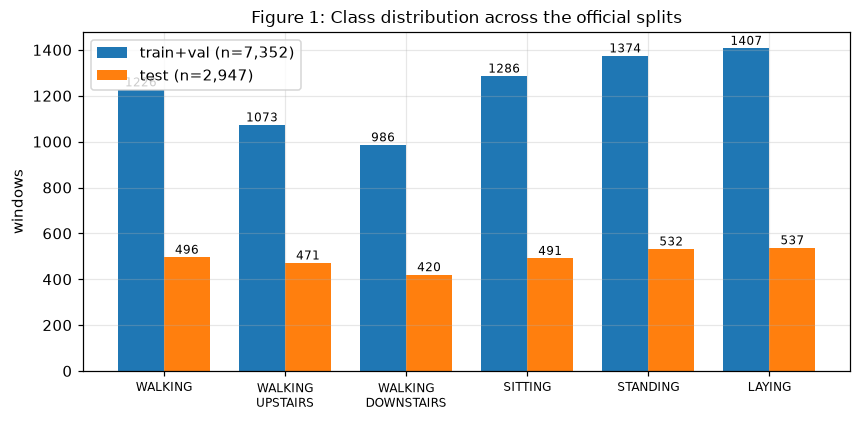


train+val imbalance ratio (largest/smallest): 1.43x
  largest : LAYING (1407)
  smallest: WALKING_DOWNSTAIRS (986)


In [8]:
# author: Ahmad Abbas
counts_tr = np.bincount(y_trainval, minlength=N_CLASSES)
counts_te = np.bincount(y_test, minlength=N_CLASSES)

fig, ax = plt.subplots(figsize=(9, 4))
idx = np.arange(N_CLASSES)
w = 0.38
ax.bar(idx - w / 2, counts_tr, w, label=f"train+val (n={counts_tr.sum():,})")
ax.bar(idx + w / 2, counts_te, w, label=f"test (n={counts_te.sum():,})")
for i, (a, b) in enumerate(zip(counts_tr, counts_te)):
    ax.text(i - w / 2, a + 15, str(a), ha="center", fontsize=8)
    ax.text(i + w / 2, b + 15, str(b), ha="center", fontsize=8)
ax.set_xticks(idx)
ax.set_xticklabels([a.replace("_", "\n") for a in ACTIVITIES], fontsize=8)
ax.set_ylabel("windows")
ax.set_title("Figure 1: Class distribution across the official splits")
ax.legend()
savefig(fig, 1, "class_distribution")
plt.show()

ratio = counts_tr.max() / counts_tr.min()
print(f"\ntrain+val imbalance ratio (largest/smallest): {ratio:.2f}x")
print(f"  largest : {ACTIVITIES[counts_tr.argmax()]} ({counts_tr.max()})")
print(f"  smallest: {ACTIVITIES[counts_tr.argmin()]} ({counts_tr.min()})")

**Interpretation.** The imbalance ratio is about 1.4:1 — the largest class has
roughly 40% more windows than the smallest, and the same shape appears in both
splits. This is mild. A naive classifier that always predicted the majority
class would reach only about 19% accuracy, not the 90%+ that severe imbalance
produces.

**Decision:** train with plain unweighted `CrossEntropyLoss`. Class weighting
would add a hyperparameter to defend for a problem the data does not have.

This does **not** mean accuracy is a safe metric here. It means the reason to
distrust accuracy is a different one — errors turn out to concentrate in a
single confusable pair, which figure 3 predicts and section 8.0 confirms. A
model can score well overall while failing systematically on one class, and
accuracy alone will not show it.

### 3.2 What each activity looks like

One representative window per activity. We plot body acceleration magnitude
(gravity removed, so this is motion only) alongside gyroscope magnitude
(rotation), reducing the nine channels to two interpretable quantities.

saved figures\fig02_example_windows.png


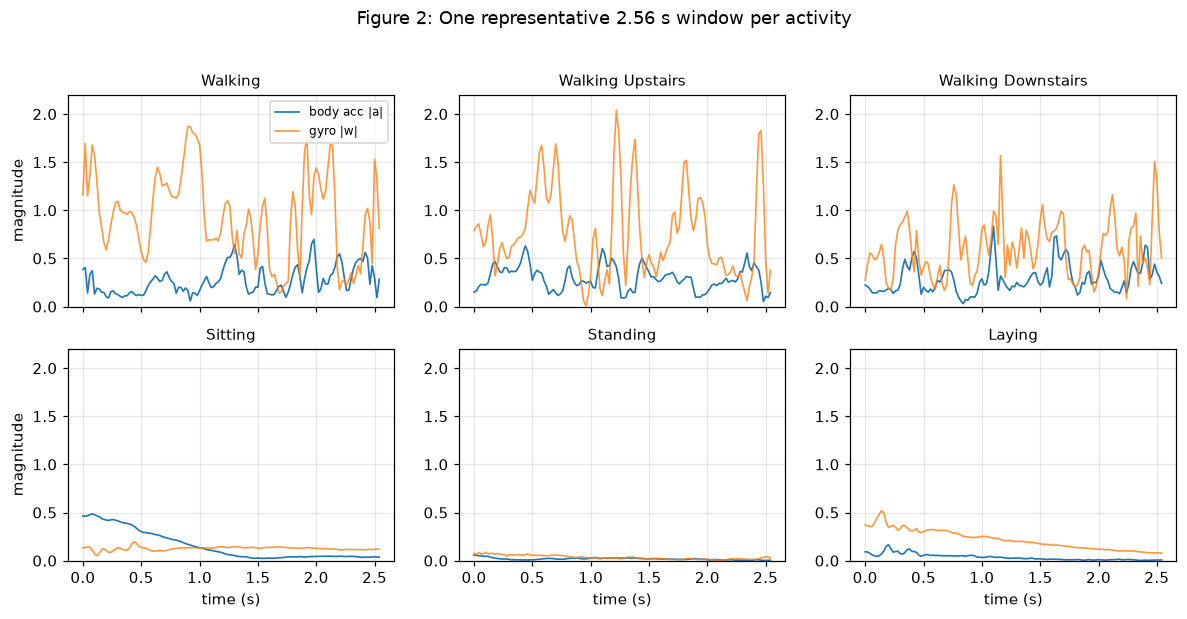

In [9]:
# author: Ahmad Abbas
def magnitude(X, start):
    """Euclidean magnitude of the 3-axis group beginning at channel `start`."""
    return np.linalg.norm(X[:, start:start + 3], axis=1)

body_mag_tr = magnitude(X_trainval, 0)    # body_acc  x,y,z -> channels 0:3
gyro_mag_tr = magnitude(X_trainval, 3)    # body_gyro x,y,z -> channels 3:6

t = np.arange(WINDOW_LEN) / SAMPLING_HZ

fig, axes = plt.subplots(2, 3, figsize=(13, 5.5), sharex=True)
for k, ax in enumerate(axes.ravel()):
    i = np.flatnonzero(y_trainval == k)[0]          # first window of this class
    ax.plot(t, body_mag_tr[i], lw=1.1, label="body acc |a|")
    ax.plot(t, gyro_mag_tr[i], lw=1.1, alpha=0.8, label="gyro |w|")
    ax.set_title(ACTIVITIES[k].replace("_", " ").title(), fontsize=10)
    ax.set_ylim(0, 2.2)
    if k >= 3:
        ax.set_xlabel("time (s)")
    if k % 3 == 0:
        ax.set_ylabel("magnitude")
axes[0, 0].legend(fontsize=8, loc="upper right")
fig.suptitle("Figure 2: One representative 2.56 s window per activity", y=1.02)
savefig(fig, 2, "example_windows")
plt.show()

**Interpretation.** Two regimes are visible by eye.

The three walking activities show strong, roughly periodic oscillation in both
acceleration and rotation — each peak is a footstep. The three static postures
are nearly flat lines close to zero: sitting, standing and laying all involve
almost no body acceleration and almost no rotation.

Plotted this way, **sitting, standing and laying are almost indistinguishable
from one another.** That is the central difficulty of this problem, and it is
not a rendering artefact — these channels genuinely do not separate the static
classes. Something else has to, which is what figure 3 looks for.

### 3.3 What actually separates the classes

Figure 2 suggests two quantities worth measuring per window:

- **Dynamic energy** — the standard deviation of body acceleration magnitude
  within the window. High while moving, near zero while still.
- **Orientation** — the mean gravity vector. Gravity is recoverable as
  `total_acc − body_acc`, and its direction tells us how the device was tilted,
  which is a proxy for body posture.

Orientation is the only thing that can separate the static postures, since by
definition they have no motion to measure.

saved figures\fig03_separability.png


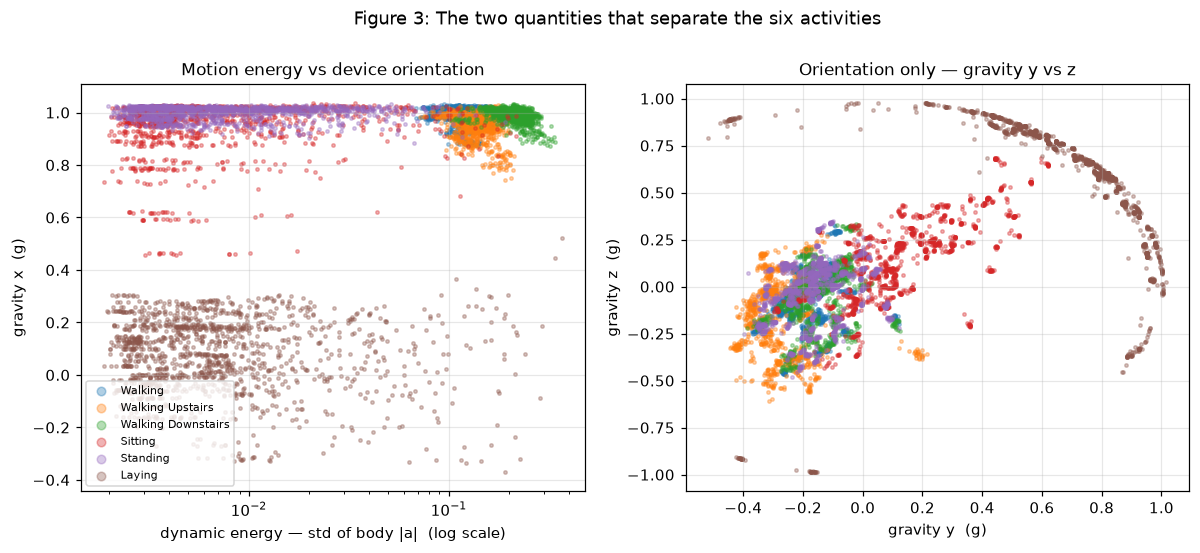

In [10]:
# author: Ahmad Abbas
gravity_tr = X_trainval[:, 6:9] - X_trainval[:, 0:3]     # total_acc - body_acc
grav_mean_tr = gravity_tr.mean(axis=2)                   # (n, 3) per-window mean
dynamic_energy_tr = body_mag_tr.std(axis=1)              # (n,)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
colors = plt.cm.tab10(np.linspace(0, 1, 10))

for k in range(N_CLASSES):
    m = y_trainval == k
    ax1.scatter(dynamic_energy_tr[m], grav_mean_tr[m, 0], s=5, alpha=0.35,
                color=colors[k], label=ACTIVITIES[k].replace("_", " ").title())
ax1.set_xscale("log")
ax1.set_xlabel("dynamic energy — std of body |a|  (log scale)")
ax1.set_ylabel("gravity x  (g)")
ax1.set_title("Motion energy vs device orientation")
ax1.legend(fontsize=7, markerscale=2.5, loc="lower left")

for k in range(N_CLASSES):
    m = y_trainval == k
    ax2.scatter(grav_mean_tr[m, 1], grav_mean_tr[m, 2], s=5, alpha=0.35, color=colors[k])
ax2.set_xlabel("gravity y  (g)")
ax2.set_ylabel("gravity z  (g)")
ax2.set_title("Orientation only — gravity y vs z")

fig.suptitle("Figure 3: The two quantities that separate the six activities", y=1.02)
savefig(fig, 3, "separability")
plt.show()

In [11]:
# author: Ahmad Abbas
rows = []
for k in range(N_CLASSES):
    m = y_trainval == k
    g = grav_mean_tr[m].mean(axis=0)
    rows.append({
        "activity": ACTIVITIES[k],
        "dyn_energy": dynamic_energy_tr[m].mean(),
        "grav_x": g[0], "grav_y": g[1], "grav_z": g[2],
    })
summary = pd.DataFrame(rows).set_index("activity").round(3)
print(summary.to_string())

# How far apart are the static postures in orientation space?
static = {a: summary.loc[a, ["grav_x", "grav_y", "grav_z"]].to_numpy(float)
          for a in ("SITTING", "STANDING", "LAYING")}
print("\nEuclidean distance between static postures in gravity space (g):")
for a, b in (("SITTING", "STANDING"), ("SITTING", "LAYING"), ("STANDING", "LAYING")):
    print(f"  {a:8} <-> {b:8} {np.linalg.norm(static[a] - static[b]):.3f}")

dyn = summary["dyn_energy"]
print(f"\nclass-mean dynamic energy:"
      f" moving {dyn.iloc[:3].min():.4f}-{dyn.iloc[:3].max():.4f}"
      f"  vs static {dyn.iloc[3:].min():.4f}-{dyn.iloc[3:].max():.4f}"
      f"   ({dyn.iloc[:3].min() / dyn.iloc[3:].max():.0f}x gap between means)")

# Class means are far apart, but do the individual windows actually separate?
moving = dynamic_energy_tr[y_trainval < 3]
static = dynamic_energy_tr[y_trainval >= 3]
n_above = int((static > moving.min()).sum())
print(f"\nper-window ranges (not means):")
print(f"  moving: {moving.min():.4f} - {moving.max():.4f}")
print(f"  static: {static.min():.4f} - {static.max():.4f}")
print(f"  static windows exceeding the quietest moving window: "
      f"{n_above}/{len(static)} ({100 * n_above / len(static):.1f}%)")

                    dyn_energy  grav_x  grav_y  grav_z
activity                                              
WALKING                  0.125   0.996  -0.181  -0.069
WALKING_UPSTAIRS         0.142   0.953  -0.268  -0.151
WALKING_DOWNSTAIRS       0.212   0.989  -0.149  -0.057
SITTING                  0.013   0.952   0.141   0.154
STANDING                 0.011   1.001  -0.164  -0.032
LAYING                   0.016   0.073   0.650   0.560

Euclidean distance between static postures in gravity space (g):
  SITTING  <-> STANDING 0.361
  SITTING  <-> LAYING   1.094
  STANDING <-> LAYING   1.369

class-mean dynamic energy: moving 0.1250-0.2120  vs static 0.0110-0.0160   (8x gap between means)

per-window ranges (not means):
  moving: 0.0584 - 0.3391
  static: 0.0019 - 0.3686
  static windows exceeding the quietest moving window: 166/4067 (4.1%)


**Interpretation.** Three findings, each with a consequence.

**1. Moving versus still is easy, but not perfectly.** The class *means* differ
by roughly an order of magnitude — around 0.13–0.21 for the walking activities
against 0.011–0.016 for the static ones.

The per-window ranges tell a more careful story: the distributions overlap at
the tails, with about 4% of static windows registering more energy than the
quietest moving window. Those are most likely windows containing a small
postural adjustment — a shift in the chair, a lean. So while the boundary is
easy on average, we should expect a handful of static-to-moving errors rather
than none, and section 9.0 checks whether the misclassified windows look like
this.

**2. Sitting and standing are the hard pair — and we can say how hard.** In
gravity space, sitting and standing sit about **0.36 g** apart, while sitting and
laying are about **1.09 g** apart: three times further. Laying tips the device
almost onto its side (gravity x drops from ≈1.0 to ≈0.07), an unmistakable
signature. Sitting and standing differ only by the modest forward tilt of the
waist when seated, and the right-hand panel shows their clouds genuinely
overlapping.

This is a concrete, falsifiable prediction: **the confusion matrix in section
8.0 should show its largest off-diagonal mass between sitting and standing.**
We will check it there.

**3. `total_acc` is load-bearing.** Orientation is computed from
`total_acc − body_acc`. Drop `total_acc` and the gravity component goes with it,
leaving nothing to distinguish three of the six classes. This is why section
2.0 keeps all nine channels despite the algebraic redundancy.

**Decision (§4.2):** standardise **per channel across the whole training set**,
never per window. Per-window normalisation subtracts each window's own mean,
which removes exactly the constant gravity offset that carries orientation. It
is a common default and it would silently destroy the only signal separating
sitting, standing and laying.

### 3.4 Dominant timescale

A convolutional filter can only detect a pattern that fits inside its receptive
field. To size the network we need to know the timescale of the structure it
must capture, so we take the magnitude spectrum of body acceleration and find
the dominant frequency per activity.

At 50 Hz over 128 samples the resolution is 50/128 ≈ 0.39 Hz, with a Nyquist
limit of 25 Hz. The DC bin is removed first — we want periodicity, not mean
level.

saved figures\fig04_frequency_spectra.png


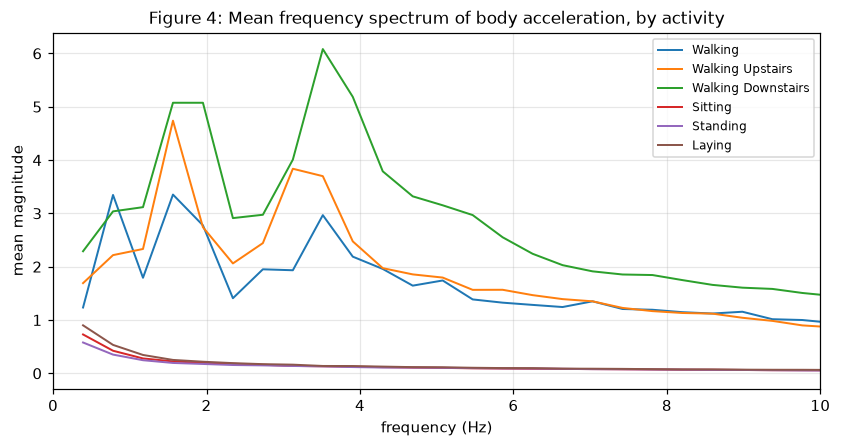

activity                peak Hz  period s  period in samples
WALKING                    1.56      0.64                 32
WALKING_UPSTAIRS           1.56      0.64                 32
WALKING_DOWNSTAIRS         3.52      0.28                 14
SITTING                    0.39      2.56                128
STANDING                   0.39      2.56                128
LAYING                     0.39      2.56                128


In [12]:
# author: Ahmad Abbas
freqs = np.fft.rfftfreq(WINDOW_LEN, d=1 / SAMPLING_HZ)
centred = body_mag_tr - body_mag_tr.mean(axis=1, keepdims=True)   # drop DC
spectra = np.abs(np.fft.rfft(centred, axis=1))

fig, ax = plt.subplots(figsize=(9, 4.2))
peaks = {}
for k in range(N_CLASSES):
    mean_spec = spectra[y_trainval == k].mean(axis=0)
    ax.plot(freqs[1:], mean_spec[1:], lw=1.3, color=colors[k],
            label=ACTIVITIES[k].replace("_", " ").title())
    peaks[ACTIVITIES[k]] = freqs[1:][mean_spec[1:].argmax()]
ax.set_xlim(0, 10)
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("mean magnitude")
ax.set_title("Figure 4: Mean frequency spectrum of body acceleration, by activity")
ax.legend(fontsize=8)
savefig(fig, 4, "frequency_spectra")
plt.show()

print(f"{'activity':22} {'peak Hz':>8} {'period s':>9} {'period in samples':>18}")
for a, f in peaks.items():
    print(f"{a:22} {f:8.2f} {1 / f:9.2f} {SAMPLING_HZ / f:18.0f}")

**Interpretation.** Walking and walking upstairs peak near **1.56 Hz** — a
period of 0.64 s, or **32 samples**. Walking downstairs peaks higher, near
3.5 Hz (about 14 samples), consistent with the quicker, harder footfalls of
descending. The static postures show no peak at all: their maximum sits in the
lowest resolvable bin, which is the spectrum's way of saying "no periodicity
here".

**Decision (§5.1):** the network needs a receptive field of **at least 32
samples** for a filter to see one complete gait cycle. This sets the depth.
With kernel size 5 and 2× pooling between blocks, two convolutional blocks
reach a receptive field of 16 samples — enough for a downstairs step, too short
for a walking stride. A third block extends it to 36. That is why the baseline
in section 5.0 has three convolutional blocks rather than two: the number comes
from this measurement, not from a default.

### 3.5 Window overlap, and why it dictates the split

The dataset documentation states that windows were cut with 50% overlap. That
has a direct consequence for how we are allowed to split the data, so rather
than taking it on trust we verify it on the array itself.

If the claim holds, the second half of one window is byte-for-byte the first
half of the next.

windows 0 and 1: subject 1, STANDING
second half of window 0 == first half of window 1: True
max absolute difference over the shared region: 0.00e+00
saved figures\fig05_window_overlap.png


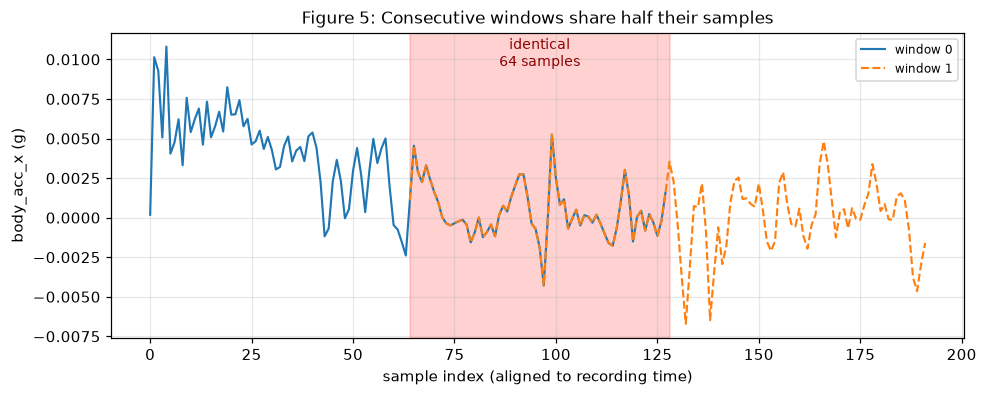

In [13]:
# author: Ahmad Abbas
# Find the first pair of consecutive rows from the same subject and activity.
i = next(j for j in range(len(y_trainval) - 1)
         if subj_trainval[j] == subj_trainval[j + 1] and y_trainval[j] == y_trainval[j + 1])

a, b = X_trainval[i, 0], X_trainval[i + 1, 0]        # body_acc_x of each window
shared = np.allclose(a[64:], b[:64], atol=1e-6)
print(f"windows {i} and {i + 1}: subject {subj_trainval[i]}, "
      f"{ACTIVITIES[y_trainval[i]]}")
print(f"second half of window {i} == first half of window {i + 1}: {shared}")
print(f"max absolute difference over the shared region: "
      f"{np.abs(a[64:] - b[:64]).max():.2e}")

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(np.arange(128), a, lw=1.4, label=f"window {i}")
ax.plot(np.arange(64, 192), b, lw=1.4, ls="--", label=f"window {i + 1}")
ax.axvspan(64, 128, alpha=0.18, color="red")
ax.text(96, ax.get_ylim()[1] * 0.82, "identical\n64 samples",
        ha="center", fontsize=9, color="darkred")
ax.set_xlabel("sample index (aligned to recording time)")
ax.set_ylabel("body_acc_x (g)")
ax.set_title("Figure 5: Consecutive windows share half their samples")
ax.legend(fontsize=8)
savefig(fig, 5, "window_overlap")
plt.show()

**Interpretation.** Confirmed exactly — the overlapping region is identical to
within floating-point tolerance.

This makes the obvious split strategy unusable. Shuffling all 7,352 windows and
taking a random 20% for validation would place window *i* in training and window
*i+1* in validation while **64 of their 128 readings are the same numbers**. The
validation score would then be partly a measure of memorisation, and it would
look good.

Subject identity makes it worse. Even windows that share no samples share a
person's gait: their stride length, their cadence, how they carry their weight.
A model can learn to recognise *this particular person walking* and score
highly, while being unable to recognise walking in anyone new. That is the
opposite of what a deployed activity monitor needs, since it meets users it has
never seen.

**Decision (§4.1):** split **by subject**, never by window. The official test
set is already subject-disjoint, so we preserve that and carve validation out of
the training subjects the same way. Section 7.0 quantifies what the shortcut
would have bought us, by training the same model under a random window split and
reporting both numbers side by side.

### 3.6 What the EDA decided

| Finding | Evidence | Consequence |
|---|---|---|
| Imbalance is mild (≈1.4:1) | Figure 1 | Unweighted `CrossEntropyLoss` (§5.2) |
| Static postures are flat in motion channels | Figure 2 | Motion alone cannot separate them |
| Orientation separates static postures; sitting/standing only 0.36 g apart | Figure 3 | Keep all 9 channels; expect sitting↔standing confusion (§8.0) |
| Per-window normalisation would erase the gravity offset | Figure 3 | Standardise per channel over the training set (§4.2) |
| Gait period ≈ 32 samples | Figure 4 | Receptive field ≥ 32 → three conv blocks (§5.1) |
| Consecutive windows share 64/128 samples | Figure 5 | Split by subject, not by window (§4.1) |

## 4.0 Preprocessing and splitting

Three steps, in an order that matters:

1. Split the 21 training subjects into train and validation **by subject**.
2. Compute normalisation statistics **on the training subjects only**, then
   apply them everywhere.
3. Wrap the arrays as tensors and `DataLoader`s.

Doing step 1 before step 2 is the whole point. Computing the mean and standard
deviation over all the data and splitting afterwards would let information from
the validation and test subjects influence how the training data is scaled — a
subtle leak that inflates results without ever looking like a bug.

Each step ends with an assertion. If a future edit reintroduces leakage, the
notebook fails loudly instead of quietly reporting a better number.

### 4.1 Subject-wise train/validation split

Section 3.5 established that splitting by window leaks. We hold out
`CONFIG["n_val_subjects"]` of the 21 training subjects entirely — every window
from a held-out subject goes to validation, and none of their data is ever
trained on.

The draw is seeded, so the split is reproducible and not cherry-picked. The
official test subjects are not touched here at all.

In [14]:
# author: Ahmad Abbas
train_subject_pool = np.unique(subj_trainval)
rng = np.random.default_rng(CONFIG["seed"])
val_subjects = np.sort(rng.choice(train_subject_pool,
                                  size=CONFIG["n_val_subjects"], replace=False))
train_subjects = np.setdiff1d(train_subject_pool, val_subjects)

train_mask = np.isin(subj_trainval, train_subjects)
val_mask = np.isin(subj_trainval, val_subjects)

X_train_raw, y_train, subj_train = X_trainval[train_mask], y_trainval[train_mask], subj_trainval[train_mask]
X_val_raw,   y_val,   subj_val   = X_trainval[val_mask],   y_trainval[val_mask],   subj_trainval[val_mask]
X_test_raw = X_test

print(f"train      {len(train_subjects):2d} subjects {train_subjects.tolist()}")
print(f"           {len(y_train):5d} windows")
print(f"validation {len(val_subjects):2d} subjects {val_subjects.tolist()}")
print(f"           {len(y_val):5d} windows")
print(f"test       {len(np.unique(subj_test)):2d} subjects {np.unique(subj_test).tolist()}")
print(f"           {len(y_test):5d} windows")

train      15 subjects [1, 5, 6, 7, 8, 11, 14, 16, 17, 21, 23, 25, 26, 27, 30]
            5276 windows
validation  6 subjects [3, 15, 19, 22, 28, 29]
            2076 windows
test        9 subjects [2, 4, 9, 10, 12, 13, 18, 20, 24]
            2947 windows


In [15]:
# author: Ahmad Abbas
# The guarantee this whole section exists to provide: no subject in two splits.
s_tr, s_va, s_te = set(subj_train.tolist()), set(subj_val.tolist()), set(subj_test.tolist())
assert not (s_tr & s_va), f"subject leak train/val: {s_tr & s_va}"
assert not (s_tr & s_te), f"subject leak train/test: {s_tr & s_te}"
assert not (s_va & s_te), f"subject leak val/test: {s_va & s_te}"
assert len(y_train) + len(y_val) == len(y_trainval), "windows lost in the split"
print("no subject appears in more than one split")
print(f"windows accounted for: {len(y_train)} + {len(y_val)} = {len(y_trainval)}")

no subject appears in more than one split
windows accounted for: 5276 + 2076 = 7352


#### Does the split stay balanced?

Holding out whole subjects means we cannot also stratify by class — we take
whichever activities those six people happened to perform. Worth checking that
the draw did not produce a lopsided validation set.

In [16]:
# author: Ahmad Abbas
dist = pd.DataFrame({
    "train": np.bincount(y_train, minlength=N_CLASSES),
    "val": np.bincount(y_val, minlength=N_CLASSES),
    "test": np.bincount(y_test, minlength=N_CLASSES),
}, index=ACTIVITIES)
pct = (dist / dist.sum() * 100).round(1)
print(pd.concat({"windows": dist, "% of split": pct}, axis=1).to_string())

# Per class, how much does its share differ across the three splits?
# (axis=1 compares a class across splits; axis=0 would compare classes within
#  a split, which measures imbalance rather than split consistency.)
spread = (pct.max(axis=1) - pct.min(axis=1)).round(1)
print("\nclass share, largest gap across the three splits (pp):")
print(spread.to_string())
print(f"\nworst case: {spread.max():.1f} percentage points ({spread.idxmax()})")
assert (dist > 0).all().all(), "a class is missing from a split"
print("every class is present in every split")

                   windows           % of split            
                     train  val test      train   val  test
WALKING                909  317  496       17.2  15.3  16.8
WALKING_UPSTAIRS       784  289  471       14.9  13.9  16.0
WALKING_DOWNSTAIRS     726  260  420       13.8  12.5  14.3
SITTING                908  378  491       17.2  18.2  16.7
STANDING               980  394  532       18.6  19.0  18.1
LAYING                 969  438  537       18.4  21.1  18.2

class share, largest gap across the three splits (pp):
WALKING               1.9
WALKING_UPSTAIRS      2.1
WALKING_DOWNSTAIRS    1.8
SITTING               1.5
STANDING              0.9
LAYING                2.9

worst case: 2.9 percentage points (LAYING)
every class is present in every split


**Interpretation.** All six activities appear in all three splits, and each
class holds a similar share of every split — the spread is a few percentage
points, which is what a subject-level draw over six people should produce.

The validation set is small enough that its estimates will be noisier than the
test set's. That is the price of an honest subject-wise split, and it is the
right trade: a noisy honest estimate is more useful for model selection than a
precise optimistic one.

### 4.2 Per-channel standardisation

Each channel is standardised to zero mean and unit variance using statistics
computed **across the training windows only**, then applied unchanged to
validation and test.

The channels arrive on different physical scales — acceleration in g,
angular velocity in rad/s — and the gyroscope varies roughly three to four times
as widely as body acceleration. Left alone, gradients from the wider channels
would dominate early training simply because their numbers are larger.

**The statistic is computed over `(windows, time)` per channel, not per window.**
Section 3.3 showed why: a per-window mean subtraction would remove each window's
own constant offset, and that offset *is* the gravity component carrying device
orientation — the only thing separating sitting, standing and laying. The
common default would quietly delete the signal for half the classes.

In [17]:
# author: Ahmad Abbas
# Mean and std per channel, over training windows and timesteps -> shape (1, 9, 1)
channel_mean = X_train_raw.mean(axis=(0, 2), keepdims=True)
channel_std = X_train_raw.std(axis=(0, 2), keepdims=True)

print(f"{'channel':14} {'mean':>9} {'std':>9}")
for i, ch in enumerate(CHANNELS):
    print(f"{ch:14} {channel_mean[0, i, 0]:9.4f} {channel_std[0, i, 0]:9.4f}")


def standardise(X):
    """Apply the training-set statistics. Never recomputed per split."""
    return (X - channel_mean) / channel_std


X_train = standardise(X_train_raw)
X_val = standardise(X_val_raw)
X_test_std = standardise(X_test_raw)

channel             mean       std
body_acc_x       -0.0007    0.1890
body_acc_y       -0.0003    0.1229
body_acc_z       -0.0001    0.1119
body_gyro_x       0.0017    0.3913
body_gyro_y      -0.0012    0.3950
body_gyro_z      -0.0004    0.2644
total_acc_x       0.8142    0.4021
total_acc_y       0.0231    0.3781
total_acc_z       0.0780    0.3645


In [18]:
# author: Ahmad Abbas
# Training data should now be centred; val/test should be close but not exact -
# if they were exact, the statistics would have been fitted on them.
print(f"train mean {X_train.mean():+.6f}  std {X_train.std():.6f}   (expect 0.0 / 1.0)")
print(f"val   mean {X_val.mean():+.6f}  std {X_val.std():.6f}")
print(f"test  mean {X_test_std.mean():+.6f}  std {X_test_std.std():.6f}")

assert abs(X_train.mean()) < 1e-5 and abs(X_train.std() - 1) < 1e-5, \
    "training data is not standardised"
assert abs(X_val.mean()) > 1e-9, \
    "validation mean is exactly zero - statistics were fitted on validation data"
print("\nstatistics were fitted on training subjects only")

train mean +0.000000  std 1.000000   (expect 0.0 / 1.0)
val   mean +0.005106  std 1.002634
test  mean -0.006037  std 0.956263

statistics were fitted on training subjects only


**Interpretation.** Training data is exactly centred, as it must be. Validation
and test are *near* zero mean but not exactly — and that small residual offset is
the evidence that the statistics were not fitted on them. If validation had come
out at exactly zero mean, it would mean we had normalised using its own
statistics, which is leakage. The second assertion fails in precisely that case.

Note that the gravity offset is preserved: `total_acc_x` had a training mean
near 0.80 g before scaling, and standardisation subtracts that same constant
from every window rather than from each window individually. The *relative*
orientation differences between postures survive intact.

### 4.3 Tensors and data loaders

The arrays are already `(n, 9, 128)` — channel-first, which is what `Conv1d`
expects — so they convert directly with no transposition.

Only the training loader shuffles. Validation and test are evaluated in a fixed
order so that repeated evaluations of the same model give identical numbers, and
a larger batch size is used there because no gradients are stored.

In [19]:
# author: Ahmad Abbas
def make_loader(X, y, batch_size, shuffle):
    ds = torch.utils.data.TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


set_seed(CONFIG["seed"])       # fix shuffling order for reproducibility
train_loader = make_loader(X_train, y_train, CONFIG["batch_size"], shuffle=True)
val_loader = make_loader(X_val, y_val, 256, shuffle=False)
test_loader = make_loader(X_test_std, y_test, 256, shuffle=False)

xb, yb = next(iter(train_loader))
print(f"batch: X {tuple(xb.shape)} {xb.dtype}   y {tuple(yb.shape)} {yb.dtype}")
print(f"batches per epoch: train {len(train_loader)}, "
      f"val {len(val_loader)}, test {len(test_loader)}")
assert xb.shape[1:] == (N_CHANNELS, WINDOW_LEN)
assert yb.min() >= 0 and yb.max() < N_CLASSES

batch: X (64, 9, 128) torch.float32   y (64,) torch.int64
batches per epoch: train 83, val 9, test 12


### 4.4 Preprocessing summary

| Step | Choice | Why |
|---|---|---|
| Representation | Raw 9 × 128 signals | Lets the network learn its own features (§2.0) |
| Missing values | None to handle | Dataset is complete; verified by shape checks |
| Split | By subject, seeded | Windows overlap 50% and carry personal gait (§3.5) |
| Validation | 6 of 21 training subjects | Held out entirely; test set untouched until §8.0 |
| Scaling | Per-channel z-score, fitted on train | Channels differ in unit and scale |
| Not done | Per-window normalisation | Would erase the gravity offset (§3.3) |
| Not done | Class weighting | Imbalance is only ≈1.4:1 (§3.1) |
| Not done | Augmentation | Deferred to §7.0, where it is tested as an experiment |

The data is now ready for modelling. Everything from here reads `train_loader`,
`val_loader` and `test_loader`, and no cell below section 4.0 touches the raw
arrays again.

## 5.0 Baseline model — 1-D convolutional network

The baseline is a small one-dimensional CNN: three convolution blocks, global
average pooling, dropout and a single linear layer. 44,422 parameters in total.

### Why a CNN suits this data

Section 3.2 showed that walking is a train of short, repeated shapes — each
footstep produces a similar spike, and it can land anywhere in the 2.56-second
window. A convolutional layer is built for exactly that:

- **Local patterns.** Each filter looks at a short stretch of time (5 samples,
  0.1 s) across all nine channels at once, so it can learn a shape like "sharp
  vertical acceleration with a simultaneous rotation".
- **Weight sharing.** The *same* filter slides along the whole window. A
  footstep detector learned at second 0.5 works unchanged at second 2.0, so the
  network does not need separate weights for every position. That is why the
  model is so small.
- **Hierarchy.** Stacking blocks lets later filters combine earlier ones —
  individual spikes into a stride, strides into a gait.

It is the simplest architecture that matches the structure of the data, which is
what a baseline should be. Section 6.0 adds an LSTM to test whether modelling the
*order* of events across the window improves on it.

### 5.1 Architecture

Every architectural value is read from `CONFIG`, and each block is a named
attribute (`block1`, `block2`, `block3`). A change to one specific layer is
therefore a one-line edit to that block's definition, and a change to all of
them is a one-value edit in `CONFIG`.

**What each component does**

| Component | Operation | Why it is here |
|---|---|---|
| `Conv1d(in, 64, k=5, padding=2)` | 64 filters, each `in × 5` weights, slid along time | Detects local patterns; `padding=2` keeps the length unchanged |
| Activation (ReLU by default) | `max(0, x)` element-wise | Non-linearity — without it, stacked layers collapse into one linear map |
| `MaxPool1d(2)` | Keeps the larger of each pair of time steps | Halves the length, tolerates small shifts, widens the next layer's view |
| `AdaptiveAvgPool1d(1)` | Averages each feature map over all time steps | One number per filter, independent of *where* in the window the pattern occurred |
| `Flatten` | `(64, 1)` → `(64,)` | Shape bookkeeping for the linear layer |
| `Dropout(p)` | During training, zeroes a random fraction `p` of the 64 features | Regularisation — see §5.2 |
| `Linear(64, 6)` | One weighted sum per class | Produces the six class scores (logits) |

**Why ReLU.** Its gradient is exactly 1 for any positive input, so the error
signal passes backwards through the layers without shrinking. Sigmoid and tanh
flatten out for large inputs, where their gradient approaches zero — stacked,
those small gradients multiply together and the early layers stop learning (the
*vanishing gradient* problem). ReLU is also a single comparison, which matters
on a CPU.

**Why global average pooling rather than flattening.** After three blocks each
of the 64 feature maps is 16 steps long. Flattening would feed 64 × 16 = 1,024
numbers to the linear layer — 6,150 weights where we use 390 — and each weight
would be tied to a specific *position* in the window. But the window start is
arbitrary: a footstep at step 3 and one at step 12 mean the same thing. Averaging
over time throws away position, which is exactly the information we do not want
the classifier to depend on.

**Why there is no softmax layer.** The model outputs raw scores (logits).
`CrossEntropyLoss` applies log-softmax internally, which is numerically more
stable than a separate softmax followed by a log. We apply softmax ourselves
only when we want to read probabilities.

In [20]:
# author: Khalifa Alhashel
ACTIVATIONS = {
    "relu": nn.ReLU,
    "leaky_relu": nn.LeakyReLU,
    "elu": nn.ELU,
    "tanh": nn.Tanh,
    "sigmoid": nn.Sigmoid,
}


class BaselineCNN(nn.Module):
    """Three conv blocks -> global average pool -> dropout -> linear."""

    def __init__(self, activation, dropout, width, kernel_size):
        super().__init__()
        act = ACTIVATIONS[activation]
        pad = kernel_size // 2            # "same" padding: length unchanged by the conv

        self.block1 = nn.Sequential(
            nn.Conv1d(N_CHANNELS, width, kernel_size, padding=pad), act(), nn.MaxPool1d(2))
        self.block2 = nn.Sequential(
            nn.Conv1d(width, width, kernel_size, padding=pad), act(), nn.MaxPool1d(2))
        self.block3 = nn.Sequential(
            nn.Conv1d(width, width, kernel_size, padding=pad), act(), nn.MaxPool1d(2))
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.flatten = nn.Flatten()
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(width, N_CLASSES)

    def forward(self, x):          # x: (batch, 9, 128)
        x = self.block1(x)         #    (batch, 64, 64)
        x = self.block2(x)         #    (batch, 64, 32)
        x = self.block3(x)         #    (batch, 64, 16)
        x = self.pool(x)           #    (batch, 64, 1)
        x = self.flatten(x)        #    (batch, 64)
        x = self.dropout(x)        #    (batch, 64)   active in training only
        return self.fc(x)          #    (batch, 6)    logits, one per class

#### Receptive field — honouring the §3.4 measurement

Section 3.4 measured the dominant walking period at **32 samples** and committed
to a network whose receptive field covers it. The receptive field is how many
input samples can influence a single unit. Each convolution widens it by
`(kernel − 1) × jump`, where *jump* is the spacing between neighbouring units in
the original input; each 2× pool widens it by one more step and doubles the jump
for every layer after it.

In [21]:
# author: Khalifa Alhashel
def receptive_field(kernel_size, n_blocks, pool=2):
    """Input samples visible to one unit after n (conv + pool) blocks."""
    rf, jump = 1, 1
    for _ in range(n_blocks):
        rf += (kernel_size - 1) * jump    # the convolution widens the view
        rf += (pool - 1) * jump           # the pooling widens it by one more step
        jump *= pool                      # and spaces later units twice as far apart
    return rf


GAIT_PERIOD = 32                          # samples, measured in section 3.4
k = CONFIG["kernel_size"]
print(f"kernel size {k}, 2x pooling per block\n")
print(f"{'blocks':>6} {'receptive field':>16} {'seconds':>8}  covers a gait cycle?")
for n in range(1, 5):
    rf = receptive_field(k, n)
    print(f"{n:>6} {rf:>16} {rf / SAMPLING_HZ:>8.2f}  {'yes' if rf >= GAIT_PERIOD else 'no'}"
          + ("   <- baseline" if n == 3 else ""))

kernel size 5, 2x pooling per block

blocks  receptive field  seconds  covers a gait cycle?
     1                6     0.12  no
     2               16     0.32  no
     3               36     0.72  yes   <- baseline
     4               76     1.52  yes


Three blocks is the smallest depth that sees a whole stride. Two blocks would
only reach 16 samples — enough for one footstep of the faster downstairs gait,
but not one full walking stride.

Note that the last line depends on `CONFIG["kernel_size"]`. If the kernel is
shrunk to 3, three blocks reach only 22 samples and the table says so. That is a
concrete, testable prediction for any live modification to the kernel size.

#### Layer table and a sample traced through the network

The table below is produced by passing one real validation window through the
model and recording what each layer outputs. A *forward hook* is a function
PyTorch calls immediately after a layer runs; we attach one to every layer to
record its output shape and parameter count. The table therefore shows what the
model actually does, not what we believe it does.

The traced window is the first walking window in the validation set.

In [22]:
# author: Khalifa Alhashel
def layer_table(model, x):
    """Output shape and parameter count for every layer, from one real forward pass."""
    rows = []

    def record(name):
        def hook(module, inputs, output):
            if isinstance(output, tuple):       # LSTM returns (output, state)
                output = output[0]
            rows.append({
                "layer": name,
                "type": type(module).__name__,
                "output shape": tuple(output.shape[1:]),     # drop the batch dimension
                "params": sum(p.numel() for p in module.parameters(recurse=False)),
            })
        return hook

    leaves = [(n, m) for n, m in model.named_modules() if not list(m.children())]
    handles = [m.register_forward_hook(record(n)) for n, m in leaves]
    model.eval()
    with torch.no_grad():
        out = model(x)
    for h in handles:
        h.remove()

    table = pd.DataFrame(rows)
    assert table["params"].sum() == sum(p.numel() for p in model.parameters())
    return table, out

In [23]:
# author: Khalifa Alhashel
sample_idx = int(np.flatnonzero(y_val == ACTIVITIES.index("WALKING"))[0])
sample = torch.from_numpy(X_val[sample_idx:sample_idx + 1])      # shape (1, 9, 128)

set_seed(CONFIG["seed"])
untrained = BaselineCNN(CONFIG["activation"], CONFIG["dropout"],
                        CONFIG["conv_width"], CONFIG["kernel_size"])
table, logits = layer_table(untrained, sample)

print(f"input: {tuple(sample.shape[1:])}   "
      f"(validation window {sample_idx}, true class {ACTIVITIES[y_val[sample_idx]]})\n")
print(table.to_string(index=False))
print(f"\ntotal parameters: {table['params'].sum():,}")

probs = torch.softmax(logits, dim=1)[0]
print("\nclass probabilities from the UNTRAINED network:")
for name, p in zip(ACTIVITIES, probs):
    print(f"  {name:20} {p:.3f}")

input: (9, 128)   (validation window 87, true class WALKING)

   layer              type output shape  params
block1.0            Conv1d    (64, 128)    2944
block1.1              ReLU    (64, 128)       0
block1.2         MaxPool1d     (64, 64)       0
block2.0            Conv1d     (64, 64)   20544
block2.1              ReLU     (64, 64)       0
block2.2         MaxPool1d     (64, 32)       0
block3.0            Conv1d     (64, 32)   20544
block3.1              ReLU     (64, 32)       0
block3.2         MaxPool1d     (64, 16)       0
    pool AdaptiveAvgPool1d      (64, 1)       0
 flatten           Flatten        (64,)       0
 dropout           Dropout        (64,)       0
      fc            Linear         (6,)     390

total parameters: 44,422

class probabilities from the UNTRAINED network:
  WALKING              0.172
  WALKING_UPSTAIRS     0.179
  WALKING_DOWNSTAIRS   0.177
  SITTING              0.184
  STANDING             0.134
  LAYING               0.153


**Following one window through the network.** The sample enters as 9 channels ×
128 time steps.

1. **Block 1** applies 64 filters, each spanning all 9 channels over 5 steps.
   Every output position is a weighted sum of 45 input numbers plus a bias,
   passed through ReLU. Padding keeps 128 steps; pooling halves them to 64.
   The 9 raw sensor channels have become 64 learned *feature* channels.
2. **Blocks 2 and 3** repeat this on the feature channels, halving the length
   to 32 then 16. Each of the 16 remaining positions now summarises a 36-sample
   stretch of the original signal.
3. **Global average pooling** averages each feature map over its 16 positions:
   64 numbers, each answering "how strongly did this pattern appear anywhere in
   the window?"
4. **Dropout** (training only) randomly silences some of those 64 numbers.
5. **The linear layer** turns 64 features into 6 class scores, and softmax turns
   those into probabilities.

**Checking the parameter count by hand.** A `Conv1d` has
`in_channels × out_channels × kernel + out_channels` parameters (weights plus one
bias per filter):

| Layer | Calculation | Parameters |
|---|---|---|
| block1 conv | 9 × 64 × 5 + 64 | 2,944 |
| block2 conv | 64 × 64 × 5 + 64 | 20,544 |
| block3 conv | 64 × 64 × 5 + 64 | 20,544 |
| fc | 64 × 6 + 6 | 390 |
| **Total** | | **44,422** |

Activations, pooling, flattening and dropout have no parameters. Almost all the
capacity sits in blocks 2 and 3, which is where the table shows it.

**The untrained output is close to uniform** — every class near 1/6 ≈ 0.167.
With random weights the network has no reason to prefer any class. Section 5.3
shows the same window again after training.

### 5.2 Training

#### The training algorithm

Each step of training runs the same four operations on one batch:

1. **Forward pass** — push the batch through the network to get logits.
2. **Loss** — measure how wrong those logits are against the true labels.
3. **Backward pass** — backpropagation applies the chain rule from the loss back
   through every layer, computing the gradient of the loss with respect to each
   of the 44,422 parameters: which direction to nudge each one to reduce the
   loss.
4. **Optimiser step** — move every parameter a small distance along that
   direction.

One pass over all training batches is an *epoch*. After each epoch the model is
scored on the validation subjects, with no gradient computation, to see whether
it is still improving on people it does not train on.

#### Configuration

| Setting | Value | Reason |
|---|---|---|
| Loss | Cross-entropy | Standard for single-label multi-class; §3.1 found no imbalance severe enough to weight it |
| Optimiser | Adam | See below |
| Learning rate | 1 × 10⁻³ | Adam's standard starting point; tuned in §7.0 |
| Batch size | 64 | Tuned in §7.0 |
| Max epochs | 30 | Upper bound; early stopping normally ends training sooner |
| Early stopping | Patience 8 on validation loss, best weights restored | See below |
| Seed | 42, set before every model is built | Identical initialisation and batch order on every run |

**Cross-entropy loss.** For each window it takes the softmax probability the
model assigned to the *correct* class and returns its negative logarithm. A
confident correct answer (p = 0.99) costs 0.01; a confident wrong answer, where
the correct class got p = 0.01, costs 4.6. The loss therefore punishes
confident mistakes far more than hesitant ones, and it remains informative even
when accuracy stops changing — a point that matters in §5.3.

**Why Adam rather than plain SGD.** Stochastic gradient descent moves every
parameter by the same learning rate times its gradient. Adam keeps two running
averages per parameter: of the gradient itself (momentum, which smooths out
noisy batches) and of its squared size (which it uses to scale each parameter's
step individually). Parameters with consistently small gradients take larger
steps and vice versa. In practice Adam converges quickly with little tuning,
which suits a small project with limited time for tuning.

If `CONFIG["optimizer"]` is switched to `"sgd"` at the same learning rate,
expect **visibly slower convergence**: SGD with momentum usually needs a learning
rate around ten times larger to train at a comparable pace. That is a prediction
to state before running it, not a sign of a bug.

**Why batch size 64.** Each step's gradient is estimated from 64 windows. Smaller
batches give noisier estimates (which can help generalisation but make
training erratic) and more steps per epoch; larger batches give smoother
estimates and fewer, cheaper-per-sample steps. 64 is a conventional middle
value; §7.0 tests the alternatives.

In [24]:
# author: Khalifa Alhashel
def make_loss(name):
    if name == "cross_entropy":
        return nn.CrossEntropyLoss()
    if name == "weighted_cross_entropy":
        # Inverse-frequency class weights: each class contributes equally in total.
        counts = np.bincount(y_train, minlength=N_CLASSES)
        weights = torch.tensor(len(y_train) / (N_CLASSES * counts), dtype=torch.float32)
        return nn.CrossEntropyLoss(weight=weights.to(device))
    raise ValueError(f"unknown loss: {name}")


def make_optimizer(name, params, lr):
    if name == "adam":
        return torch.optim.Adam(params, lr=lr)
    if name == "sgd":
        return torch.optim.SGD(params, lr=lr, momentum=0.9)
    if name == "rmsprop":
        return torch.optim.RMSprop(params, lr=lr)
    raise ValueError(f"unknown optimizer: {name}")

In [25]:
# author: Khalifa Alhashel
def augment_batch(xb, noise_std=0.05, scale_std=0.1):
    """Jitter and scaling: small random perturbations of a training batch.

    Each channel of each window is multiplied by a random factor near 1
    (scaling), then Gaussian noise is added to every reading (jitter).
    Off by default; tested as an experiment in section 7.4.
    """
    scale = 1 + scale_std * torch.randn(xb.shape[0], xb.shape[1], 1, device=xb.device)
    return xb * scale + noise_std * torch.randn_like(xb)


def run_epoch(model, loader, loss_fn, optimizer=None, augment=False):
    """One pass over `loader`. Trains if an optimizer is given, otherwise evaluates.

    Returns the mean loss and the accuracy over every window in the loader.
    """
    training = optimizer is not None
    model.train(training)                 # switches dropout on (train) or off (eval)
    total_loss, correct, seen = 0.0, 0, 0

    with torch.set_grad_enabled(training):   # no gradient bookkeeping when evaluating
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            if training and augment:
                xb = augment_batch(xb)           #    training batches only, never evaluation
            logits = model(xb)                   # 1. forward pass
            loss = loss_fn(logits, yb)           # 2. loss
            if training:
                optimizer.zero_grad()            #    clear last step's gradients
                loss.backward()                  # 3. backpropagation
                optimizer.step()                 # 4. parameter update
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            seen += len(yb)

    return total_loss / seen, correct / seen

#### Overfitting control — where it lives in the code

Two mechanisms, in two places:

1. **Dropout** — the `self.dropout` layer in `BaselineCNN` (§5.1), with its rate
   set by `CONFIG["dropout"]`. During training it zeroes a random 30% of the 64
   pooled features on every step and scales the survivors up by 1/0.7 so their
   expected sum is unchanged. The classifier cannot rely on any single feature
   being present, so it has to spread the evidence across many — which is
   another way of saying it cannot memorise one narrow cue per training window.
   `model.eval()` turns dropout off, so evaluation always uses the full network.

2. **Early stopping** — the block in `train_model` below that compares each
   epoch's validation loss with the best so far. Validation loss is measured on
   subjects the model never trains on, so when it stops falling while training
   loss keeps falling, the model has started fitting details specific to the
   training subjects. Training stops after `CONFIG["patience"]` epochs without
   improvement, and **the weights from the best epoch are restored**, not the
   weights from the last one.

A third option, **data augmentation**, is available but off by default
(`CONFIG["augment"]`). Section 7.4 tests whether it helps.

The training data loader is built *inside* `train_model` from
`config["batch_size"]`, so changing the batch size in `CONFIG` takes effect on
the next training run without re-running section 4.

In [26]:
# author: Khalifa Alhashel
def train_model(model, config, train_data, val_data, verbose=True):
    """Train with early stopping on validation loss; restore the best weights.

    train_data, val_data : (X, y) numpy arrays, already standardised
    Returns a history dict of per-epoch losses and accuracies.
    """
    model = model.to(device)
    train_loader = make_loader(*train_data, config["batch_size"], shuffle=True)
    val_loader = make_loader(*val_data, 256, shuffle=False)
    loss_fn = make_loss(config["loss"])
    optimizer = make_optimizer(config["optimizer"], model.parameters(), config["learning_rate"])

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_loss, best_epoch, best_state = float("inf"), 0, None
    start = time.time()

    for epoch in range(1, config["epochs"] + 1):
        train_loss, train_acc = run_epoch(model, train_loader, loss_fn, optimizer,
                                          augment=config["augment"])
        val_loss, val_acc = run_epoch(model, val_loader, loss_fn)
        for key, value in zip(history, (train_loss, train_acc, val_loss, val_acc)):
            history[key].append(value)

        # --- early stopping ---------------------------------------------------
        improved = val_loss < best_val_loss
        if improved:
            best_val_loss, best_epoch = val_loss, epoch
            best_state = copy.deepcopy(model.state_dict())

        if verbose:
            print(f"epoch {epoch:2d}  train loss {train_loss:.4f} acc {train_acc:.4f}  |  "
                  f"val loss {val_loss:.4f} acc {val_acc:.4f}" + ("  *" if improved else ""))

        if epoch - best_epoch >= config["patience"]:
            if verbose:
                print(f"stopping: no val-loss improvement for {config['patience']} epochs")
            break

    model.load_state_dict(best_state)       # keep the best epoch, not the last one
    history["best_epoch"] = best_epoch
    history["seconds"] = time.time() - start
    if verbose:
        print(f"\nrestored weights from epoch {best_epoch} "
              f"(val loss {best_val_loss:.4f}, val acc {history['val_acc'][best_epoch - 1]:.4f})"
              f", {history['seconds']:.1f}s")
    return history

#### Training the baseline

The cell is self-contained: it seeds, builds a fresh model from `CONFIG`, trains
it and saves the weights. Re-running it after a `CONFIG` change retrains from
scratch and reproduces exactly. `*` marks each epoch that set a new best
validation loss.

In [27]:
# author: Khalifa Alhashel
set_seed(CONFIG["seed"])
baseline = BaselineCNN(
    activation=CONFIG["activation"],
    dropout=CONFIG["dropout"],
    width=CONFIG["conv_width"],
    kernel_size=CONFIG["kernel_size"],
)
baseline_history = train_model(baseline, CONFIG, (X_train, y_train), (X_val, y_val))

torch.save(baseline.state_dict(), MODEL_DIR / "baseline_cnn.pt")
print(f"saved {(MODEL_DIR / 'baseline_cnn.pt').relative_to(REPO)}")

epoch  1  train loss 0.8344 acc 0.6685  |  val loss 0.2188 acc 0.9451  *


epoch  2  train loss 0.1858 acc 0.9333  |  val loss 0.1716 acc 0.9513  *


epoch  3  train loss 0.1410 acc 0.9422  |  val loss 0.1729 acc 0.9557


epoch  4  train loss 0.1148 acc 0.9484  |  val loss 0.1619 acc 0.9610  *


epoch  5  train loss 0.1085 acc 0.9513  |  val loss 0.1605 acc 0.9663  *


epoch  6  train loss 0.1011 acc 0.9539  |  val loss 0.1795 acc 0.9668


... (3 outputs left out)

epoch 10  train loss 0.0880 acc 0.9592  |  val loss 0.2302 acc 0.9547


epoch 11  train loss 0.0900 acc 0.9572  |  val loss 0.2212 acc 0.9595


epoch 12  train loss 0.0841 acc 0.9589  |  val loss 0.2555 acc 0.9600


epoch 13  train loss 0.0819 acc 0.9615  |  val loss 0.2566 acc 0.9504
stopping: no val-loss improvement for 8 epochs

restored weights from epoch 5 (val loss 0.1605, val acc 0.9663), 9.1s
saved models\baseline_cnn.pt


### 5.3 Learning curves

Loss and accuracy per epoch, for the training and validation sets. The dashed
line marks the epoch whose weights early stopping kept; the shaded region is
everything trained after it and then discarded.

saved figures\fig06_baseline_curves.png


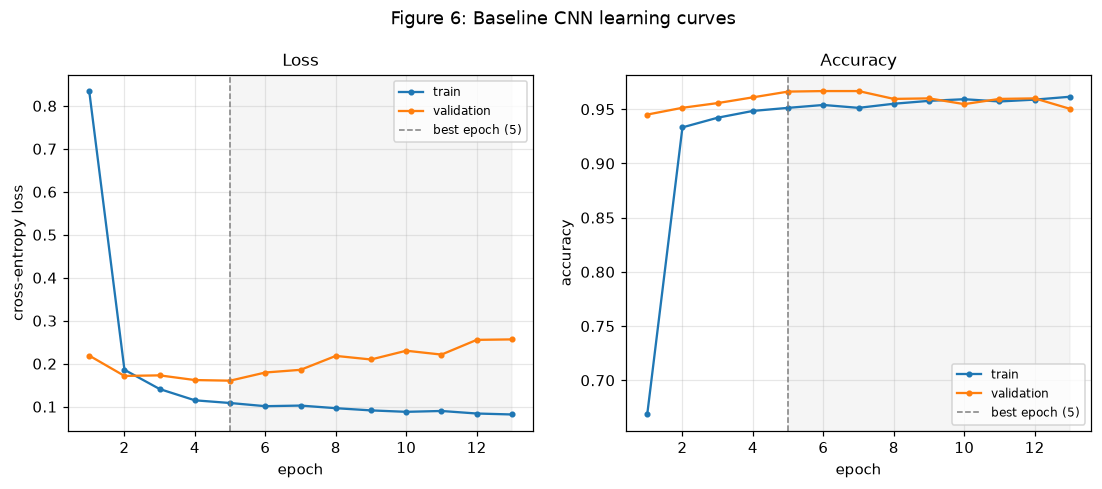

In [28]:
# author: Khalifa Alhashel
def plot_curves(history, title, number, slug):
    """Loss and accuracy per epoch, marking the epoch early stopping kept."""
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    best = history["best_epoch"]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, metric, label in ((ax1, "loss", "cross-entropy loss"), (ax2, "acc", "accuracy")):
        ax.plot(epochs, history[f"train_{metric}"], "o-", ms=3, label="train")
        ax.plot(epochs, history[f"val_{metric}"], "o-", ms=3, label="validation")
        ax.axvline(best, color="grey", ls="--", lw=1, label=f"best epoch ({best})")
        ax.axvspan(best, epochs[-1], color="grey", alpha=0.08)
        ax.set_xlabel("epoch")
        ax.set_ylabel(label)
        ax.legend(fontsize=8)
    ax1.set_title("Loss")
    ax2.set_title("Accuracy")
    fig.suptitle(f"Figure {number}: {title}", y=1.02)
    savefig(fig, number, slug)
    plt.show()


plot_curves(baseline_history, "Baseline CNN learning curves", 6, "baseline_curves")

**Interpretation.** Training loss falls on every epoch. Validation loss falls
for the first five epochs, reaches its minimum of **0.161 at epoch 5**, and then
climbs — by epoch 13 it is 0.257, about 60% higher than at its best, while
training loss has kept going down. That divergence is the signature of
**overfitting**: after epoch 5 the model is learning things that are true of the
15 training subjects but not of the 6 validation subjects. Early stopping
detected it, waited the 8-epoch patience to be sure it was not noise, stopped
at epoch 13 and restored the epoch-5 weights.

**Validation loss rises much more than validation accuracy falls.** Accuracy
drifts from 0.966 at the best epoch to 0.950 at epoch 13, while the loss climbs
by 60%. This is the cross-entropy property from §5.2 at work: accuracy only
asks whether the top class is right, but loss also asks *how confident* the
model was. As it overfits, the model grows more confident everywhere,
including on the validation windows it gets wrong, and those confident mistakes
are expensive. Validation loss is the more sensitive alarm, which is why early
stopping watches the loss rather than the accuracy.

**Overfitting arrives despite dropout.** Dropout at 0.3 is active throughout, yet
the model still starts to overfit after epoch 5. Dropout slows memorisation; it
does not prevent it. Section 7.0 measures how much each regulariser contributes
by removing it.

#### Why is validation accuracy *higher* than training accuracy early on?

The curves show validation accuracy above training accuracy for most of the
run — in epoch 1 by almost 28 points. This looks impossible if training data is
supposed to be easier, but two measurement effects explain it, and both are
checkable:

1. **Dropout is on while training accuracy is measured.** The training figure
   comes from a network with 30% of its features switched off; validation uses
   the full network.
2. **Training accuracy is an average over the epoch.** It includes the first
   batches of the epoch, processed by a model that has barely started learning.
   Validation is measured once, at the end, with the finished weights. The
   effect is largest in epoch 1, when the model changes the most.

If these two effects were the whole story, re-scoring the training set with the
final weights and dropout switched off should close the gap. The cell below
tests that.

In [29]:
# author: Khalifa Alhashel
eval_loss_fn = make_loss(CONFIG["loss"])
train_eval_loss, train_eval_acc = run_epoch(
    baseline, make_loader(X_train, y_train, 256, shuffle=False), eval_loss_fn)
val_eval_loss, val_eval_acc = run_epoch(
    baseline, make_loader(X_val, y_val, 256, shuffle=False), eval_loss_fn)

b = baseline_history["best_epoch"]
print(f"best epoch {b}, as recorded DURING training:")
print(f"  train acc {baseline_history['train_acc'][b - 1]:.4f}   "
      f"(dropout on, averaged across the epoch)")
print(f"  val   acc {baseline_history['val_acc'][b - 1]:.4f}")
print(f"\nsame weights, re-scored AFTER training in eval mode:")
print(f"  train acc {train_eval_acc:.4f}   loss {train_eval_loss:.4f}   (dropout off, final weights)")
print(f"  val   acc {val_eval_acc:.4f}   loss {val_eval_loss:.4f}")

best epoch 5, as recorded DURING training:
  train acc 0.9513   (dropout on, averaged across the epoch)
  val   acc 0.9663

same weights, re-scored AFTER training in eval mode:
  train acc 0.9572   loss 0.0953   (dropout off, final weights)
  val   acc 0.9663   loss 0.1605


**The prediction is only partly confirmed.** With dropout off and the final
weights, training accuracy rises from 0.9513 to 0.9572. The gap to validation
(0.9663) shrinks from 1.5 points to 0.9, but it does not close. Both measurement
effects are real, but they are not the whole explanation.

The loss tells a different story from the accuracy. In eval mode, training loss
is **0.095** against validation loss **0.161**, so by the measure the model was
actually trained on, it *does* fit the training subjects better. The training
set must therefore contain some windows the model gets wrong even though it
fits the rest well. The next cell looks for them.

In [30]:
# author: Khalifa Alhashel
# Where does the remaining gap come from? Score each training subject separately.
baseline.eval()
with torch.no_grad():
    train_pred = baseline(torch.from_numpy(X_train).to(device)).argmax(dim=1).cpu().numpy()

per_subject = pd.Series({
    int(s): (train_pred[subj_train == s] == y_train[subj_train == s]).mean()
    for s in np.unique(subj_train)
}).sort_values()
print("training accuracy per subject (eval mode), lowest first:")
print(per_subject.round(3).to_string())

wrong = train_pred != y_train
confusions = pd.Series([f"{ACTIVITIES[t]} -> {ACTIVITIES[p]}"
                        for t, p in zip(y_train[wrong], train_pred[wrong])])
print(f"\n{wrong.sum()} training windows misclassified; the confusions:")
print(confusions.value_counts().to_string())

hardest = per_subject.index[:2].tolist()
keep = ~np.isin(subj_train, hardest)
print(f"\ntraining accuracy excluding subjects {hardest}: "
      f"{(train_pred[keep] == y_train[keep]).mean():.4f}   (validation: {val_eval_acc:.4f})")

training accuracy per subject (eval mode), lowest first:
16    0.814
5     0.864
8     0.936
23    0.946
30    0.948
25    0.958
17    0.962
7     0.968
6     0.972
14    0.981
21    0.993
1     1.000
11    1.000
26    1.000
27    1.000

226 training windows misclassified; the confusions:
STANDING -> SITTING            163
SITTING -> STANDING             61
WALKING_UPSTAIRS -> WALKING      2

training accuracy excluding subjects [16, 5]: 0.9746   (validation: 0.9663)


**The remaining gap comes from two people.** 224 of the 226 misclassified
training windows are confusions between sitting and standing: 163 standing
windows read as sitting and 61 the other way. Every other class is essentially
perfect. The errors are also concentrated. Training subjects **16 (81.4%)** and
**5 (86.4%)** sit far below everyone else, while four training subjects score
100%. Without those two subjects, training accuracy is **97.5%**, above
validation.

The validation set shows the same confusion. Subjects 28 and 29 score about 90%.
But the other four validation subjects score 99.7–100%, so validation's overall
error rate comes out lower.

So the full answer to *"why is validation accuracy higher than training
accuracy?"* has three parts:

1. Dropout lowers the training figure while it is being recorded.
2. The training figure averages over an epoch in which the model was still
   improving.
3. Most of all, **which people ended up in which split.** Two of the fifteen
   training subjects stand in a way this model reads as sitting.

The third part is not a quirk to explain away. It is the §3.3 prediction
(sitting and standing are the confusable pair) showing up one section early. It
is also direct evidence for the §3.5 argument that individual people differ
enough to matter. If one person's posture can move their accuracy from 100% to
81%, then a model scored on people it has already seen would give a badly
optimistic picture of how it treats new ones.

#### The traced window, after training

In [31]:
# author: Khalifa Alhashel
baseline.eval()
with torch.no_grad():
    probs_trained = torch.softmax(baseline(sample), dim=1)[0]

print(f"validation window {sample_idx}, true class {ACTIVITIES[y_val[sample_idx]]}\n")
print(f"{'class':20} {'untrained':>10} {'trained':>9}")
for name, p0, p1 in zip(ACTIVITIES, probs, probs_trained):
    print(f"{name:20} {p0:10.3f} {p1:9.3f}")

validation window 87, true class WALKING

class                 untrained   trained
WALKING                   0.172     0.975
WALKING_UPSTAIRS          0.179     0.020
WALKING_DOWNSTAIRS        0.177     0.000
SITTING                   0.184     0.000
STANDING                  0.134     0.005
LAYING                    0.153     0.000


After training, the network gives the walking window a probability of **0.975**
for walking, up from 0.172 with random weights. Almost all of the rest goes to
walking upstairs (0.020), the class that §3.4 found shares walking's 1.56 Hz
stride frequency. Even the model's small uncertainty follows the structure of
the data. It hesitates between the two activities with the same rhythm, and
gives the static postures almost nothing.

#### Baseline summary

| | |
|---|---|
| Architecture | 3 × (Conv1d → ReLU → MaxPool) → global average pool → dropout → linear |
| Parameters | 44,422 |
| Receptive field | 36 samples (0.72 s), covering one 32-sample stride |
| Best epoch | 5 of 13 (early stopping, patience 8) |
| Validation | accuracy 0.9663, loss 0.1605 |
| Training time | roughly 10–20 s on CPU (wall-clock time varies with machine load; results do not) |
| Main weakness | Sitting ↔ standing confusion, concentrated in particular subjects |

Nearly every error so far is between two postures that differ only in a slight
tilt of the waist. Section 6.0 tests an alternative architecture that also
models the *order* of patterns across the window, rather than averaging them.

Whether that helps with this particular weakness is an open question, and it is
worth stating before the result is known. Sitting and standing differ mainly in
orientation, and orientation is present at every time step rather than carried
by any sequence. A sequence model may therefore improve the dynamic activities
without touching the static confusion. The comparison in sections 6.0 and 8.0
will show which it is.

## 6.0 Improved model — CNN-LSTM

### What changes, and what deliberately does not

The improved model keeps the baseline's three convolution blocks **exactly** —
same layers, same sizes, same receptive field of 36 samples. The only change is
at the point where the baseline applies global average pooling.

After block 3, both models hold 16 time steps, each described by 64 features.

- **The baseline averages them.** It treats the 16 steps as an unordered set,
  so "impact, quiet, impact, quiet" and "impact, impact, quiet, quiet" produce
  exactly the same average.
- **The CNN-LSTM reads them in order** with a recurrent layer, and classifies
  from what it has accumulated by the final step. It can tell those two
  sequences apart.

Holding everything else fixed is what makes the comparison *causal*. If the two
models behave differently, the cause is the one thing that differs between
them: averaging versus sequence modelling. Changing the front-end at the same
time, say by adding batch normalisation, would leave two candidate explanations
for any difference and no way to separate them.

### The hypothesis, stated before the result

The baseline summary at the end of §5.3 left one question open. Nearly all of the baseline's errors are
sitting ↔ standing, and those postures differ in *orientation*. Orientation is
present at every time step rather than carried by any sequence. So we expect the
LSTM to help, if at all, on the dynamic activities, where the order of events
within a stride carries information, and **not** on the static confusion.
Section 6.3 tests this.

### 6.1 Architecture

#### How an LSTM works

A plain recurrent network updates one hidden state at each step,
`h_t = tanh(W·x_t + U·h_(t−1) + b)`, so each new state depends on the input at
that step and on the state before it. Training it means backpropagating through
every step. The gradient gets multiplied by `U` and by tanh's derivative once
per step, so over many steps it shrinks towards zero (or grows without bound).
The network then cannot learn how early inputs relate to late ones.

A **Long Short-Term Memory** (LSTM) unit adds a second state, the **cell state**
`c_t`, which passes from step to step with only small, *additive* changes.
Three **gates** control it. Each gate is a sigmoid layer that outputs values
between 0 (closed) and 1 (open):

| Gate | Computes | Role |
|---|---|---|
| Forget `f_t` | σ(W_f·x_t + U_f·h_(t−1) + b_f) | How much of the old cell state to keep |
| Input `i_t` | σ(W_i·x_t + U_i·h_(t−1) + b_i) | How much new information to write |
| Candidate `g_t` | tanh(W_g·x_t + U_g·h_(t−1) + b_g) | The new information itself |
| Output `o_t` | σ(W_o·x_t + U_o·h_(t−1) + b_o) | How much of the cell state to expose |

The updates are:

- `c_t = f_t ⊙ c_(t−1) + i_t ⊙ g_t` (forget some, add some)
- `h_t = o_t ⊙ tanh(c_t)` (expose a filtered view)

`⊙` means element-wise multiplication. Because the cell state is updated by
addition rather than being squashed through a tanh at every step, the gradient
can flow backwards along it across many steps without vanishing. That is the
whole reason LSTMs exist.

#### How it is used here

- **Input sequence.** The 16 outputs of block 3. Each is a 64-feature summary of
  a 36-sample stretch, and consecutive steps are 8 samples (0.16 s) apart.
- **Hidden size.** `CONFIG["lstm_hidden"]` = 64, matching the conv width, so
  the classifier receives 64 features, as it does in the baseline.
- **Read-out.** The hidden state after the **last** step. By then the LSTM has
  read all 16 steps in order, so that single vector summarises the whole
  window, including the order in which things happened.
- **Direction.** Left to right only. A bidirectional LSTM would read the window
  both ways and double the recurrent parameters. For a 16-step sequence whose
  last state has already seen everything, it adds cost and something more to
  explain, with no clear benefit.

`CONFIG["activation"]` changes the convolution blocks only. The LSTM's internal
functions are fixed by its design: sigmoid for the gates, tanh for the
candidate and the output. They are not tunable.

**Why not a Transformer?** Self-attention would let every step look at every
other step directly. With only 16 steps the LSTM already sees the whole sequence
cheaply, and a Transformer would add positional encodings and attention heads,
plus considerably more parameters, to solve a problem this sequence length does
not have.

In [32]:
# author: Khalifa Alhashel
class CNNLSTM(nn.Module):
    """The baseline's three conv blocks, with an LSTM in place of global average pooling."""

    def __init__(self, activation, dropout, width, kernel_size, hidden):
        super().__init__()
        act = ACTIVATIONS[activation]
        pad = kernel_size // 2

        # Identical to BaselineCNN - the controlled part of the comparison.
        self.block1 = nn.Sequential(
            nn.Conv1d(N_CHANNELS, width, kernel_size, padding=pad), act(), nn.MaxPool1d(2))
        self.block2 = nn.Sequential(
            nn.Conv1d(width, width, kernel_size, padding=pad), act(), nn.MaxPool1d(2))
        self.block3 = nn.Sequential(
            nn.Conv1d(width, width, kernel_size, padding=pad), act(), nn.MaxPool1d(2))

        # The one change: read the 16 steps in order instead of averaging them.
        self.lstm = nn.LSTM(input_size=width, hidden_size=hidden, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, N_CLASSES)

    def forward(self, x):          # x: (batch, 9, 128)
        x = self.block1(x)         #    (batch, 64, 64)
        x = self.block2(x)         #    (batch, 64, 32)
        x = self.block3(x)         #    (batch, 64, 16)
        x = x.permute(0, 2, 1)     #    (batch, 16, 64)   one 64-feature vector per time step
        out, _ = self.lstm(x)      #    (batch, 16, 64)   hidden state after each step
        x = out[:, -1, :]          #    (batch, 64)       hidden state after the LAST step
        x = self.dropout(x)        #    (batch, 64)       active in training only
        return self.fc(x)          #    (batch, 6)        logits

#### Layer table

The same `layer_table` function as §5.1, tracing the same validation window.

In [33]:
# author: Khalifa Alhashel
set_seed(CONFIG["seed"])
untrained_lstm = CNNLSTM(CONFIG["activation"], CONFIG["dropout"], CONFIG["conv_width"],
                         CONFIG["kernel_size"], CONFIG["lstm_hidden"])
lstm_table, _ = layer_table(untrained_lstm, sample)

print(f"input: {tuple(sample.shape[1:])}\n")
print(lstm_table.to_string(index=False))
print(f"\ntotal parameters: {lstm_table['params'].sum():,}   "
      f"(baseline: {table['params'].sum():,})")

input: (9, 128)

   layer      type output shape  params
block1.0    Conv1d    (64, 128)    2944
block1.1      ReLU    (64, 128)       0
block1.2 MaxPool1d     (64, 64)       0
block2.0    Conv1d     (64, 64)   20544
block2.1      ReLU     (64, 64)       0
block2.2 MaxPool1d     (64, 32)       0
block3.0    Conv1d     (64, 32)   20544
block3.1      ReLU     (64, 32)       0
block3.2 MaxPool1d     (64, 16)       0
    lstm      LSTM     (16, 64)   33280
 dropout   Dropout        (64,)       0
      fc    Linear         (6,)     390

total parameters: 77,702   (baseline: 44,422)


**Reading the table.** The first nine rows are identical to the baseline's. Two
operations do not appear as rows because they are not layers: the `permute`
before the LSTM, and the `[:, -1, :]` selection after it. The permute swaps the
axes so the LSTM receives one 64-feature vector per time step, which is the
layout `batch_first=True` expects. The selection keeps only the final step's
hidden state, turning `(16, 64)` into `(64,)`.

**The LSTM's parameter count by hand.** PyTorch stores the weights of all four
gates side by side, which is where the factor of 4 comes from. With input size
I = 64 and hidden size H = 64:

| Tensor | Shape | Parameters |
|---|---|---|
| `weight_ih` (input → gates) | 4H × I = 256 × 64 | 16,384 |
| `weight_hh` (hidden → gates) | 4H × H = 256 × 64 | 16,384 |
| `bias_ih` | 4H | 256 |
| `bias_hh` | 4H | 256 |
| **LSTM total** | | **33,280** |

PyTorch keeps two bias vectors where the equations above have one. The two are
simply added together, so mathematically they are redundant. The layout matches
NVIDIA's cuDNN library, which PyTorch uses for fast LSTMs on GPUs.

**Model total:** 2,944 + 20,544 + 20,544 (conv blocks, as in the baseline) +
33,280 (LSTM) + 390 (fc) = **77,702**, 75% more than the baseline. The global
average pool it replaces had no parameters, so every extra weight is in the
LSTM. That matters when interpreting the comparison: the CNN-LSTM has more
capacity *and* order-awareness, and only a capacity-matched control could
separate the two. Section 7.0 addresses that by widening the baseline.

### 6.2 Training

Everything that is not architecture is held identical to the baseline:
the same `train_model` function, the same `CONFIG` (optimiser, learning rate,
batch size, loss, epoch limit and patience), the same seed and the same
subject-wise split. Any difference in results therefore comes from the model.

In [34]:
# author: Khalifa Alhashel
set_seed(CONFIG["seed"])
cnn_lstm = CNNLSTM(
    activation=CONFIG["activation"],
    dropout=CONFIG["dropout"],
    width=CONFIG["conv_width"],
    kernel_size=CONFIG["kernel_size"],
    hidden=CONFIG["lstm_hidden"],
)
cnn_lstm_history = train_model(cnn_lstm, CONFIG, (X_train, y_train), (X_val, y_val))

torch.save(cnn_lstm.state_dict(), MODEL_DIR / "cnn_lstm.pt")
print(f"saved {(MODEL_DIR / 'cnn_lstm.pt').relative_to(REPO)}")

epoch  1  train loss 0.9773 acc 0.5749  |  val loss 0.6181 acc 0.8266  *


epoch  2  train loss 0.3840 acc 0.8821  |  val loss 0.2097 acc 0.9441  *


epoch  3  train loss 0.1901 acc 0.9375  |  val loss 0.1386 acc 0.9629  *


epoch  4  train loss 0.1469 acc 0.9447  |  val loss 0.2590 acc 0.9080


epoch  5  train loss 0.1425 acc 0.9469  |  val loss 0.1495 acc 0.9509


epoch  6  train loss 0.1185 acc 0.9448  |  val loss 0.1443 acc 0.9528


epoch  7  train loss 0.1160 acc 0.9450  |  val loss 0.1392 acc 0.9586


epoch  8  train loss 0.1080 acc 0.9486  |  val loss 0.1666 acc 0.9547


epoch  9  train loss 0.1035 acc 0.9498  |  val loss 0.2063 acc 0.9374


epoch 10  train loss 0.1012 acc 0.9515  |  val loss 0.1878 acc 0.9480


epoch 11  train loss 0.0891 acc 0.9560  |  val loss 0.1618 acc 0.9538
stopping: no val-loss improvement for 8 epochs

restored weights from epoch 3 (val loss 0.1386, val acc 0.9629), 9.9s
saved models\cnn_lstm.pt


### 6.3 Learning curves and comparison with the baseline

saved figures\fig07_cnn_lstm_curves.png

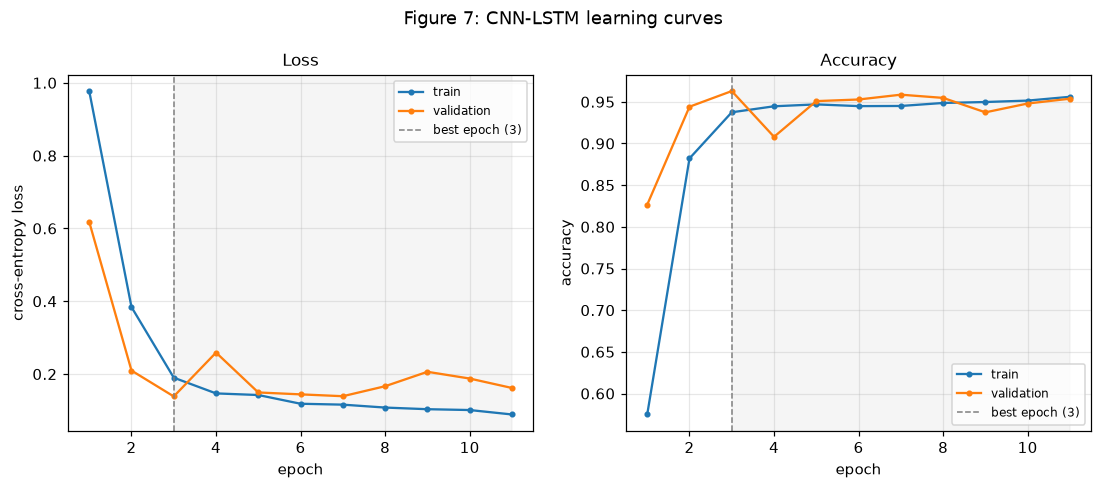

In [35]:
# author: Khalifa Alhashel
plot_curves(cnn_lstm_history, "CNN-LSTM learning curves", 7, "cnn_lstm_curves")

**Interpretation.** The CNN-LSTM starts more slowly than the baseline. After
the first epoch it reaches 57% training and 83% validation accuracy, against the
baseline's 67% and 95%. An extra randomly initialised layer now sits between the
convolutional features and the classifier, and the LSTM has to learn what to
carry forward before its final state is useful.

It catches up fast. Validation loss reaches its minimum of **0.139 at epoch 3**,
below the baseline's best of 0.161.

After that comes the same overfitting pattern as §5.3, only noisier. Training
loss keeps falling, to 0.089 by epoch 11. Validation loss jumps to 0.259 at
epoch 4, falls back to 0.139 at epoch 7, then drifts upwards. The minimum is
really a broad region around epochs 3–7 rather than one sharp point, and early
stopping kept the lowest value in it.

The epoch-4 spike, when validation accuracy dips to 0.908 for a single epoch,
shows this model's validation behaviour is less smooth from one epoch to the
next than the baseline's. That is one reason not to compare the two models on a
single run each. The next cell uses several seeds.

As in §5.3, validation accuracy sits above training accuracy in the early
epochs, for the same reasons.

#### Two helpers used from here on

`build_model` creates a fresh, untrained model of either architecture from a
config dictionary. `predict` returns the predicted class of every window.

In [36]:
# author: Khalifa Alhashel
def build_model(name, config):
    """A fresh, untrained model built from a config dict."""
    common = dict(activation=config["activation"], dropout=config["dropout"],
                  width=config["conv_width"], kernel_size=config["kernel_size"])
    if name == "baseline":
        return BaselineCNN(**common)
    if name == "cnn_lstm":
        return CNNLSTM(**common, hidden=config["lstm_hidden"])
    raise ValueError(f"unknown model: {name}")


def predict(model, X):
    """Predicted class index for every window in X (eval mode, no gradients)."""
    model.eval()
    with torch.no_grad():
        return model(torch.from_numpy(X).to(device)).argmax(dim=1).cpu().numpy()

#### Is the difference real, or seed luck?

One training run per model is one sample. A different seed changes the initial
weights and the order batches arrive in, and with it the final result. So
before crediting a difference to the architecture, both models are retrained
with four seeds, and we check whether the gap between them is larger than the
spread within each.

This loop trains eight models and takes one to two minutes on CPU. It is the
first of the notebook's slow multi-run studies, so it is also where the
live-demonstration warm-up stops: everything above this cell runs in under a
minute (see `README.md`).

In [37]:
# author: Khalifa Alhashel
seed_rows = []
for seed in [CONFIG["seed"], 0, 1, 2]:
    for name in ("baseline", "cnn_lstm"):
        set_seed(seed)
        history = train_model(build_model(name, CONFIG), CONFIG,
                              (X_train, y_train), (X_val, y_val), verbose=False)
        b = history["best_epoch"]
        seed_rows.append({"model": name, "seed": seed,
                          "val_loss": history["val_loss"][b - 1],
                          "val_acc": history["val_acc"][b - 1]})

seeds_df = pd.DataFrame(seed_rows)
print("best-epoch validation results per seed:\n")
print(seeds_df.pivot(index="seed", columns="model", values=["val_loss", "val_acc"]).round(4).to_string())
print("\nmean and standard deviation across the four seeds:\n")
print(seeds_df.groupby("model")[["val_loss", "val_acc"]].agg(["mean", "std"]).round(4).to_string())

best-epoch validation results per seed:

      val_loss           val_acc         
model baseline cnn_lstm baseline cnn_lstm
seed                                     
0       0.1429   0.1178   0.9566   0.9653
1       0.1939   0.1314   0.9552   0.9605
2       0.1359   0.1450   0.9644   0.9615
42      0.1605   0.1386   0.9663   0.9629

mean and standard deviation across the four seeds:

         val_loss         val_acc        
             mean     std    mean     std
model                                    
baseline   0.1583  0.0259  0.9606  0.0055
cnn_lstm   0.1332  0.0117  0.9625  0.0021


**Interpretation.** Three findings.

**1. Validation loss is lower for the CNN-LSTM, but not decisively.** Its mean
is 0.133 against the baseline's 0.158, about 16% lower, and it wins on three of
the four seeds. On seed 2 the baseline wins (0.136 vs 0.145). The gap between
the means (0.025) is about one standard deviation of the baseline's own spread,
so with four seeds the difference is *suggestive, not conclusive*. Section 7.5
also shows that about half of it comes from the CNN-LSTM's extra parameters
rather than from sequence modelling.

Lower cross-entropy at the same accuracy means that, on average, the model gives
more probability to the correct class. Its top choice is no more often right,
but its probabilities are more trustworthy. That matters for any deployment
that acts on confidence, for example flagging uncertain windows for review.

**2. Accuracy is indistinguishable.** The means are 0.9625 and 0.9606, 0.2
points apart, while the baseline's own seeds vary by ±0.55 points. Each model
wins on two seeds. A claim that the CNN-LSTM is *more accurate* would not
survive this table.

Seed 42 alone would actually have suggested the opposite, that the baseline is
more accurate (0.9663 vs 0.9629). A single run each would have got accuracy
wrong and loss right, with no way of telling which.

**3. The CNN-LSTM is more consistent.** Its standard deviation is less than half
the baseline's, for both loss (0.012 vs 0.026) and accuracy (0.0021 vs 0.0055).
Its result depends less on the luck of initialisation, which has practical value
for a model that would be retrained as more data arrives.

#### Side by side on validation, and whose errors are they?

The table uses the seed-42 models trained above. *Per-class accuracy* is the
fraction of each class's windows that were classified correctly, which is that
class's **recall**. Section 8.0 reports it formally on the test set; here it is
used on validation to compare the two models.

The second cell checks whether the two models get the *same* windows wrong. If
they share most of their errors, those errors come from the data rather than
from either architecture.

In [38]:
# author: Khalifa Alhashel
pred_base, pred_lstm = predict(baseline, X_val), predict(cnn_lstm, X_val)


def summarise(model, history, pred):
    """One model's validation results, formatted as text for display."""
    b = history["best_epoch"]
    row = {
        "parameters": f"{sum(p.numel() for p in model.parameters()):,}",
        "best epoch": str(b),
        "epochs run": str(len(history["val_loss"])),
        "train time (s)": f"{history['seconds']:.1f}",
        "val loss": f"{history['val_loss'][b - 1]:.4f}",
        "val accuracy": f"{history['val_acc'][b - 1]:.4f}",
    }
    for k, activity in enumerate(ACTIVITIES):
        row[f"recall {activity}"] = f"{(pred[y_val == k] == k).mean():.3f}"
    return row


comparison = pd.DataFrame({
    "Baseline CNN": summarise(baseline, baseline_history, pred_base),
    "CNN-LSTM": summarise(cnn_lstm, cnn_lstm_history, pred_lstm),
})
print(comparison.to_string())

                          Baseline CNN CNN-LSTM
parameters                      44,422   77,702
best epoch                           5        3
epochs run                          13       11
train time (s)                     9.1      9.9
val loss                        0.1605   0.1386
val accuracy                    0.9663   0.9629
recall WALKING                   1.000    0.991
recall WALKING_UPSTAIRS          1.000    0.993
recall WALKING_DOWNSTAIRS        1.000    0.992
recall SITTING                   0.897    0.897
recall STANDING                  0.921    0.921
recall LAYING                    1.000    1.000

In [39]:
# author: Khalifa Alhashel
wrong_base, wrong_lstm = pred_base != y_val, pred_lstm != y_val
both = wrong_base & wrong_lstm
print(f"misclassified validation windows:  baseline {wrong_base.sum()},  "
      f"CNN-LSTM {wrong_lstm.sum()},  both {both.sum()}\n")

print(f"{'class':20} {'baseline':>9} {'CNN-LSTM':>9} {'both':>6}")
for k, activity in enumerate(ACTIVITIES):
    m = y_val == k
    print(f"{activity:20} {(wrong_base & m).sum():9d} {(wrong_lstm & m).sum():9d} {(both & m).sum():6d}")

print("\nerrors made by BOTH models, by validation subject:")
for s in np.unique(subj_val):
    print(f"  subject {s:2d}: {(both & (subj_val == s)).sum():3d} of {(subj_val == s).sum()} windows")

misclassified validation windows:  baseline 70,  CNN-LSTM 77,  both 69

class                 baseline  CNN-LSTM   both
WALKING                      0         3      0
WALKING_UPSTAIRS             0         2      0
WALKING_DOWNSTAIRS           0         2      0
SITTING                     39        39     38
STANDING                    31        31     31
LAYING                       0         0      0

errors made by BOTH models, by validation subject:
  subject  3:   0 of 341 windows
  subject 15:   0 of 328 windows
  subject 19:   0 of 360 windows
  subject 22:   0 of 321 windows
  subject 28:  38 of 382 windows
  subject 29:  31 of 344 windows


**Interpretation.**

**The static classes are untouched, exactly as predicted.** Sitting recall is
0.897 and standing recall 0.921 for *both* models. The overlap goes deeper than
matching rates. The standing errors are the same 31 windows, 38 of the 39
sitting errors are shared, and 69 of the baseline's 70 errors are also made by
the CNN-LSTM.

**Every shared error comes from two people.** Subjects 28 and 29 account for all
69, which is about 10% of subject 28's windows and 9% of subject 29's. The other
four validation subjects produce no shared errors at all.

Two architectures that combine features in fundamentally different ways fail on
the same windows from the same two people. The cause therefore lies in those
people's data, not in either model. The likeliest explanation is that their
sitting and standing orientations lie close together, the §3.3 overlap made
concrete. Section 9.0 inspects these windows directly.

**The first half of the hypothesis was not supported.** We expected that
sequence modelling might help the dynamic activities. On validation it could
not. The baseline already classifies every walking window correctly, leaving no
room to improve, and the CNN-LSTM makes 7 errors there that the baseline does
not.

**What the CNN-LSTM offers** is a lower and more consistent validation loss,
meaning more trustworthy probabilities for the same top choice. **What it
costs** is 75% more parameters, plus a few extra errors on the dynamic classes
at this seed.

It is a genuinely close comparison. Which model to deploy is decided on the
held-out test set in section 8.0, not on the validation set that has already
been used to pick epochs and compare designs.

#### A limitation this surfaces

The model's accuracy is not uniform across people. For four of the six
validation subjects it is essentially perfect, and for two it misreads roughly
one window in ten. A system deployed to the public would behave like that for
some of its users, and no architecture change tested here moved it.

## 7.0 Hyperparameter experiments

Section 6.3 established something that governs this whole section: **retraining
the same model with a different seed changes its validation loss by about
0.026** (the baseline's standard deviation across four seeds). Any experiment
here is a single training run, so a difference smaller than that noise cannot
be attributed to the setting being tested.

Six experiments, each answering a question raised earlier in the notebook:

| § | Experiment | Question |
|---|---|---|
| 7.1 | One-at-a-time sweep of four hyperparameters | Are the defaults reasonable? |
| 7.2 | Re-running the best-looking result with more seeds | Was the sweep's winner real? |
| 7.3 | Removing dropout and early stopping | How much does each regulariser contribute? (§5.3) |
| 7.4 | Data augmentation | Does it help, and does it touch the static confusion? (§4.4) |
| 7.5 | A baseline widened to the CNN-LSTM's size | Is the CNN-LSTM's advantage just extra parameters? (§6.1) |
| 7.6 | A random window split | What would the leaky split have reported? (§3.5) |

The whole section trains 20 models and takes roughly five to seven minutes on
CPU.

In [40]:
# author: Khalifa Alhashel
def run_experiment(overrides, name="baseline", train_data=None, val_data=None):
    """Train a fresh model with CONFIG plus `overrides`. Returns (model, history)."""
    config = dict(CONFIG, **overrides)
    if train_data is None:
        train_data = (X_train, y_train)
    if val_data is None:
        val_data = (X_val, y_val)
    set_seed(config["seed"])
    model = build_model(name, config)
    history = train_model(model, config, train_data, val_data, verbose=False)
    return model, history


def best(history):
    """Validation loss and accuracy at the epoch early stopping kept."""
    b = history["best_epoch"]
    return history["val_loss"][b - 1], history["val_acc"][b - 1]


def count_params(model):
    return sum(p.numel() for p in model.parameters())

### 7.1 Hyperparameter sweep

**Method.** One-at-a-time: each run changes a single hyperparameter from its
default and keeps everything else as in `CONFIG`, including seed 42. Changing
one thing at a time means any change in the result can be attributed to that
setting, subject to the noise floor.

Four hyperparameters, two alternative values each, chosen either side of the
default:

| Hyperparameter | Values | Why it matters |
|---|---|---|
| Learning rate | 3 × 10⁻⁴, **1 × 10⁻³**, 3 × 10⁻³ | Size of each optimiser step |
| Batch size | 32, **64**, 128 | Noise in each gradient estimate; updates per epoch |
| Dropout | 0.0, **0.3**, 0.5 | Strength of regularisation |
| Kernel size | 3, **5**, 7 | Receptive field: 22, **36**, 50 samples (§5.1) |

**How big a difference counts?** Two runs of the *same* configuration with
different seeds differ by more than one run's standard deviation, because both
are noisy. The spread of a difference between two independent noisy numbers is
√2 times the spread of either one. So the threshold is √2 × 0.026 ≈ 0.037.
Differences smaller than that are indistinguishable from reseeding.

In [41]:
# author: Khalifa Alhashel
seed_std = seeds_df.loc[seeds_df["model"] == "baseline", "val_loss"].std()
noise = np.sqrt(2) * seed_std
print(f"baseline val-loss std across seeds (section 6.3): {seed_std:.4f}")
print(f"threshold for a single-run difference (sqrt 2 x std): {noise:.4f}")

baseline val-loss std across seeds (section 6.3): 0.0259
threshold for a single-run difference (sqrt 2 x std): 0.0366


In [42]:
# author: Khalifa Alhashel
SWEEP = {
    "learning_rate": [3e-4, 3e-3],
    "batch_size": [32, 128],
    "dropout": [0.0, 0.5],
    "kernel_size": [3, 7],
}

default_loss, default_acc = best(baseline_history)      # the section 5.2 run is the default
rows = [{"exp": 0, "parameter": "(default)", "value": "-",
         "val acc": default_acc, "val loss": default_loss,
         "best epoch": baseline_history["best_epoch"],
         "epochs run": len(baseline_history["val_loss"])}]

for parameter, values in SWEEP.items():
    for value in values:
        _, history = run_experiment({parameter: value})
        loss, acc = best(history)
        rows.append({"exp": len(rows), "parameter": parameter, "value": value,
                     "val acc": acc, "val loss": loss,
                     "best epoch": history["best_epoch"],
                     "epochs run": len(history["val_loss"])})

sweep = pd.DataFrame(rows)
sweep["change in val loss"] = sweep["val loss"] - default_loss
sweep["beyond noise?"] = np.where(sweep["change in val loss"].abs() > noise, "yes", "no")
print(sweep.round(4).to_string(index=False))

 exp     parameter   value  val acc  val loss  best epoch  epochs run  change in val loss beyond noise?
   0     (default)       -   0.9663    0.1605           5          13              0.0000            no
   1 learning_rate  0.0003   0.9605    0.1362           7          15             -0.0244            no
   2 learning_rate   0.003   0.9547    0.1824           1           9              0.0219            no
   3    batch_size      32   0.9538    0.1576           2          10             -0.0029            no
   4    batch_size     128   0.9658    0.1498           8          16             -0.0107            no
   5       dropout     0.0   0.9547    0.1622           2          10              0.0017            no
   6       dropout     0.5   0.9581    0.1616           2          10              0.0011            no
   7   kernel_size       3   0.9629    0.1437           5          13             -0.0168            no
   8   kernel_size       7   0.9716    0.1265           2       

saved figures\fig08_hyperparameter_sweep.png


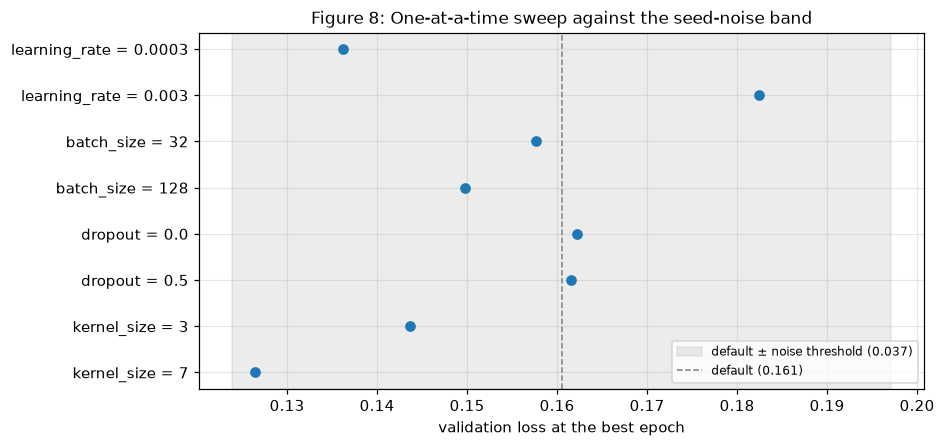

In [43]:
# author: Khalifa Alhashel
exps = sweep.iloc[1:]
ypos = np.arange(len(exps))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.axvspan(default_loss - noise, default_loss + noise, color="grey", alpha=0.15,
           label=f"default ± noise threshold ({noise:.3f})")
ax.axvline(default_loss, color="grey", ls="--", lw=1, label=f"default ({default_loss:.3f})")
ax.scatter(exps["val loss"], ypos, zorder=3, color="C0")
ax.set_yticks(ypos)
ax.set_yticklabels([f"{p} = {v}" for p, v in zip(exps["parameter"], exps["value"])])
ax.invert_yaxis()
ax.set_xlabel("validation loss at the best epoch")
ax.set_title("Figure 8: One-at-a-time sweep against the seed-noise band")
ax.legend(fontsize=8, loc="lower right")
savefig(fig, 8, "hyperparameter_sweep")
plt.show()

**Interpretation.** Figure 8 carries the headline: **every point falls inside
the noise band.** No single change to learning rate, batch size, dropout or
kernel size moves validation loss further than reseeding the default does. The
defaults are not measurably worse than any alternative tested.

The runs are still informative, because the *best epoch* moves in a consistent,
explainable way even when the best result does not:

| Exp. | Parameter varied | Value | Observation |
|---|---|---|---|
| 1 | Learning rate | 3 × 10⁻⁴ | Smaller steps, slower progress: the best epoch moves from 5 to 7. Loss 0.024 lower, within noise. |
| 2 | Learning rate | 3 × 10⁻³ | Steps too large: the best epoch is the *first*, after which validation loss only rises. |
| 3 | Batch size | 32 | Twice as many updates per epoch, so the best epoch arrives sooner (2). Within noise. |
| 4 | Batch size | 128 | Half as many updates per epoch, so it arrives later (8). Within noise. |
| 5 | Dropout | 0.0 | No measurable change in best loss. |
| 6 | Dropout | 0.5 | No measurable change in best loss. |
| 7 | Kernel size | 3 | Receptive field 22 < 32-sample stride, yet no worse. The §5.1 prediction that this would hurt **is not supported.** |
| 8 | Kernel size | 7 | Receptive field 50. Best single result on both loss and accuracy, and the closest to the threshold. Checked in §7.2. |

**Learning rate and batch size control *how fast* the model reaches its best,
not *how good* that best is.** Best epoch falls steadily as the learning rate
rises (7 → 5 → 1) and as the batch shrinks (8 → 5 → 2). Both follow from one
mechanism: learning rate sets the size of each step, and batch size sets how
many steps fit in an epoch. With early stopping picking the best epoch
wherever it falls, the final quality ends up about the same. That is the answer
to give if asked what changing either of them will do to the curves.

**Why kernel 3 did not hurt.** The receptive-field argument assumed a filter must
see a whole stride to recognise walking. But the global average pool combines
evidence from across the whole window regardless of kernel size, and on the
validation subjects the walking classes are already near-perfect. The errors
that remain are the static confusion, which has nothing to do with stride
length. A shorter receptive field had nothing left to damage.

### 7.2 Checking the best-looking result

Kernel size 7 gave the lowest loss and the highest accuracy of the sweep, and
its gap to the default is the closest to the threshold. Before adopting it, it
is retrained with the same four seeds used in §6.3.

This guards against a well-known trap. When you pick the best of eight noisy
results, you partly pick the *luckiest* one, so the winner's single-run score
overstates its true performance. Repeating it shows how much of the win
survives.

In [44]:
# author: Khalifa Alhashel
winner = sweep.iloc[1:].sort_values("val loss").iloc[0]
print(f"best-looking sweep result: {winner['parameter']} = {winner['value']} "
      f"(val loss {winner['val loss']:.4f})\n")

winner_rows = []
for seed in [CONFIG["seed"], 0, 1, 2]:
    _, history = run_experiment({winner["parameter"]: winner["value"], "seed": seed})
    loss, acc = best(history)
    winner_rows.append({"seed": seed, "val_loss": loss, "val_acc": acc})
winner_df = pd.DataFrame(winner_rows)

default_seeds = seeds_df[seeds_df["model"] == "baseline"].set_index("seed")
check = pd.DataFrame({
    "default val loss": default_seeds["val_loss"],
    f"{winner['parameter']}={winner['value']} val loss": winner_df.set_index("seed")["val_loss"],
    "default val acc": default_seeds["val_acc"],
    f"{winner['parameter']}={winner['value']} val acc": winner_df.set_index("seed")["val_acc"],
})
print(check.round(4).to_string())
print("\nmean and std across seeds:")
print(check.agg(["mean", "std"]).round(4).to_string())

best-looking sweep result: kernel_size = 7 (val loss 0.1265)



      default val loss  kernel_size=7 val loss  default val acc  kernel_size=7 val acc
seed                                                                                  
42              0.1605                  0.1265           0.9663                 0.9716
0               0.1429                  0.1541           0.9566                 0.9619
1               0.1939                  0.1452           0.9552                 0.9542
2               0.1359                  0.1367           0.9644                 0.9663

mean and std across seeds:
      default val loss  kernel_size=7 val loss  default val acc  kernel_size=7 val acc
mean            0.1583                  0.1406           0.9606                 0.9635
std             0.0259                  0.0118           0.0055                 0.0073


**Interpretation.** The advantage shrinks when repeated. Across four seeds,
kernel 7 averages a validation loss of **0.141 ± 0.012**, against the default's
**0.158 ± 0.026**. Seed 42's 0.127 turns out to be kernel 7's luckiest run. The
difference in means (0.018) is smaller than the default's own seed-to-seed
spread, each setting wins on two of the four seeds, and mean accuracy differs
by 0.3 points (0.9635 vs 0.9606).

**Decision: keep kernel size 5.** Kernel 7 is not shown to be better, the
default still has the §3.4 receptive-field rationale behind it, and keeping it
leaves the baseline and CNN-LSTM comparison in §5–§6 unchanged.

The single-run sweep had singled kernel 7 out as the clear winner. Without the
repeat, we would have adopted a setting for a reason that was mostly luck.

### 7.3 Overfitting control: removing the regularisers

Section 5.3 found the baseline overfitting after epoch 5 despite dropout, and
promised to measure how much each regulariser contributes by taking it away.
Two runs, both trained for the full 30 epochs with early stopping disabled
(patience set to the epoch limit):

- **dropout 0.3, no early stopping**: the §5 baseline, allowed to keep going;
- **no dropout, no early stopping**: no regularisation at all.

The first run is the §5.2 run with the stopping rule removed, so for its first
13 epochs it must reproduce §5.2 exactly. That is checked below, which
confirms that the comparison isolates the stopping rule.

In [45]:
# author: Khalifa Alhashel
_, no_es_history = run_experiment({"patience": CONFIG["epochs"]})
_, no_reg_history = run_experiment({"patience": CONFIG["epochs"], "dropout": 0.0})

n = len(baseline_history["val_loss"])
assert np.allclose(no_es_history["val_loss"][:n], baseline_history["val_loss"])
print(f"first {n} epochs identical to the section 5.2 run: True\n")

ablation = pd.DataFrame([
    {"setting": "dropout 0.3 + early stopping (5.2)",
     "best epoch": baseline_history["best_epoch"],
     "val loss kept": best(baseline_history)[0], "val acc kept": best(baseline_history)[1],
     "train loss kept": baseline_history["train_loss"][baseline_history["best_epoch"] - 1]},
    {"setting": "dropout 0.3, no early stopping",
     "best epoch": no_es_history["best_epoch"],
     "val loss kept": no_es_history["val_loss"][-1], "val acc kept": no_es_history["val_acc"][-1],
     "train loss kept": no_es_history["train_loss"][-1]},
    {"setting": "no dropout, no early stopping",
     "best epoch": no_reg_history["best_epoch"],
     "val loss kept": no_reg_history["val_loss"][-1], "val acc kept": no_reg_history["val_acc"][-1],
     "train loss kept": no_reg_history["train_loss"][-1]},
])
print(ablation.round(4).to_string(index=False))
print("\n'kept' = the weights you end up with: the best epoch with early stopping, "
      "the last epoch (30) without it.")

first 13 epochs identical to the section 5.2 run: True

                           setting  best epoch  val loss kept  val acc kept  train loss kept
dropout 0.3 + early stopping (5.2)           5         0.1605        0.9663           0.1085
    dropout 0.3, no early stopping           5         0.4281        0.9605           0.0538
     no dropout, no early stopping           2         0.3724        0.9436           0.0366

'kept' = the weights you end up with: the best epoch with early stopping, the last epoch (30) without it.


saved figures\fig09_regulariser_ablation.png


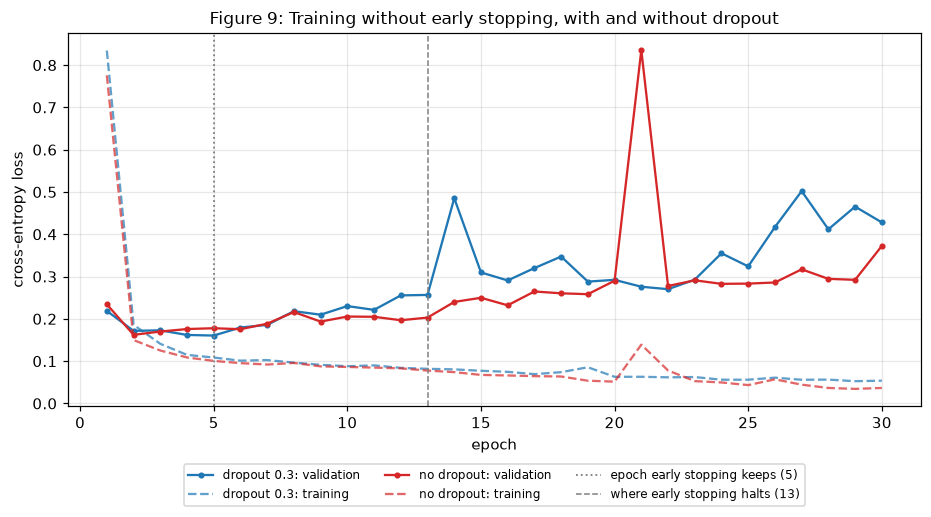

In [46]:
# author: Khalifa Alhashel
fig, ax = plt.subplots(figsize=(10, 4.4))
for history, label, color in ((no_es_history, "dropout 0.3", "C0"),
                              (no_reg_history, "no dropout", "C3")):
    epochs = np.arange(1, len(history["val_loss"]) + 1)
    ax.plot(epochs, history["val_loss"], "o-", ms=3, color=color, label=f"{label}: validation")
    ax.plot(epochs, history["train_loss"], "--", color=color, alpha=0.7, label=f"{label}: training")
ax.axvline(baseline_history["best_epoch"], color="grey", ls=":", lw=1.2,
           label=f"epoch early stopping keeps ({baseline_history['best_epoch']})")
ax.axvline(len(baseline_history["val_loss"]), color="grey", ls="--", lw=1,
           label=f"where early stopping halts ({len(baseline_history['val_loss'])})")
ax.set_xlabel("epoch")
ax.set_ylabel("cross-entropy loss")
ax.set_title("Figure 9: Training without early stopping, with and without dropout")
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.14))
savefig(fig, 9, "regulariser_ablation")
plt.show()

**Interpretation.**

**Early stopping is the regulariser doing the work.** Allowed to run to epoch
30, the baseline ends with a validation loss of **0.428**, about 2.7 times the
0.161 early stopping keeps, while its training loss falls to 0.054. Figure 9
shows the widening gap directly: training loss slides down steadily while
validation loss climbs from epoch 5 onwards. That is the textbook picture of
overfitting, and early stopping cuts it off at its source by keeping the
epoch-5 weights.

Past epoch 13, validation loss is also far more erratic in both runs. The
largest jump, in the no-dropout run at epoch 21, appears in the *training* loss
as well. That marks it as a brief optimisation instability (a few oversized
updates) rather than overfitting, and the run recovers by the next epoch. It is
one more reason not to trust whatever weights a run happens to end on.

Accuracy degrades far less than loss (0.966 kept vs 0.961 at epoch 30), for the
reason given in §5.3. The overfit model's *choices* barely change, but it
becomes overconfident in the ones it gets wrong.

**Dropout has no measurable effect on the best result.** Without it, the best
validation loss is 0.162, against 0.161 with it, well inside the noise. The
§7.1 sweep agrees: dropout 0.0, 0.3 and 0.5 are indistinguishable. Dropout does
slow the model's memorisation of its training set (training loss at epoch 30 is
0.054 with it vs 0.037 without), but that does not turn into better validation
performance here. By epoch 30 both runs are badly overfit, and a single seed
cannot say which is worse.

**Why keep dropout at 0.3 then?** It costs nothing measurable, and the
evidence shows it neither helps nor harms. Removing it would be equally
defensible; the honest statement is that at this data size, early stopping is
what controls overfitting and dropout is a safeguard with no demonstrated
benefit.

This answers the brief's requirement to show *how* overfitting was detected
(the diverging curves in Figures 6 and 9) and *what* addressed it (early
stopping, measured here at 2.7× lower validation loss).

### 7.4 Data augmentation

Section 4.4 deferred augmentation to an experiment. The `augment_batch`
function in §5.2 applies two standard perturbations for wearable-sensor data
(see Um et al., 2017) to each *training* batch, freshly randomised every time:

- **scaling**: each channel of each window is multiplied by a random factor
  drawn around 1 (standard deviation 0.1), mimicking people who move more or
  less vigorously;
- **jitter**: Gaussian noise (standard deviation 0.05, in standardised units)
  is added to every reading, mimicking sensor noise.

Validation data is never augmented. The validation set has to measure
performance on real signals.

**Hypothesis.** These perturbations simulate intensity and noise, not
*posture*. They may slow overfitting by making each epoch's data slightly
different, but they should not fix the sitting/standing confusion, which
§6.3 traced to how two particular people hold themselves.

In [47]:
# author: Khalifa Alhashel
aug_model, aug_history = run_experiment({"augment": True})
aug_loss, aug_acc = best(aug_history)
aug_pred = predict(aug_model, X_val)

print(f"{'':28} {'val loss':>9} {'val acc':>8} {'best epoch':>11} {'recall SITTING':>15} {'recall STANDING':>16}")
for label, loss, acc, b, pred in (
        ("default (no augmentation)", default_loss, default_acc, baseline_history["best_epoch"], pred_base),
        ("jitter + scaling", aug_loss, aug_acc, aug_history["best_epoch"], aug_pred)):
    print(f"{label:28} {loss:9.4f} {acc:8.4f} {b:11d} "
          f"{(pred[y_val == 3] == 3).mean():15.3f} {(pred[y_val == 4] == 4).mean():16.3f}")
print(f"\nchange in val loss: {aug_loss - default_loss:+.4f}   (noise threshold {noise:.4f})")

                              val loss  val acc  best epoch  recall SITTING  recall STANDING
default (no augmentation)       0.1605   0.9663           5           0.897            0.921
jitter + scaling                0.1564   0.9595           4           0.870            0.921

change in val loss: -0.0041   (noise threshold 0.0366)


**Interpretation.** Augmentation changes validation loss by 0.004, a tenth of
the noise threshold. Accuracy falls by 0.7 points, which is also inside its own
noise range (√2 × 0.0055 ≈ 0.008). Standing recall is unchanged at 0.921.
Sitting recall drops from 0.897 to 0.870, about ten windows, a difference a
single run cannot separate from noise. The hypothesis holds on both counts: no
measurable benefit, and the static confusion untouched.

**Decision: augmentation stays off.** It adds a random process to training that
would need defending, for no demonstrated gain. What the static confusion needs
is not more varied versions of the same people's data but data from more
people, which is a limitation of the dataset (section 9.0), not something
training can fix.

### 7.5 Is the CNN-LSTM's advantage just extra parameters?

Section 6.3 found the CNN-LSTM had a lower and steadier validation loss, but it
also has 75% more parameters. §6.1 noted that only a capacity-matched control
could separate "better architecture" from "bigger model".

The control is the baseline, unchanged except that its convolution width is
increased until its parameter count matches the CNN-LSTM's as closely as
possible. The width is chosen by counting, not by trying. It is then trained
with the same four seeds as §6.3.

In [48]:
# author: Khalifa Alhashel
target = count_params(cnn_lstm)
matched_width = min(range(CONFIG["conv_width"], 129),
                    key=lambda w: abs(count_params(build_model("baseline", dict(CONFIG, conv_width=w))) - target))
wide_params = count_params(build_model("baseline", dict(CONFIG, conv_width=matched_width)))
print(f"CNN-LSTM parameters: {target:,}")
print(f"baseline at width {matched_width}: {wide_params:,}  (closest match)\n")

wide_rows = []
for seed in [CONFIG["seed"], 0, 1, 2]:
    _, history = run_experiment({"conv_width": matched_width, "seed": seed})
    loss, acc = best(history)
    wide_rows.append({"model": "wide baseline", "seed": seed, "val_loss": loss, "val_acc": acc})

capacity = pd.concat([seeds_df, pd.DataFrame(wide_rows)])
stats = capacity.groupby("model")[["val_loss", "val_acc"]].agg(["mean", "std"])
stats.columns = [f"{metric} {stat}" for metric, stat in stats.columns]   # flatten headers
stats["parameters"] = pd.Series({"baseline": count_params(baseline),
                                 "wide baseline": wide_params,
                                 "cnn_lstm": target})
order = ["baseline", "wide baseline", "cnn_lstm"]
print(stats.loc[order, ["parameters", "val_loss mean", "val_loss std",
                        "val_acc mean", "val_acc std"]].round(4).to_string())

CNN-LSTM parameters: 77,702
baseline at width 85: 76,846  (closest match)



               parameters  val_loss mean  val_loss std  val_acc mean  val_acc std
model                                                                            
baseline            44422         0.1583        0.0259        0.9606       0.0055
wide baseline       76846         0.1468        0.0174        0.9623       0.0039
cnn_lstm            77702         0.1332        0.0117        0.9625       0.0021


**Interpretation.** The wide baseline lands **between** the two models. Its mean
validation loss is **0.147**, against 0.158 for the original baseline and 0.133
for the CNN-LSTM. Adding parameters alone closes roughly half of the 0.025 gap.

The remaining difference between the wide baseline and the CNN-LSTM (0.014) is
well inside seed noise. So the evidence does **not** let us credit the
CNN-LSTM's lower loss to sequence modelling with any confidence. Part of it is
simply that the model is bigger, and the rest cannot be told apart from chance
with four seeds. Accuracy is the same for all three (0.961–0.963).

This revises the reading of §6.3 downwards, and it is the kind of result that
only a controlled comparison can produce. The CNN-LSTM remains a legitimate
candidate: it is at least as good on every measure and the most consistent
across seeds. But "the LSTM helps because it models order" is not a claim this
project can support.

### 7.6 What a random split would have reported

Section 3.5 showed that consecutive windows share half their samples, and
promised to measure what splitting by window instead of by subject would have
done to the results. Here the baseline is trained exactly as before, except that
the 15 training subjects' windows are shuffled and split 80/20 **at random**.
That is the common default, and it is what `train_test_split` would do.

That model is then scored twice:

- on its own random validation windows, which is what the leaky split would
  report;
- on the six held-out validation subjects it has never seen, which is what
  actually happens with new people.

The test set is not involved. It stays untouched until section 8.0.

The count at the end checks, on the raw data, how many random-validation windows
share 64 samples with a window in the random training part.

In [49]:
# author: Khalifa Alhashel
perm = np.random.default_rng(CONFIG["seed"]).permutation(len(y_train))
cut = int(0.8 * len(perm))
rand_train, rand_val = perm[:cut], perm[cut:]

leaky_model, leaky_history = run_experiment(
    {}, train_data=(X_train[rand_train], y_train[rand_train]),
    val_data=(X_train[rand_val], y_train[rand_val]))
leaky_loss, leaky_acc = best(leaky_history)
unseen_loss, unseen_acc = run_epoch(leaky_model, make_loader(X_val, y_val, 256, shuffle=False),
                                    make_loss(CONFIG["loss"]))

in_train = np.zeros(len(y_train), dtype=bool)
in_train[rand_train] = True


def shares_half(i, k):
    """True if windows i and k overlap by 64 samples, checked on the raw readings."""
    a, b = X_train_raw[i], X_train_raw[k]
    return np.array_equal(a[:, 64:], b[:, :64]) or np.array_equal(b[:, 64:], a[:, :64])


overlapping = sum(
    any(0 <= k < len(y_train) and in_train[k] and shares_half(j, k) for k in (j - 1, j + 1))
    for j in rand_val)

print(f"{'':44} {'val loss':>9} {'val acc':>8}")
print(f"{'random window split, its own validation':44} {leaky_loss:9.4f} {leaky_acc:8.4f}")
print(f"{'same model, 6 unseen subjects':44} {unseen_loss:9.4f} {unseen_acc:8.4f}")
print(f"{'subject split (section 5.2), for reference':44} {default_loss:9.4f} {default_acc:8.4f}")
print(f"\nbest epoch under the random split: {leaky_history['best_epoch']} of "
      f"{len(leaky_history['val_loss'])} run (subject split: {baseline_history['best_epoch']})")
print(f"random-validation windows sharing 64 samples with a training window: "
      f"{overlapping} of {len(rand_val)} ({100 * overlapping / len(rand_val):.0f}%)")

                                              val loss  val acc
random window split, its own validation         0.0698   0.9688
same model, 6 unseen subjects                   0.3610   0.9557
subject split (section 5.2), for reference      0.1605   0.9663

best epoch under the random split: 29 of 30 run (subject split: 5)
random-validation windows sharing 64 samples with a training window: 990 of 1056 (94%)


**Interpretation.** The random split goes wrong in two separate ways, and the
second is the more serious.

**1. It flatters the result.** On its own validation windows the model reports a
loss of **0.070** and an accuracy of **96.9%**. Scored on six people it has never
seen, the same model gets a loss of **0.361**, five times higher, and **95.6%**
accuracy. The accuracy inflation is modest, about 1.3 points, because most
windows are easy either way. The loss shows the problem clearly: the model is
far more confident about windows it has effectively already seen, and that
confidence does not carry over to new people.

The last line of output explains why. **94% of the random-validation windows
share 64 samples with a window the model trained on.** That is checked on the
raw readings, not assumed. The "validation" set is mostly half-copies of
training data. There is also a second, smaller leak: the normalisation
statistics were computed over all 15 subjects, these validation windows
included.

**2. It breaks early stopping, so it produces a worse model.** Under the subject
split, validation loss bottomed out at epoch 5. Under the random split it keeps
improving until **epoch 29 of 30**. As the model memorises its training windows,
it memorises the overlapping validation windows with them, so the overfitting
that §5.3 detected and §7.3 measured never shows up. Early stopping never fires
and keeps almost the last epoch, a model trained far past the point where the
subject split saw overfitting begin.

The unseen-subject loss shows the damage. At 0.361 it is more than double the
0.161 of the model selected under the subject split, and close to the 0.428 of
the never-stopped run in §7.3. This model also trained on 20% fewer windows,
which may cost it a little accuracy, but less data does not explain a doubled
loss.

So a random split does not only report the wrong number. It feeds the wrong
signal into model selection, and the result is a model that is genuinely worse
on new people while appearing better. That is the concrete cost of the leakage
§3.5 identified, and the reason every split in this notebook is by subject.

### 7.7 What the experiments decided

| Question | Evidence | Decision |
|---|---|---|
| Learning rate, batch size, dropout, kernel size | All within seed noise of the default (Fig. 8) | Keep the defaults |
| Kernel 7, the sweep's winner | Not confirmed over four seeds (§7.2) | Keep kernel 5 |
| Early stopping | Removing it gives 2.7× the validation loss (Fig. 9) | Essential. This is the overfitting control |
| Dropout | No measurable effect at 0.0, 0.3 or 0.5 | Keep 0.3 as a harmless safeguard |
| Augmentation (jitter + scaling) | No measurable effect; static confusion unchanged | Off |
| CNN-LSTM vs a same-size CNN | About half the loss advantage is capacity; the rest is within noise | No claim that sequence modelling helps |
| Subject split vs random split | Random split under-reports loss 5× and disables early stopping (§7.6) | Subject split, as used throughout |

`CONFIG` is therefore unchanged. The models carried into section 8.0 are the
§5.2 baseline and the §6.2 CNN-LSTM, exactly as trained, and the test set has
not yet been used for anything.

## 8.0 Test-set evaluation

### 8.1 Protocol

Up to this cell, the test set has been used for nothing:

- not for exploration (§3.0 looked at the training split only);
- not for normalisation (§4.2 fitted its statistics on the 15 training subjects);
- not for choosing epochs (early stopping watched the validation subjects);
- not for any experiment in §7.0.

The deployment decision is made once, on two **frozen** models: the §5.2
baseline and the §6.2 CNN-LSTM, loaded back from the weight files saved when
they were trained. Nothing below changes a model, a threshold or a
hyperparameter in response to what the test set shows. That is what makes these
numbers an honest estimate of how the models would perform on nine people they
have never seen.

After the decision is recorded, §8.3 retrains both architectures with three
further seeds to measure how much confidence the decision deserves. That check
can qualify the decision, but it is not used to make it.

**The deployment rule, fixed before the test results are seen.**

1. The primary metric is **macro-averaged F1** on the test set (justified in
   §8.2).
2. A difference counts only if it exceeds the seed-noise threshold: √2 × the
   baseline's standard deviation of validation accuracy across the four seeds
   in §6.3. The seed spread of macro F1 was not measured separately; with
   near-balanced classes, accuracy and macro F1 move together, so accuracy's
   spread stands in for it.
3. If one model wins by more than that, it is deployed. Otherwise it is a tie
   and the **baseline** is deployed. It has 43% fewer parameters, trains and
   runs faster, and is simpler to explain and maintain. Equal performance does
   not justify extra complexity.

Writing the rule down first matters. With two models and a dozen metrics, some
metric will usually favour each model, and choosing the metric after seeing the
results would let the conclusion pick its evidence.

In [50]:
# author: Rashed Ramadham
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, accuracy_score, average_precision_score,
    classification_report, confusion_matrix, f1_score, log_loss, precision_score,
    recall_score, roc_auc_score)
from sklearn.preprocessing import label_binarize

SHORT_NAMES = ["WALK", "UPSTAIRS", "DOWNSTAIRS", "SIT", "STAND", "LAY"]   # for plot axes

# label -> (architecture for build_model, saved weights, training history)
FROZEN = {
    "Baseline CNN": ("baseline", "baseline_cnn.pt", baseline_history),
    "CNN-LSTM": ("cnn_lstm", "cnn_lstm.pt", cnn_lstm_history),
}

models = {}
for label, (arch, filename, _) in FROZEN.items():
    model = build_model(arch, CONFIG).to(device)
    model.load_state_dict(torch.load(MODEL_DIR / filename, map_location=device))
    model.eval()
    models[label] = model

# The files on disk must reproduce the models trained in 5.2 and 6.2 exactly.
assert (predict(models["Baseline CNN"], X_val) == predict(baseline, X_val)).all()
assert (predict(models["CNN-LSTM"], X_val) == predict(cnn_lstm, X_val)).all()
print("loaded both models from disk; validation predictions match the trained models exactly")

print(f"\ntest set: {len(y_test):,} windows from subjects {np.unique(subj_test).tolist()}")
print(f"subjects shared with training or validation: "
      f"{set(subj_test.tolist()) & set(subj_trainval.tolist()) or 'none'}")

loaded both models from disk; validation predictions match the trained models exactly

test set: 2,947 windows from subjects [2, 4, 9, 10, 12, 13, 18, 20, 24]
subjects shared with training or validation: none


In [51]:
# author: Rashed Ramadham
# The deployment threshold, computed from validation results only (section 6.3).
acc_std = seeds_df.loc[seeds_df["model"] == "baseline", "val_acc"].std()
F1_THRESHOLD = np.sqrt(2) * acc_std
print(f"baseline validation-accuracy std across seeds: {acc_std:.4f}")
print(f"a macro-F1 difference must exceed {F1_THRESHOLD:.4f} to count")

baseline validation-accuracy std across seeds: 0.0055
a macro-F1 difference must exceed 0.0078 to count


### 8.2 Choosing the metrics

#### Which errors are costly?

The metrics have to reflect what a mistake *costs*, which depends on the use.
Take the natural one for this model: an activity monitor that reports how long
its user spends sitting and how active they are. Long uninterrupted sitting is
a recognised health risk, so sedentary time is usually the figure such a
monitor exists to report.

- **Walking ↔ walking upstairs/downstairs.** Time moves between two *active*
  categories. The user's activity total is barely affected. **Low cost.**
- **Moving ↔ static.** Activity is counted as rest or the reverse. **Moderate
  cost**, but §3.3 found these classes far apart, so these errors should be
  rare.
- **Sitting ↔ standing.** This corrupts the sedentary-time figure directly:
  standing is how a user *breaks* sedentary time, so every standing window read
  as sitting inflates it, and every sitting window read as standing hides it.
  **High cost**, and §3.3 predicted it would be the most frequent error.

#### The metrics and why each is here

| Metric | What it measures | Why it is reported here |
|---|---|---|
| Accuracy | Share of all windows classified correctly | A fair headline because the classes are near-balanced (§3.1): always guessing the largest class scores only 18%. But it averages over classes, so it can hide a failure concentrated in one. |
| Recall, per class | Of the windows that truly are class *c*, the share labelled *c* | Exposes the costly error directly. Low sitting recall means sitting time the monitor fails to count. |
| Precision, per class | Of the windows labelled *c*, the share that truly are *c* | The other side of the same error. Low sitting precision means time wrongly counted as sitting. |
| F1, per class | Harmonic mean of precision and recall | One number per class that is low if *either* is low. |
| Macro average | Unweighted mean over the six classes | Every activity matters equally to the user, whatever its window count. With near-balanced classes, macro and weighted averages nearly coincide. **Macro F1 is the primary metric**: one number that no single class can hide behind. |
| ROC-AUC, one-vs-rest, macro | How well the probabilities rank each class's windows above the rest | Threshold-free: judges the whole probability ranking, not just the top choice. |
| PR-AUC (average precision), one-vs-rest, macro | Area under each class's precision–recall curve | One-vs-rest turns each class into a 1-against-5 problem, where ROC-AUC tends to look flattering. PR-AUC is more sensitive to errors on the positive class. |
| Test log loss | Mean cross-entropy on the test set | What both models were trained to minimise. The CNN-LSTM's validation advantage (§6.3) was in this metric, so the test has to check it. |

### 8.3 Results

`evaluate` computes every metric in §8.2 for one model on one split. Its
`average` argument decides how per-class metrics are combined: `"macro"` (the
default) and `"weighted"` return one number each, while `None` returns **one
number per class**. Reporting per-class recall instead of a single average is
therefore a one-argument change, used in §8.4.

In [52]:
# author: Rashed Ramadham
def predict_proba(model, X):
    """Softmax class probabilities for every window in X, shape (n, 6)."""
    model.eval()
    with torch.no_grad():
        logits = model(torch.from_numpy(X).to(device))
    return torch.softmax(logits.double(), dim=1).cpu().numpy()


def evaluate(model, X, y, average="macro"):
    """Every reported metric for one model on one split.

    average : "macro" or "weighted" -> one number per metric
              None                  -> one number PER CLASS for precision,
                                       recall, F1, ROC-AUC and PR-AUC
    Accuracy and log loss are always single numbers.
    """
    probs = predict_proba(model, X)
    pred = probs.argmax(axis=1)
    y_onehot = label_binarize(y, classes=range(N_CLASSES))
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, average=average, zero_division=0),
        "recall": recall_score(y, pred, average=average, zero_division=0),
        "f1": f1_score(y, pred, average=average, zero_division=0),
        "roc_auc": roc_auc_score(y, probs, multi_class="ovr", average=average),
        "pr_auc": average_precision_score(y_onehot, probs, average=average),
        "log_loss": log_loss(y, probs, labels=list(range(N_CLASSES))),
    }

In [53]:
# author: Rashed Ramadham
results = {}
for label, model in models.items():
    history = FROZEN[label][2]
    m = evaluate(model, X_test_std, y_test)
    recall_per_class = evaluate(model, X_test_std, y_test, average=None)["recall"]
    results[label] = {
        "accuracy": m["accuracy"],
        "macro precision": m["precision"],
        "macro recall": m["recall"],
        "macro F1": m["f1"],
        "macro ROC-AUC": m["roc_auc"],
        "macro PR-AUC": m["pr_auc"],
        "test log loss": m["log_loss"],
        "worst-class recall": recall_per_class.min(),
        "worst class": ACTIVITIES[recall_per_class.argmin()],
        "validation accuracy": history["val_acc"][history["best_epoch"] - 1],
        "parameters": sum(p.numel() for p in model.parameters()),
        "train time (s)": history["seconds"],
    }


def fmt(value):
    if isinstance(value, str):
        return value
    if isinstance(value, (int, np.integer)):
        return f"{value:,}"
    return f"{value:.4f}"


results_df = pd.DataFrame({label: {k: fmt(v) for k, v in r.items()}
                           for label, r in results.items()})
results_df.loc["train time (s)"] = [f"{r['train time (s)']:.1f}" for r in results.values()]
print("Test-set results (9 unseen subjects, 2,947 windows)\n")
print(results_df.to_string())

Test-set results (9 unseen subjects, 2,947 windows)

                    Baseline CNN CNN-LSTM
accuracy                  0.9152   0.8829
macro precision           0.9158   0.8861
macro recall              0.9180   0.8836
macro F1                  0.9165   0.8822
macro ROC-AUC             0.9918   0.9882
macro PR-AUC              0.9653   0.9540
test log loss             0.3183   0.3477
worst-class recall        0.8102   0.7760
worst class             STANDING  SITTING
validation accuracy       0.9663   0.9629
parameters                44,422   77,702
train time (s)               9.1      9.9


In [54]:
# author: Rashed Ramadham
# Apply the rule from 8.1 mechanically.
f1_gap = results["CNN-LSTM"]["macro F1"] - results["Baseline CNN"]["macro F1"]
print(f"macro F1: baseline {results['Baseline CNN']['macro F1']:.4f}, "
      f"CNN-LSTM {results['CNN-LSTM']['macro F1']:.4f}")
print(f"difference (CNN-LSTM - baseline): {f1_gap:+.4f}   threshold: {F1_THRESHOLD:.4f}")

if abs(f1_gap) > F1_THRESHOLD:
    DEPLOYED = "CNN-LSTM" if f1_gap > 0 else "Baseline CNN"
    print(f"\nthe difference exceeds seed noise -> deploy the {DEPLOYED}")
else:
    DEPLOYED = "Baseline CNN"
    print(f"\nwithin seed noise: a tie -> deploy the simpler model, the {DEPLOYED}")

macro F1: baseline 0.9165, CNN-LSTM 0.8822
difference (CNN-LSTM - baseline): -0.0343   threshold: 0.0078

the difference exceeds seed noise -> deploy the Baseline CNN


#### Is the margin robust? (checked after the decision)

The rule compared one trained model of each kind. Section 6.3 showed that a
different seed alone can move a result by more than the threshold, so the
decision above could partly reflect luck. Both architectures are now retrained
with the three other seeds used in §6.3, with exactly the same protocol, and
scored on the test set. This takes one to two minutes.

In [55]:
# author: Rashed Ramadham
robust_rows = [{"model": label, "seed": CONFIG["seed"],
                "test macro F1": results[label]["macro F1"],
                "test accuracy": results[label]["accuracy"]}
               for label in models]

for seed in (0, 1, 2):
    for label, (arch, _, _) in FROZEN.items():
        set_seed(seed)
        model = build_model(arch, CONFIG)
        train_model(model, CONFIG, (X_train, y_train), (X_val, y_val), verbose=False)
        m = evaluate(model, X_test_std, y_test)
        robust_rows.append({"model": label, "seed": seed,
                            "test macro F1": m["f1"], "test accuracy": m["accuracy"]})

robust = pd.DataFrame(robust_rows)
print(robust.pivot(index="seed", columns="model",
                   values=["test macro F1", "test accuracy"]).round(4).to_string())
print("\nmean and standard deviation across the four seeds:\n")
robust_summary = robust.groupby("model")[["test macro F1", "test accuracy"]].agg(["mean", "std"])
print(robust_summary.round(4).to_string())

mean_gap = (robust_summary.loc["CNN-LSTM", ("test macro F1", "mean")]
            - robust_summary.loc["Baseline CNN", ("test macro F1", "mean")])
print(f"\nmean macro-F1 difference (CNN-LSTM - baseline): {mean_gap:+.4f}   "
      f"threshold: {F1_THRESHOLD:.4f}")
print("the rule applied to the seed means:",
      "a real difference" if abs(mean_gap) > F1_THRESHOLD
      else "a tie -> the baseline, the same decision")

      test macro F1          test accuracy         
model  Baseline CNN CNN-LSTM  Baseline CNN CNN-LSTM
seed                                               
0            0.9132   0.9093        0.9125   0.9104
1            0.9146   0.9127        0.9138   0.9135
2            0.9050   0.9201        0.9046   0.9196
42           0.9165   0.8822        0.9152   0.8829

mean and standard deviation across the four seeds:

             test macro F1         test accuracy        
                      mean     std          mean     std
model                                                   
Baseline CNN        0.9123  0.0051        0.9115  0.0047
CNN-LSTM            0.9060  0.0165        0.9066  0.0162

mean macro-F1 difference (CNN-LSTM - baseline): -0.0063   threshold: 0.0078
the rule applied to the seed means: a tie -> the baseline, the same decision


**Interpretation.**

**The rule deploys the baseline, and the decision survives the robustness
check, but the margin does not.** On the frozen seed-42 models, the baseline
leads on every metric in the table: macro F1 0.917 against 0.882, a gap of
0.034, more than four times the 0.008 threshold. Read alone, that looks like a
decisive win.

The robustness check shows why a single run cannot be read that way. Retrained
with three more seeds, the CNN-LSTM scores 0.909, 0.913 and 0.920. **Seed 42 was
its worst result by a wide margin**, and on seed 2 it beats every baseline run.
Averaged over the four seeds, the gap shrinks to 0.006, inside the threshold.
Applied to the averages, the rule calls it a tie, and the tie-break deploys the
baseline anyway.

So the *decision* is robust: both readings of the rule lead to the baseline.
The claim that the baseline is substantially more accurate is not.

**What does separate the models is stability.** Across seeds, the baseline's
test macro F1 has a standard deviation of 0.005, while the CNN-LSTM's is more
than three times larger (0.017). This reverses §6.3, where the CNN-LSTM was the
*more* consistent model on the validation subjects. On nine new people, its
result depends far more on the luck of training. For a model that would be
retrained as more data arrives, that unpredictability is a practical cost in
its own right.

**Test performance is well below validation.** Averaged over seeds, accuracy
falls about five points between validation (§6.3) and test: 0.961 → 0.912 for
the baseline, and 0.963 → 0.907 for the CNN-LSTM. The subject-wise split was
designed to make both estimates honest, and it did. The difference lies in
*which people* each set contains, and §8.7 shows where the drop comes from.

**The ranking metrics are high even where the decisions are not.** Macro
ROC-AUC is 0.99 for both models while accuracy is 0.88–0.92. The two measure
different things:

- ROC-AUC asks whether a class's probability ranks that class's windows above
  *other windows*.
- Accuracy asks whether the correct class beats the other classes *for the same
  window*.

A sitting window can get a sitting score high enough to rank above most
standing windows, while still getting an even higher standing score. The
probabilities carry useful ranking information even where the top choice is
wrong. PR-AUC, the stricter of the two ranking measures, sits in between
(0.95–0.97).

### 8.4 Per-class results

The averages above can hide a failure concentrated in one class. The per-class
report shows precision, recall and F1 for every activity. *Support* is the
number of test windows of that class.

In [56]:
# author: Rashed Ramadham
for label, model in models.items():
    print(f"=== {label} ===")
    print(classification_report(y_test, predict(model, X_test_std),
                                target_names=ACTIVITIES, digits=3))

=== Baseline CNN ===
                    precision    recall  f1-score   support

           WALKING      0.963     0.996     0.979       496
  WALKING_UPSTAIRS      0.931     0.921     0.926       471
WALKING_DOWNSTAIRS      0.944     1.000     0.971       420
           SITTING      0.805     0.831     0.818       491
          STANDING      0.852     0.810     0.830       532
            LAYING      1.000     0.950     0.974       537

          accuracy                          0.915      2947
         macro avg      0.916     0.918     0.916      2947
      weighted avg      0.915     0.915     0.915      2947

=== CNN-LSTM ===


                    precision    recall  f1-score   support

           WALKING      0.846     0.988     0.912       496
  WALKING_UPSTAIRS      0.980     0.826     0.896       471
WALKING_DOWNSTAIRS      0.844     0.940     0.890       420
           SITTING      0.812     0.776     0.794       491
          STANDING      0.834     0.821     0.828       532
            LAYING      1.000     0.950     0.974       537

          accuracy                          0.883      2947
         macro avg      0.886     0.884     0.882      2947
      weighted avg      0.887     0.883     0.883      2947



In [57]:
# author: Rashed Ramadham
# The same per-class recall through evaluate(): average=None is the only change.
recall_table = pd.DataFrame(
    {label: evaluate(model, X_test_std, y_test, average=None)["recall"]
     for label, model in models.items()},
    index=ACTIVITIES)
print("per-class recall on the test set\n")
print(recall_table.round(3).to_string())

per-class recall on the test set

                    Baseline CNN  CNN-LSTM
WALKING                    0.996     0.988
WALKING_UPSTAIRS           0.921     0.826
WALKING_DOWNSTAIRS         1.000     0.940
SITTING                    0.831     0.776
STANDING                   0.810     0.821
LAYING                     0.950     0.950


**Interpretation.** The classes fall into three groups, each behaving
differently.

**The static pair is the weak point, as predicted.** Sitting and standing have
the lowest F1 of all six classes for both models: 0.818 and 0.830 for the
baseline, 0.794 and 0.828 for the CNN-LSTM. The worst-recall class is always one
of them (standing, 0.810, for the baseline; sitting, 0.776, for the CNN-LSTM).
The deployed model misreads roughly one sitting or standing window in five or
six, and this is exactly the costly error of §8.2.

Precision and recall are low *together* for both classes (0.81–0.85), so the
errors run in both directions. The monitor would both miss sedentary time and
invent it.

**Laying: perfect precision, imperfect recall.** Precision is 1.000 for both
models, meaning nothing else is ever called laying. Recall is only 0.950: 27
laying windows are called something else. Figure 10 below shows that "something
else" is a *walking* class. §3.3 made that look almost impossible, since laying
is by far the most distinct posture in orientation. §9.0 investigates these
windows.

**The walking activities are where the two models differ.** For the baseline
they are near-perfect, apart from walking upstairs (recall 0.921). The CNN-LSTM
is clearly worse on all three moving classes at this seed: walking upstairs
recall falls to 0.826, and walking precision to 0.846. Given the robustness
check, that says more about this particular trained CNN-LSTM than about the
architecture.

The second table is the same per-class recall obtained from
`evaluate(..., average=None)`. Changing that one argument turns the macro
summary into the per-class view.

### 8.5 Confusion matrices

Each row is a true class and each column a predicted class, so the diagonal
holds correct predictions and every off-diagonal cell is one specific kind of
mistake. Counts rather than percentages are shown, because the classes are
similar in size and a count is easier to reason about ("*n* standing windows
read as sitting").

`plot_confusions` takes the split as its arguments, so the same figure for the
validation set is `plot_confusions(X_val, y_val, "validation", ...)`, and
`normalize="true"` turns each row into proportions (recall on the diagonal).

saved figures\fig10_confusion_test.png


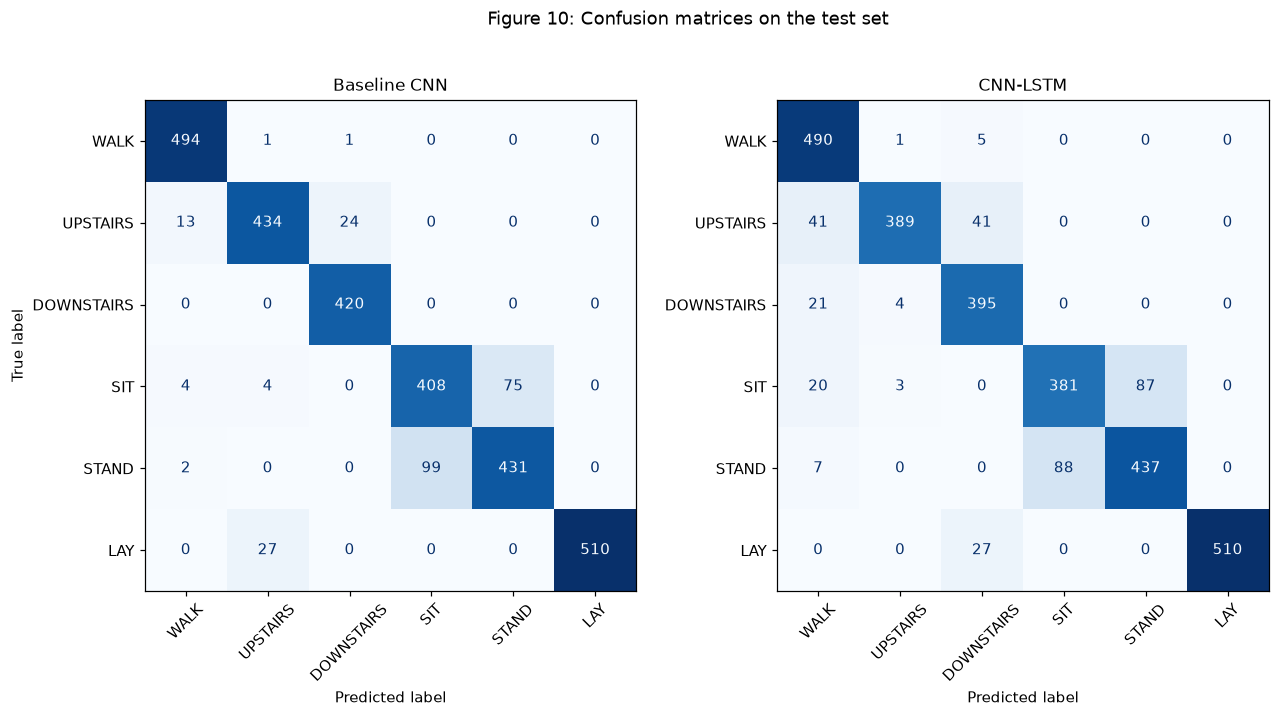

In [58]:
# author: Rashed Ramadham
def plot_confusions(X, y, split_name, number, slug, normalize=None):
    """Side-by-side confusion matrices of every model in `models`, on one split."""
    fig, axes = plt.subplots(1, len(models), figsize=(6.8 * len(models), 5.8))
    for ax, (label, model) in zip(axes, models.items()):
        ConfusionMatrixDisplay.from_predictions(
            y, predict(model, X), labels=list(range(N_CLASSES)),
            display_labels=SHORT_NAMES, normalize=normalize,
            cmap="Blues", colorbar=False, ax=ax)
        ax.set_title(label)
        ax.grid(False)
        ax.tick_params(axis="x", labelrotation=45)
        if ax is not axes[0]:
            ax.set_ylabel("")                 # one shared y label, no overlap
    fig.suptitle(f"Figure {number}: Confusion matrices on the {split_name} set", y=1.02)
    savefig(fig, number, slug)
    plt.show()


plot_confusions(X_test_std, y_test, "test", 10, "confusion_test")

#### Checking the §3.3 prediction

Section 3.3 found sitting and standing only 0.36 g apart in orientation, three
times closer than any other pair of static postures, and predicted that **the
largest off-diagonal mass would lie between them**. The cell below checks it.

In [59]:
# author: Rashed Ramadham
for label, model in models.items():
    cm = confusion_matrix(y_test, predict(model, X_test_std), labels=list(range(N_CLASSES)))
    errors = cm.copy()
    np.fill_diagonal(errors, 0)
    i, j = np.unravel_index(errors.argmax(), errors.shape)
    sit, stand = ACTIVITIES.index("SITTING"), ACTIVITIES.index("STANDING")
    pair = errors[sit, stand] + errors[stand, sit]
    print(f"{label}: {errors.sum()} errors in total")
    print(f"  largest single cell: {ACTIVITIES[i]} -> {ACTIVITIES[j]} ({errors[i, j]})")
    print(f"  sitting <-> standing: {pair} ({pair / errors.sum():.0%} of all errors)")
    print(f"  prediction confirmed: {{i, j}} == {{SITTING, STANDING}} -> "
          f"{set((i, j)) == {sit, stand}}\n")

Baseline CNN: 250 errors in total
  largest single cell: STANDING -> SITTING (99)
  sitting <-> standing: 174 (70% of all errors)
  prediction confirmed: {i, j} == {SITTING, STANDING} -> True

CNN-LSTM: 345 errors in total
  largest single cell: STANDING -> SITTING (88)
  sitting <-> standing: 175 (51% of all errors)
  prediction confirmed: {i, j} == {SITTING, STANDING} -> True



**Interpretation.** **The §3.3 prediction holds on unseen people, for both
models.** The largest single cell is standing read as sitting: 99 windows for
the baseline, 88 for the CNN-LSTM. Sitting ↔ standing errors total 174 and 175,
nearly identical, as they were on validation (§6.3). Architecture makes no
difference to this confusion, and for the deployed baseline it accounts for
**70% of all errors**.

The rest of Figure 10 splits into three kinds of mistake.

1. **Within the walking activities** (upstairs read as walking or downstairs).
   In §8.2's terms this is a low-cost error: the activity is still counted, just
   in the wrong sub-category. It is where the CNN-LSTM makes most of its extra
   errors: 82 upstairs windows misread, against the baseline's 37.
2. **Static read as moving, never the reverse.** The baseline reads 37 static
   windows as moving (8 sitting, 2 standing, 27 laying); the CNN-LSTM reads 57.
   Neither model reads a *single* moving window as static. §3.3 expected a few
   such errors, because some static windows contain as much motion as the
   quietest walking.
3. **Laying read as walking: the anomaly.** All 27 of these are the same kind of
   error for both models: laying windows predicted as walking upstairs by one
   model and walking downstairs by the other. The two models agree these windows
   are *moving*, and disagree only on the direction. §9.0 looks at them
   directly.

### 8.6 Precision–recall curves

For each class, the model's probability for that class is used as a score and
the decision threshold is swept from high to low. At a high threshold only the
most confident windows are labelled with the class (high precision, low
recall); lowering it finds more of the class at the cost of more false alarms.
The area under each curve is the per-class PR-AUC (average precision, "AP" in
the legend). A perfect class hugs the top-right corner.

saved figures\fig11_precision_recall_test.png


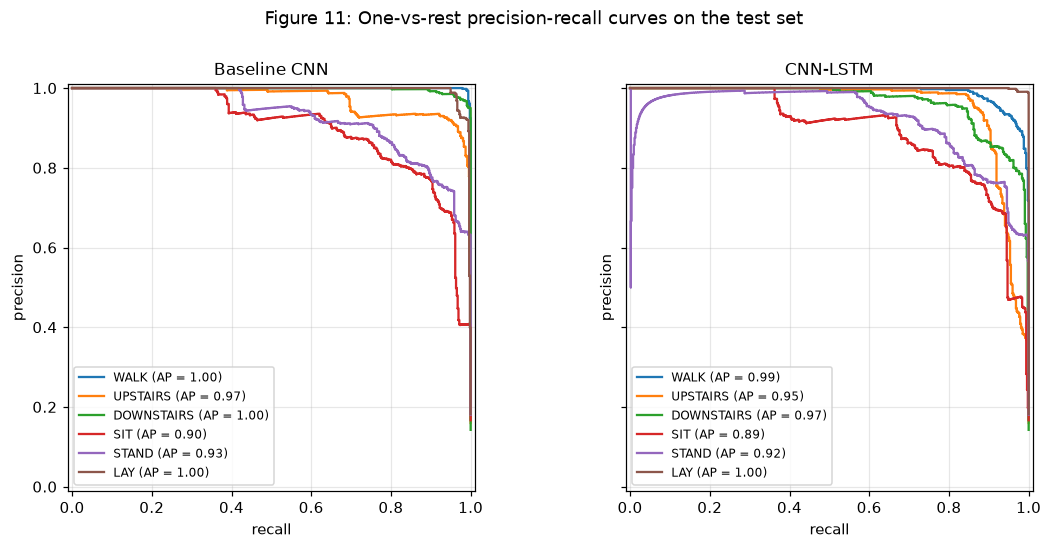

In [60]:
# author: Rashed Ramadham
fig, axes = plt.subplots(1, len(models), figsize=(12, 4.8), sharey=True)
for ax, (label, model) in zip(axes, models.items()):
    probs = predict_proba(model, X_test_std)
    for k in range(N_CLASSES):
        PrecisionRecallDisplay.from_predictions(
            y_test == k, probs[:, k], ax=ax, name=SHORT_NAMES[k],
            curve_kwargs={"color": colors[k]})
    ax.set_title(label)
    ax.set_xlabel("recall")
    ax.set_ylabel("precision")
    ax.legend(fontsize=8, loc="lower left")
fig.suptitle("Figure 11: One-vs-rest precision-recall curves on the test set", y=1.02)
savefig(fig, 11, "precision_recall_test")
plt.show()

**Interpretation.** For both models, the lowest curves (the ones that fall away
from the top-right corner earliest) belong to sitting (AP 0.90 / 0.89) and
standing (0.93 / 0.92). No threshold on the sitting score reaches high recall
without a large loss of precision: to find more of the true sitting windows,
the model has to admit many standing ones too. The confusion lives in the scores
themselves, not in where the decision threshold sits. Moving the threshold
would trade one error for the other rather than remove it.

**Laying scores AP 1.00 despite 27 misclassified windows**, which looks like a
contradiction. The answer is in where those windows fall in the ranking. All
510 correctly classified laying windows score above *every* non-laying window,
so the curve stays at precision 1.0 up to recall 0.95. The 27 misses come last.
They cost the curve only its final 5% of recall (the drop at the right edge),
so AP barely moves: 0.996 for the baseline.

The baseline gives these 27 windows a laying probability of essentially zero
(at most 0.005). It is not uncertain about them; it is *confident* they are not
laying. All 27 come from one test subject, and §9.0 examines what they actually
look like.

### 8.7 Why the test score is lower than validation

Both models lose about five points of accuracy between validation and test.
Section 6.3 found that, on validation, errors came from specific people, so the
natural first check is test accuracy per subject for both models. The deployed
model's validation accuracy per subject is shown alongside for comparison.

In [61]:
# author: Rashed Ramadham
def accuracy_by_subject(pred, y, subjects):
    """Accuracy for each subject separately, indexed by subject ID."""
    return pd.Series({int(s): (pred[subjects == s] == y[subjects == s]).mean()
                      for s in np.unique(subjects)})


deployed_model = models[DEPLOYED]
test_pred = predict(deployed_model, X_test_std)

by_subject = pd.DataFrame({label: accuracy_by_subject(predict(m, X_test_std), y_test, subj_test)
                           for label, m in models.items()})
by_subject["windows"] = pd.Series(subj_test).value_counts()
print("test accuracy per subject\n")
print(by_subject.sort_values(DEPLOYED).round(3).to_string())

val_by_subject = accuracy_by_subject(predict(deployed_model, X_val), y_val, subj_val)
print(f"\n{DEPLOYED}, validation accuracy per subject\n")
print(val_by_subject.sort_values().round(3).to_string())

errors_per_subject = pd.Series(subj_test[test_pred != y_test]).value_counts()
hardest = errors_per_subject.index[:2].tolist()
keep = ~np.isin(subj_test, hardest)
print(f"\n{DEPLOYED}: {len(errors_per_subject.index)} subjects share "
      f"{errors_per_subject.sum()} test errors")
print(f"subjects {hardest} alone contribute {errors_per_subject.iloc[:2].sum()} "
      f"({errors_per_subject.iloc[:2].sum() / errors_per_subject.sum():.0%})")
print(f"test accuracy without them: {(test_pred[keep] == y_test[keep]).mean():.4f}   "
      f"(all test subjects: {(test_pred == y_test).mean():.4f}, "
      f"validation: {(predict(deployed_model, X_val) == y_val).mean():.4f})")

test accuracy per subject

    Baseline CNN  CNN-LSTM  windows
10         0.650     0.633      294
9          0.767     0.674      288
4          0.883     0.896      317
2          0.897     0.887      302
20         0.983     0.963      354
13         0.985     0.924      327
12         0.997     0.953      320
18         1.000     0.942      364
24         1.000     0.995      381

Baseline CNN, validation accuracy per subject

28    0.901
29    0.910
19    0.997
3     1.000
22    1.000
15    1.000

Baseline CNN: 7 subjects share 250 test errors
subjects [10, 9] alone contribute 170 (68%)
test accuracy without them: 0.9662   (all test subjects: 0.9152, validation: 0.9663)


**Interpretation.** **The drop comes from two people.**

For the deployed baseline, five of the nine test subjects score 98–100%, just as
four of the six validation subjects score 99.7–100%. Test subjects 2 and 4
(88–90%) are at the level of validation's two hardest people, 28 and 29
(90–91%). What the validation set had no equivalent of is subjects **9 (77%)**
and **10 (65%)**.

Those two contribute **170 of the baseline's 250 test errors (68%)**. Without
them, test accuracy is **0.966**, the same as validation accuracy (0.966) to
three decimal places.

So the validation estimate was not wrong about the kind of people it contained.
The test set simply includes two people unlike anyone in the validation set,
and a model's accuracy on a new person depends heavily on who that person is.
With only 30 volunteers in the whole dataset, six validation subjects cannot be
expected to cover that range.

This is the most important caveat on every number in §8: **the test estimate is
an average over nine people whose individual accuracies range from 65% to
100%.** A different nine volunteers could easily have produced a noticeably
different figure. The per-class and seed analyses above cannot reduce that
uncertainty; only more subjects could. §9.0 looks inside subjects 9 and 10's
errors.

### 8.8 Deployment recommendation

**Deploy the baseline CNN.**

The pre-registered rule selects it on the frozen models (macro F1 0.917 vs
0.882). It would select it again from the four-seed averages, where the two
models tie and the rule prefers the simpler one. So the decision does not depend
on the seed-42 result being representative.

Beyond the rule, the evidence points the same way:

| Consideration | Baseline CNN | CNN-LSTM |
|---|---|---|
| Test macro F1, seed 42 (frozen models) | 0.917 | 0.882 |
| Test macro F1, mean of four seeds | 0.912 | 0.906 |
| Standard deviation across seeds | 0.005 | 0.017 |
| Test log loss, seed 42 | 0.318 | 0.348 |
| Sitting ↔ standing errors, seed 42 | 174 | 175 |
| Parameters | 44,422 | 77,702 |

The CNN-LSTM's one advantage on validation was its lower loss. That did not
carry over to the test set at seed 42, and §7.5 had already shown that about
half of it came from extra capacity rather than sequence modelling. What the
CNN-LSTM would add is 75% more parameters and a less predictable result on new
people.

**What the recommendation does not solve.** Neither model fully meets the
purpose set out in §8.2. The sitting ↔ standing confusion, the costly error, is
the same for both. It affects roughly one static window in five or six, and it
is concentrated in particular people. A deployed monitor would report sedentary
time accurately for most users and wrongly for some, without being able to tell
which users those are. This is the central limitation carried into §9.0 and
§10.0.

## 9.0 Interpretability and error analysis

Everything below explains the **deployed baseline** on the **test set**. No
model is changed or retrained in this section.

Two interpretability techniques, chosen because the input is nine sensor
channels over time:

- **Channel-group occlusion (§9.1)** answers *which sensors* the model relies on
  for each class.
- **Grad-CAM over time (§9.2)** answers *when* in the 2.56-second window the
  evidence for a prediction comes from.

Techniques built for images, such as pixel saliency maps, would answer neither
question directly. These two map onto the two axes of the data: sensor and
time.

The error analysis (§9.3–§9.6) then takes the failures found in §8, one kind at
a time, and asks what the misclassified windows actually look like. All
physical quantities (orientation, dynamic energy) are measured on the **raw**,
unstandardised signals, exactly as in §3.3.

In [62]:
# author: Rashed Ramadham
def mean_gravity(X_raw):
    """Average gravity vector of each window (device orientation), in g."""
    return (X_raw[:, 6:9] - X_raw[:, 0:3]).mean(axis=2)


gravity_test = mean_gravity(X_test_raw)
gravity_train = mean_gravity(X_train_raw)
energy_test = magnitude(X_test_raw, 0).std(axis=1)       # dynamic energy, as in section 3.3
print(f"explaining the deployed model: {DEPLOYED}")
print(f"test windows: {len(y_test):,}, misclassified: {(test_pred != y_test).sum()}")

explaining the deployed model: Baseline CNN
test windows: 2,947, misclassified: 250


### 9.1 Which sensors does the model use? Channel-group occlusion

The nine channels form three physical groups: body acceleration (motion with
gravity removed), gyroscope (rotation) and total acceleration (motion *plus*
gravity, the only group that carries orientation). Each group is hidden in turn
and per-class test recall is measured again. A large drop means the model relies
on that group for that class.

"Hiding" means replacing the group's readings with their **training average**.
After the §4.2 standardisation, the training average of every channel is exactly
0, so the replacement is a single assignment.

One caveat on method: the model was never trained on inputs like these. The
numbers therefore show how much this model *relies* on each group, not how well
a model trained without it would perform.

In [63]:
# author: Rashed Ramadham
CHANNEL_GROUPS = {"body_acc": [0, 1, 2], "body_gyro": [3, 4, 5], "total_acc": [6, 7, 8]}


def recall_with_hidden(model, channels):
    """Per-class test recall when `channels` are replaced by their training average."""
    X_hidden = X_test_std.copy()
    X_hidden[:, channels, :] = 0.0        # after standardisation, 0 IS the training average
    return evaluate(model, X_hidden, y_test, average=None)["recall"]


occlusion = pd.DataFrame(index=ACTIVITIES)
occlusion["nothing hidden"] = evaluate(deployed_model, X_test_std, y_test, average=None)["recall"]
for group, channels in CHANNEL_GROUPS.items():
    occlusion[f"{group} hidden"] = recall_with_hidden(deployed_model, channels)
print("per-class test recall\n")
print(occlusion.round(3).to_string())

per-class test recall

                    nothing hidden  body_acc hidden  body_gyro hidden  total_acc hidden
WALKING                      0.996            0.593             0.907             0.966
WALKING_UPSTAIRS             0.921            0.210             0.820             0.904
WALKING_DOWNSTAIRS           1.000            0.007             1.000             0.993
SITTING                      0.831            0.839             0.817             0.974
STANDING                     0.810            0.799             0.810             0.000
LAYING                       0.950            0.950             0.950             0.002


saved figures\fig12_channel_occlusion.png


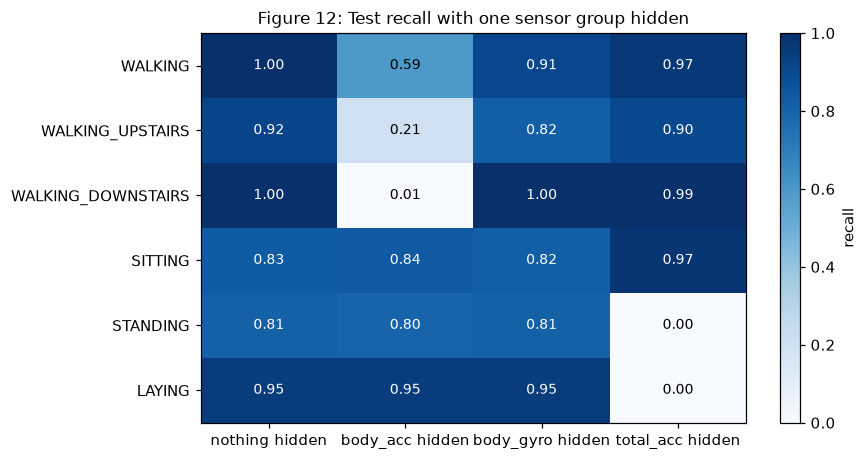

In [64]:
# author: Rashed Ramadham
values = occlusion.to_numpy()
fig, ax = plt.subplots(figsize=(8, 4.6))
im = ax.imshow(values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for (r, c), v in np.ndenumerate(values):
    ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=9,
            color="white" if v > 0.6 else "black")
ax.set_xticks(range(values.shape[1]))
ax.set_xticklabels(occlusion.columns)
ax.set_yticks(range(N_CLASSES))
ax.set_yticklabels(ACTIVITIES)
ax.grid(False)
fig.colorbar(im, ax=ax, label="recall")
ax.set_title("Figure 12: Test recall with one sensor group hidden")
savefig(fig, 12, "channel_occlusion")
plt.show()

In [65]:
# author: Rashed Ramadham
# With orientation hidden, what do the static windows become?
X_hidden = X_test_std.copy()
X_hidden[:, CHANNEL_GROUPS["total_acc"], :] = 0.0
hidden_pred = predict(deployed_model, X_hidden)
for activity in ("SITTING", "STANDING", "LAYING"):
    k = ACTIVITIES.index(activity)
    became = pd.Series([SHORT_NAMES[p] for p in hidden_pred[y_test == k]]).value_counts()
    print(f"{activity:9} ({(y_test == k).sum()} windows) predicted as: {became.to_dict()}")

SITTING   (491 windows) predicted as: {'SIT': 478, 'WALK': 6, 'LAY': 5, 'UPSTAIRS': 2}
STANDING  (532 windows) predicted as: {'SIT': 519, 'WALK': 8, 'UPSTAIRS': 5}
LAYING    (537 windows) predicted as: {'SIT': 499, 'WALK': 27, 'UPSTAIRS': 10, 'LAY': 1}


**Interpretation.** Each sensor group has a clear job, and the pattern matches
the EDA almost exactly.

- **Body acceleration carries the moving classes.** Hide it and recall
  collapses for all three walking activities: walking 0.593, upstairs 0.210,
  downstairs 0.007. The static classes are unaffected, because they have almost
  no body acceleration to lose.
- **The gyroscope is a supporting signal.** Hiding it costs walking and walking
  upstairs 9–10 points each, and leaves every other class within about two
  points. The model uses rotation, but does not depend on it.
- **Gravity (`total_acc`) carries the postures, completely.** Hide it and
  standing recall falls from 0.810 to **0.000**, laying from 0.950 to
  **0.002**. Almost every static window becomes "sitting": 478 of 491 sitting
  windows, 519 of 532 standing and 499 of 537 laying. Sitting recall even
  *rises* to 0.974. The model has not got better at sitting; sitting is simply
  what it falls back on when orientation is missing. The moving classes barely
  notice.

This confirms the §3.3 argument from the model's side. §3.3 kept `total_acc`,
despite its algebraic redundancy, because orientation was the only thing that
could separate the static postures. The network has learned exactly that, and
nothing else, about those three classes.

### 9.2 When in the window does it look? Grad-CAM over time

**Grad-CAM** (gradient-weighted class activation mapping) was designed for image
CNNs, and it transfers directly to a 1-D CNN. It uses the output of the last
convolution block, `block3`: 64 feature maps, each 16 time steps long, where each
step summarises 8 input samples (0.16 s).

1. Run the window forward and keep `block3`'s output (a forward hook, as in the
   §5.1 layer table).
2. Backpropagate the score of the class being explained. The gradient says how
   much each feature map, at each time step, pushed that score up or down.
3. Average each map's gradient over time: **one importance weight per filter**.
4. Take the weighted sum of the 64 maps and keep the positive part (ReLU): **one
   value per time step**, the evidence *for* the class at that moment.
5. Scale to a maximum of 1.

In the figure, the shading behind each signal is the Grad-CAM value. The darker
the band, the more that 0.16 s stretch supported the prediction.

In [66]:
# author: Rashed Ramadham
def grad_cam(model, x, target):
    """Grad-CAM over time for one window.

    x      : one standardised window as a tensor, shape (1, 9, 128)
    target : index of the class to explain
    Returns 16 values in [0, 1], one per block-3 time step (8 input samples each).
    """
    model.eval()
    saved = {}

    def keep_output(module, inputs, output):
        output.retain_grad()               # ask autograd to keep this tensor's gradient
        saved["maps"] = output             # block3 output, shape (1, 64, 16)

    handle = model.block3.register_forward_hook(keep_output)
    logits = model(x)                      # forward pass, with gradients enabled
    handle.remove()

    model.zero_grad()
    logits[0, target].backward()           # step 2: gradient of the class score

    maps = saved["maps"][0]                                  # (64, 16)
    weights = saved["maps"].grad[0].mean(dim=1)              # step 3: (64,) one per filter
    cam = torch.relu((weights[:, None] * maps).sum(dim=0))   # step 4: (16,) one per step
    cam = cam / (cam.max() + 1e-8)                           # step 5
    return cam.detach().cpu().numpy()

saved figures\fig13_grad_cam.png


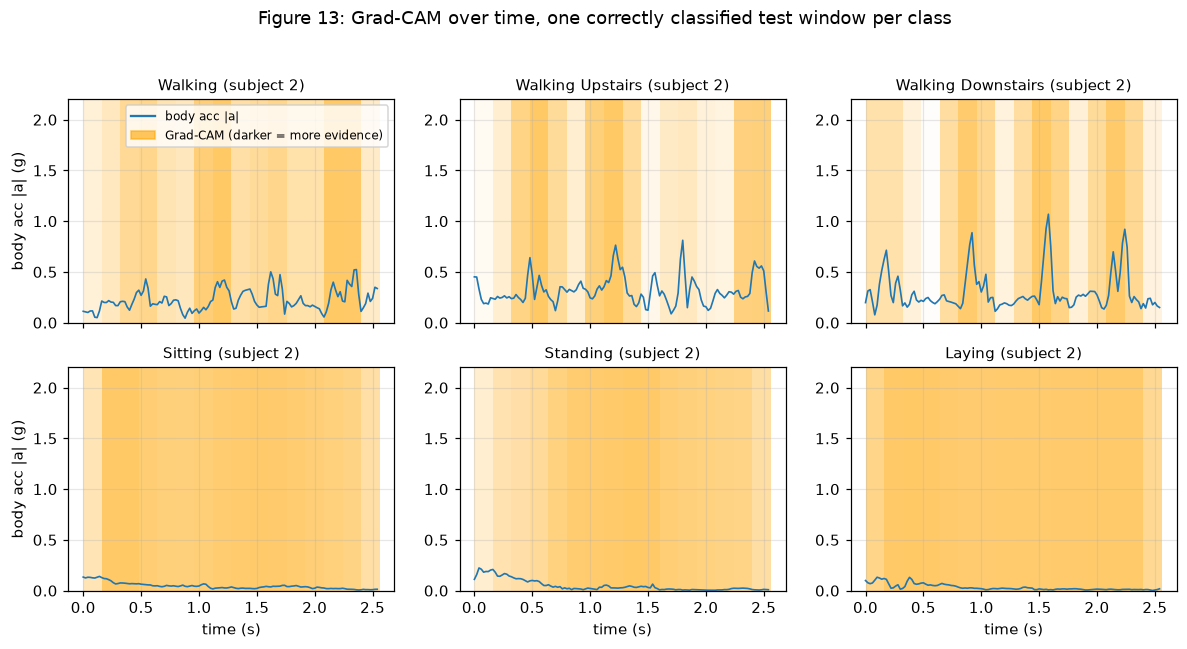

In [67]:
# author: Rashed Ramadham
body_mag_test = magnitude(X_test_raw, 0)
t = np.arange(WINDOW_LEN) / SAMPLING_HZ
step_seconds = (WINDOW_LEN // 16) / SAMPLING_HZ           # 8 samples = 0.16 s

fig, axes = plt.subplots(2, 3, figsize=(13, 5.8), sharex=True)
for k, ax in enumerate(axes.ravel()):
    i = int(np.flatnonzero((y_test == k) & (test_pred == k))[0])   # first correct window
    cam = grad_cam(deployed_model, torch.from_numpy(X_test_std[i:i + 1]).to(device), k)
    for step, weight in enumerate(cam):
        ax.axvspan(step * step_seconds, (step + 1) * step_seconds,
                   color="orange", alpha=0.6 * weight, lw=0)
    ax.plot(t, body_mag_test[i], lw=1.1, color="C0")
    ax.set_title(f"{ACTIVITIES[k].replace('_', ' ').title()} (subject {subj_test[i]})", fontsize=10)
    ax.set_ylim(0, 2.2)
    if k >= 3:
        ax.set_xlabel("time (s)")
    if k % 3 == 0:
        ax.set_ylabel("body acc |a| (g)")
axes[0, 0].legend(handles=[plt.Line2D([], [], color="C0", label="body acc |a|"),
                           plt.Rectangle((0, 0), 1, 1, color="orange", alpha=0.6,
                                         label="Grad-CAM (darker = more evidence)")],
                  fontsize=8, loc="upper right")
fig.suptitle("Figure 13: Grad-CAM over time, one correctly classified test window per class", y=1.02)
savefig(fig, 13, "grad_cam")
plt.show()

Six examples could be unrepresentative, so the cell below repeats Grad-CAM for
**every** correctly classified test window (about 2,700 backward passes, a few
seconds) and summarises two things per class:

- **Correlation with motion:** does the evidence line up with the moments of
  highest body acceleration? Body acceleration is averaged into the same 16 steps
  as Grad-CAM before comparing.
- **Variation along the window** (coefficient of variation, std ÷ mean): is the
  evidence concentrated in a few moments (high) or spread evenly (low)?

In [68]:
# author: Rashed Ramadham
motion_by_step = body_mag_test.reshape(len(y_test), 16, -1).mean(axis=2)   # (n, 16)

cam_rows = []
for k, activity in enumerate(ACTIVITIES):
    correlations, variations = [], []
    for i in np.flatnonzero((y_test == k) & (test_pred == k)):
        cam = grad_cam(deployed_model, torch.from_numpy(X_test_std[i:i + 1]).to(device), k)
        with np.errstate(invalid="ignore", divide="ignore"):
            correlations.append(np.corrcoef(cam, motion_by_step[i])[0, 1])
        variations.append(cam.std() / (cam.mean() + 1e-8))
    cam_rows.append({"activity": activity, "windows": len(variations),
                     "correlation with motion": np.nanmean(correlations),
                     "variation along window": np.mean(variations)})

print(pd.DataFrame(cam_rows).set_index("activity").round(3).to_string())

                    windows  correlation with motion  variation along window
activity                                                                    
WALKING                 494                    0.495                   0.295
WALKING_UPSTAIRS        434                    0.476                   0.497
WALKING_DOWNSTAIRS      420                    0.517                   0.463
SITTING                 408                   -0.113                   0.101
STANDING                431                   -0.102                   0.121
LAYING                  510                   -0.052                   0.091


**Interpretation.** The two groups of classes are explained in completely
different ways, and the difference holds across all 2,697 correctly classified
windows, not just the six examples.

- **Moving classes: the evidence follows the footsteps.** For walking, upstairs
  and downstairs, Grad-CAM correlates with body acceleration at about +0.5. The
  model's evidence is strongest at the moments of impact and weaker between
  steps. In Figure 13 the darkest bands sit over the acceleration peaks, most
  clearly for walking downstairs, where each sharp footfall is marked. The
  evidence also varies strongly along the window (coefficient of variation
  0.30–0.50). This is the behaviour §5.0 designed for: filters that detect the
  local shape of a step wherever it occurs in the window.
- **Static classes: the evidence is spread evenly.** For sitting, standing and
  laying, Grad-CAM is nearly flat (variation 0.09–0.12, several times lower than
  for the moving classes). It is also slightly *anti*-correlated with motion
  (−0.05 to −0.11): the few moments with any movement are, if anything, the least
  informative. The model is reading something present equally at every moment of
  the window, which is orientation.

Together with §9.1, this gives a consistent account of the model:

- **Which sensor:** body acceleration for the moving classes, gravity for the
  postures.
- **When in the window:** at each impact for the moving classes, uniformly for
  the postures.

It also explains, after the fact, why the CNN-LSTM could not fix the static
confusion (§6.3). An LSTM adds the ability to use the *order* of events in the
window, but the evidence for posture has no order: it is the same at every
step.

### 9.3 Error analysis: what goes wrong for subjects 9 and 10?

Section 8.7 found that two of the nine test subjects produce 68% of the
deployed model's errors. Before explaining each failure, the cell below lists
what those errors are.

In [69]:
# author: Rashed Ramadham
for subject in (9, 10):
    wrong = (subj_test == subject) & (test_pred != y_test)
    kinds = pd.Series([f"{SHORT_NAMES[t]} -> {SHORT_NAMES[p]}"
                       for t, p in zip(y_test[wrong], test_pred[wrong])]).value_counts()
    print(f"subject {subject}: {wrong.sum()} errors of {(subj_test == subject).sum()} windows")
    print(kinds.to_string(), "\n")

subject 9: 67 errors of 288 windows
STAND -> SIT        42
UPSTAIRS -> WALK    11
SIT -> STAND         4
SIT -> UPSTAIRS      4
SIT -> WALK          4
STAND -> WALK        1
WALK -> UPSTAIRS     1 

subject 10: 103 errors of 294 windows
SIT -> STAND              30
LAY -> UPSTAIRS           27
UPSTAIRS -> DOWNSTAIRS    24
STAND -> SIT              21
WALK -> DOWNSTAIRS         1 



**Three different failure modes**, which the next sections take one at a time:

| Failure | Subject 9 | Subject 10 | Explained in |
|---|---|---|---|
| Sitting ↔ standing | 46 | 51 | §9.4 |
| Laying read as walking upstairs | – | 27 | §9.5 |
| Static read as moving | 9 | – | §9.6 |
| Within the walking activities | 12 | 25 | below |

The walking errors are the low-cost kind (§8.2), and each subject has one
consistent pattern: subject 9's upstairs read as walking (11 windows), and
subject 10's upstairs read as *downstairs* (24). Both look like individual
gait: a person whose stair-climbing looks, to this model, like someone else's
level walking or descent. The same person makes the same error repeatedly, which
points at how they move rather than at random noise.

### 9.4 Sitting ↔ standing: a property of the person

Section 9.1 showed the model separates sitting from standing by orientation
alone. Orientation differs between the two only because the waist tilts
slightly when a person sits. If a particular person's sitting and standing tilt
the phone almost the same way, no orientation-based classifier can separate
them for that person.

That is testable. For each validation and test subject, we measure the **gap**:
the distance (in g) between their average sitting orientation and their average
standing orientation. We then compare it with the deployed model's accuracy on
that person's sitting and standing windows. Training subjects are excluded from
the accuracy comparison, because the model has seen their data. Their gaps are
shown for reference.

In [70]:
# author: Rashed Ramadham
SIT, STAND = ACTIVITIES.index("SITTING"), ACTIVITIES.index("STANDING")


def sit_stand_gap(X_raw, y, subjects):
    """Per subject: distance (g) between their average sitting and standing orientation."""
    g = mean_gravity(X_raw)
    return pd.Series({
        int(s): np.linalg.norm(g[(subjects == s) & (y == SIT)].mean(axis=0)
                               - g[(subjects == s) & (y == STAND)].mean(axis=0))
        for s in np.unique(subjects)})


def sit_stand_accuracy(pred, y, subjects):
    """Per subject: accuracy on their sitting and standing windows only."""
    static = np.isin(y, [SIT, STAND])
    return accuracy_by_subject(pred[static], y[static], subjects[static])


people = pd.concat([
    pd.DataFrame({"split": "validation",
                  "sit-stand gap (g)": sit_stand_gap(X_val_raw, y_val, subj_val),
                  "sit/stand accuracy": sit_stand_accuracy(
                      predict(deployed_model, X_val), y_val, subj_val)}),
    pd.DataFrame({"split": "test",
                  "sit-stand gap (g)": sit_stand_gap(X_test_raw, y_test, subj_test),
                  "sit/stand accuracy": sit_stand_accuracy(test_pred, y_test, subj_test)}),
]).sort_values("sit-stand gap (g)")
print(people.round(3).to_string())

gap_accuracy_r = people["sit-stand gap (g)"].corr(people["sit/stand accuracy"])
train_gap = sit_stand_gap(X_train_raw, y_train, subj_train)
print(f"\ncorrelation between gap and accuracy over these {len(people)} people: {gap_accuracy_r:.2f}")
print(f"training subjects' gaps: {train_gap.min():.3f} to {train_gap.max():.3f} "
      f"(median {train_gap.median():.3f})")
print(f"training subjects 16 and 5 (hardest to fit in section 5.3): "
      f"{train_gap[16]:.3f} and {train_gap[5]:.3f}")

         split  sit-stand gap (g)  sit/stand accuracy
9         test              0.087               0.421
10        test              0.201               0.480
28  validation              0.220               0.748
2         test              0.274               0.690
4         test              0.299               0.651
12        test              0.327               1.000
29  validation              0.334               0.752
13        test              0.364               0.953
24        test              0.366               1.000
15  validation              0.384               1.000
20        test              0.387               0.964
18        test              0.393               1.000
3   validation              0.444               1.000
22  validation              0.522               1.000
19  validation              0.728               0.993

correlation between gap and accuracy over these 15 people: 0.75
training subjects' gaps: 0.169 to 0.576 (median 0.371)
training subject

saved figures\fig14_sit_stand_gap.png


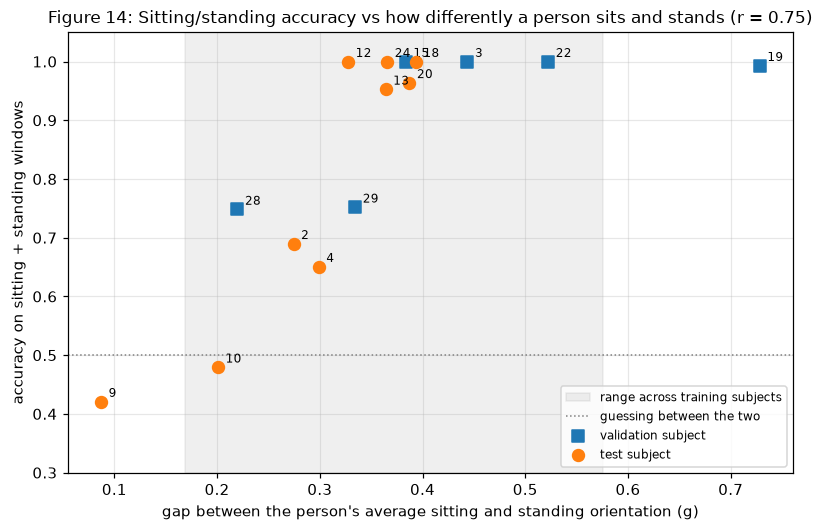

In [71]:
# author: Rashed Ramadham
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.axvspan(train_gap.min(), train_gap.max(), color="grey", alpha=0.12,
           label="range across training subjects")
ax.axhline(0.5, color="grey", ls=":", lw=1, label="guessing between the two")
for split, marker in (("validation", "s"), ("test", "o")):
    rows = people[people["split"] == split]
    ax.scatter(rows["sit-stand gap (g)"], rows["sit/stand accuracy"],
               marker=marker, s=60, label=f"{split} subject", zorder=3)
    for subject, row in rows.iterrows():
        ax.annotate(str(subject), (row["sit-stand gap (g)"], row["sit/stand accuracy"]),
                    xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.set_xlabel("gap between the person's average sitting and standing orientation (g)")
ax.set_ylabel("accuracy on sitting + standing windows")
ax.set_ylim(0.3, 1.05)
ax.set_title(f"Figure 14: Sitting/standing accuracy vs how differently a person sits "
             f"and stands (r = {gap_accuracy_r:.2f})")
ax.legend(fontsize=8, loc="lower right")
savefig(fig, 14, "sit_stand_gap")
plt.show()

**Interpretation.** **Whether the model can tell a person's sitting from their
standing depends largely on that person.** Across the 15 people the model never
trained on, the sit–stand gap and sit/stand accuracy correlate at **r = 0.75**.

Everyone whose gap is at least 0.33 g scores 95% or better, with one exception
discussed below. Everyone below 0.30 g scores 75% or worse:

- **Subject 9** has a gap of just **0.087 g**. Their sitting and standing tilt
  the phone almost identically, and the model gets **42%** of those windows
  right, no better than guessing between two options.
- **Subject 10** (0.201 g) scores 48%.
- Test subjects 2 and 4, and validation subject 28, all have gaps of 0.22–0.30 g
  and score 65–75%.

This also explains the §5.3 puzzle from the other side. The two training
subjects the model found hardest to fit, 16 and 5, have two of the smallest
training gaps (0.25 and 0.21 g).

**The exception is validation subject 29.** Their gap is a moderate 0.33 g, yet
they score only 75%. The gap measures how *far apart* a person's two postures
are, not whether they fall on the correct sides of the model's boundary. One
likely reason, not tested here: subject 29's sitting orientation has an
unusually large z component (0.28 against a training average of about 0.13), so
their postures may be separated in a direction the model did not learn to use.
The correlation is strong, but it is not a complete explanation.

**The consequence is important.** The sitting ↔ standing confusion, 70% of all
errors and the costly one, is largely a limit of the **sensor position**, not of
the model. A phone at the waist sees only the pelvis's tilt, and some people
barely tilt their pelvis when they sit. A different architecture, more training
epochs or more regularisation would not recover information the signal does not
contain. That matches every earlier result: §6.3 found both architectures fail on
the same windows, and §7 found no hyperparameter that moved the static
confusion.

### 9.5 Subject 10's laying windows: an unseen posture, confidently misread

Section 8 found 27 laying windows, all from subject 10, predicted as walking
upstairs, with the model giving them a laying probability of essentially zero.
§3.3 had made this look nearly impossible: laying is the most distinct posture
in orientation. Here is what those windows contain.

In [72]:
# author: Rashed Ramadham
LAY = ACTIVITIES.index("LAYING")
rows10 = np.flatnonzero((subj_test == 10) & (y_test == LAY))
missed10 = rows10[test_pred[rows10] != LAY]
print(f"subject 10: {len(rows10)} laying windows, {len(missed10)} misclassified\n")

# The rows are in recording order, so consecutive row numbers are consecutive windows.
print("runs of consecutive laying windows for subject 10:")
for run in np.split(rows10, np.flatnonzero(np.diff(rows10) != 1) + 1):
    print(f"  rows {run[0]}-{run[-1]}: {len(run):2d} windows, "
          f"{np.sum(test_pred[run] != LAY):2d} misclassified, "
          f"mean orientation (x, y, z) {np.round(gravity_test[run].mean(axis=0), 2)}")


def describe(rows, label):
    print(f"  {label:36} {len(rows):4d} windows   dynamic energy {energy_test[rows].mean():.4f}   "
          f"orientation {np.round(gravity_test[rows].mean(axis=0), 3)}")


print()
describe(missed10, "subject 10, laying, misclassified")
describe(rows10[test_pred[rows10] == LAY], "subject 10, laying, correct")
describe(np.flatnonzero((y_test == LAY) & (subj_test != 10)), "other test subjects, laying")

probs10 = predict_proba(deployed_model, X_test_std[missed10]).mean(axis=0)
print("\nmean predicted probabilities for the misclassified windows:")
print("  " + ", ".join(f"{SHORT_NAMES[k]} {probs10[k]:.3f}" for k in range(N_CLASSES)))

subject 10: 58 laying windows, 27 misclassified

runs of consecutive laying windows for subject 10:
  rows 954-984: 31 windows,  0 misclassified, mean orientation (x, y, z) [-0.02  0.61 -0.35]
  rows 1105-1131: 27 windows, 27 misclassified, mean orientation (x, y, z) [ 0.05 -0.96  0.33]

  subject 10, laying, misclassified      27 windows   dynamic energy 0.0087   orientation [ 0.055 -0.961  0.33 ]
  subject 10, laying, correct            31 windows   dynamic energy 0.0165   orientation [-0.019  0.61  -0.355]
  other test subjects, laying           479 windows   dynamic energy 0.0109   orientation [0.069 0.7   0.553]

mean predicted probabilities for the misclassified windows:
  WALK 0.000, UPSTAIRS 0.977, DOWNSTAIRS 0.022, SIT 0.000, STAND 0.000, LAY 0.001


In [73]:
# author: Rashed Ramadham
# Has the model ever seen this orientation during training?
nearest = np.linalg.norm(gravity_train[:, None, :] - gravity_test[missed10][None, :, :],
                         axis=2)                                # (training windows, 27)
print(f"distance from each misclassified window to the NEAREST training window: "
      f"{nearest.min(axis=0).min():.3f} to {nearest.min(axis=0).max():.3f} g")
print(f"training windows (any class) within 0.5 g of any of them: "
      f"{int((nearest.min(axis=1) < 0.5).sum())}")
lay_train_y = gravity_train[y_train == LAY, 1]
print(f"training laying windows with gravity y below -0.5 g: "
      f"{int((lay_train_y < -0.5).sum())} of {len(lay_train_y)}")
print("\nmean gravity y per class in training:")
for k, activity in enumerate(ACTIVITIES):
    print(f"  {activity:20} {gravity_train[y_train == k, 1].mean():+.3f}")

distance from each misclassified window to the NEAREST training window: 0.642 to 0.779 g
training windows (any class) within 0.5 g of any of them: 0
training laying windows with gravity y below -0.5 g: 1 of 969

mean gravity y per class in training:
  WALKING              -0.173
  WALKING_UPSTAIRS     -0.253
  WALKING_DOWNSTAIRS   -0.141
  SITTING              +0.126
  STANDING             -0.154
  LAYING               +0.637


saved figures\fig15_subject10_laying.png


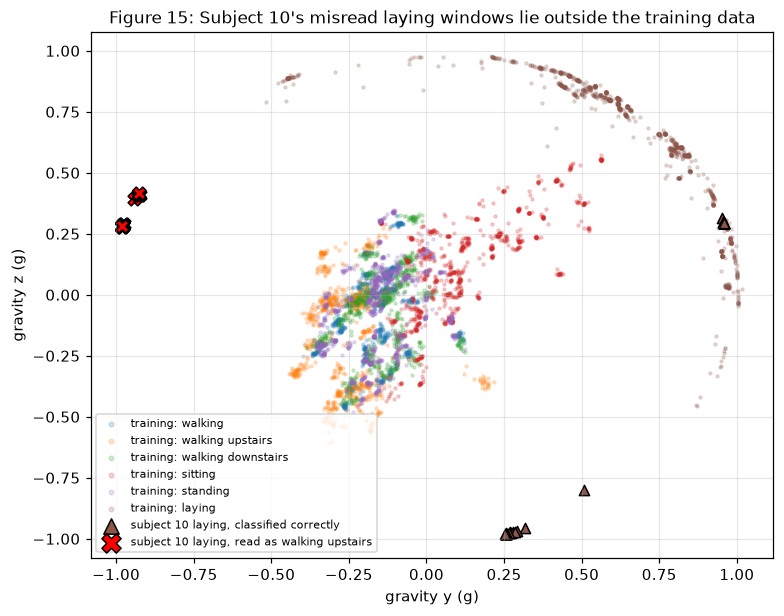

In [74]:
# author: Rashed Ramadham
fig, ax = plt.subplots(figsize=(8, 6.2))
for k in range(N_CLASSES):
    m = y_train == k
    ax.scatter(gravity_train[m, 1], gravity_train[m, 2], s=4, alpha=0.2, color=colors[k],
               label=f"training: {ACTIVITIES[k].replace('_', ' ').lower()}")
correct10 = rows10[test_pred[rows10] == LAY]
ax.scatter(gravity_test[correct10, 1], gravity_test[correct10, 2], s=45, marker="^",
           color=colors[LAY], edgecolor="black", label="subject 10 laying, classified correctly")
ax.scatter(gravity_test[missed10, 1], gravity_test[missed10, 2], s=70, marker="X",
           color="red", edgecolor="black", label="subject 10 laying, read as walking upstairs")
ax.set_xlabel("gravity y (g)")
ax.set_ylabel("gravity z (g)")
ax.set_title("Figure 15: Subject 10's misread laying windows lie outside the training data")
ax.legend(fontsize=7, markerscale=1.5, loc="lower left")
savefig(fig, 15, "subject10_laying")
plt.show()

**Interpretation.** These windows are not movement of any kind. Their dynamic
energy (0.0087) is lower than that of typical laying (0.0109): subject 10 was
lying perfectly still. Their orientation is also horizontal, as laying should
be. Gravity x is 0.05, the same near-zero value as every other laying window.

What differs is **which way the body faces**. Subject 10 was recorded laying
twice:

- **First recording (31 windows):** gravity y is positive (average +0.61), the
  usual direction for laying. Every window is classified correctly.
- **Second recording (27 windows):** gravity points along **−y (−0.96)**. The
  phone is rotated about half a turn about the body's long axis, most plausibly
  because the subject lay facing the other way, on the other side or face down
  instead of face up. Every one of these windows is misclassified.

**The model has never seen that orientation.** Only 1 of the 969 training
laying windows has gravity y below −0.5. No training window of *any* class lies
within 0.5 g of the misread windows; the nearest is 0.64 g away. In Figure 15,
the red crosses sit alone in an empty region of the plot.

Faced with an input unlike anything it trained on, the network does not become
uncertain. It gives **walking upstairs a probability of 97.7%**. One plausible
reason: of all the training classes, walking upstairs has the most negative
average gravity y (−0.25), and these windows lie far beyond it in that
direction. A network learns decision boundaries only where it has data, and far
outside that region its output is extrapolation. That explanation fits the
numbers, but is not proven here.

**This is the most important deployment risk the analysis found.** A softmax
probability measures how strongly an input matches one class *compared with the
others*. It does not measure whether the input resembles the training data at
all. A monitor built on this model would report, with high confidence, that a
person lying in bed was climbing stairs.

Unlike the sitting ↔ standing confusion, this failure can be fixed in
principle. An input whose orientation is far from every training window (here,
more than 0.5 g) can be detected and flagged instead of classified. §10.0 lists
it as future work.

### 9.6 Static windows read as moving: postural adjustments?

Section 3.3 found that about 4% of static windows contain as much motion as the
quietest walking. It predicted that a few would be misread as moving, most
likely during a small postural adjustment. Subject 10's 27 laying windows are
excluded here, because §9.5 established a different cause for them. For each
remaining static window read as moving, the table gives its dynamic energy and
where that energy ranks among the static windows the model classified
correctly.

In [75]:
# author: Rashed Ramadham
STATIC = [SIT, STAND, LAY]
is_static = np.isin(y_test, STATIC)
correct_static = is_static & (test_pred == y_test)
static_energy = energy_test[correct_static]
p95 = np.percentile(static_energy, 95)

others = np.flatnonzero(is_static & ~np.isin(test_pred, STATIC) & ~np.isin(np.arange(len(y_test)), missed10))
moved = pd.DataFrame({
    "row": others,
    "subject": subj_test[others],
    "true": [ACTIVITIES[k] for k in y_test[others]],
    "predicted": [ACTIVITIES[k] for k in test_pred[others]],
    "dynamic energy": energy_test[others].round(4),
    "percentile": [round(100 * (static_energy < e).mean(), 1) for e in energy_test[others]],
})
print(moved.to_string(index=False))
print(f"\n'percentile' = share of correctly read static windows with LESS dynamic energy")
print(f"95th percentile of correctly read static windows: {p95:.4f}")
print(f"median moving window:                            {np.median(energy_test[~is_static]):.4f}")
print(f"misread windows above the 95th percentile: {(energy_test[others] > p95).sum()} of {len(others)}")

 row  subject     true        predicted  dynamic energy  percentile
 302        4 STANDING          WALKING          0.1122        99.0
 763        9 STANDING          WALKING          0.0579        97.9
 790        9  SITTING WALKING_UPSTAIRS          0.1147        99.0
 791        9  SITTING WALKING_UPSTAIRS          0.1431        99.4
 792        9  SITTING WALKING_UPSTAIRS          0.1489        99.4
 793        9  SITTING WALKING_UPSTAIRS          0.1431        99.4
 794        9  SITTING          WALKING          0.0204        87.7
 795        9  SITTING          WALKING          0.0165        83.9
 796        9  SITTING          WALKING          0.0202        87.6
 797        9  SITTING          WALKING          0.0170        84.4

'percentile' = share of correctly read static windows with LESS dynamic energy
95th percentile of correctly read static windows: 0.0340
median moving window:                            0.1390
misread windows above the 95th percentile: 6 of 10


**Interpretation.** The §3.3 hypothesis is **partly supported**.

Six of the ten misread windows contain genuine motion: their dynamic energy is
above the 95th percentile of correctly read static windows. Four of them
(0.11–0.15) move as much as a typical walking window (median 0.139). These are
not random errors; the model read real movement as movement.

Most of them come from **one episode**. Rows 790–797 are eight consecutive
windows from subject 9, all labelled sitting, covering about 11.5 seconds of
recording (with 50% overlap).

- The first four contain walking-level motion and are read as walking upstairs.
- The last four are quieter (84th–88th percentile, raised but within the normal
  static range) and are read as walking.

The likeliest story is that subject 9 moved during a segment labelled sitting,
perhaps shifting, reaching or half-standing, and the model followed the motion
while the label stayed fixed. A label describes a recorded segment as a whole,
not every second of it, so errors like these partly reflect how coarse the
labels are rather than a failure of the model.

The four quieter windows are the honest exception. Their motion is only
moderately raised, no more than in many static windows that were classified
correctly, so the data does not fully explain them.

### 9.7 Failure modes of the deployed model

Every one of the deployed model's 250 test errors falls into one of four failure
modes:

| Failure mode | Test errors | Cause | Evidence | Could a better model fix it? |
|---|---|---|---|---|
| Sitting ↔ standing | 174 (70%) | Some people sit and stand with nearly the same pelvic tilt, and orientation is the model's only cue (§9.1) | r = 0.75 between a person's sit–stand gap and their accuracy (§9.4); identical for both architectures (§8.5) | **Largely no.** For those people, the signal does not contain the information. Needs per-user calibration or a different sensor position |
| Unseen laying orientation | 27 | Subject 10 lying in a direction absent from training | 0.64 g from any training window; 97.7% confident (§9.5) | **It can at least be detected:** flag orientations far from the training data |
| Motion within static windows | 10 | Movement during a segment labelled static | 6 of 10 above the 95th percentile of motion; one 11.5 s episode (§9.6) | **Partly a labelling issue:** finer labels or a transition class |
| Within the walking activities | 39 | Individual gait, e.g. subject 10's stair climbing | The same subject repeats the same error (§9.3) | **Possibly**, with more varied subjects. Low cost in any case (§8.2) |

The two failure modes that matter most are also the two that no change to the
architecture or training made any difference to. Both are limits of the data:
what a waist sensor can see, and which postures the 30 volunteers happened to
adopt.

## 10.0 Conclusion

This project set out to classify six everyday activities from 2.56 seconds of
raw signal from a waist-worn smartphone. The models had to be small enough to
retrain during a live demonstration, and they were evaluated honestly, on people
they had never seen.

### What was found

| Question | Answer | Evidence |
|---|---|---|
| Can a small CNN learn activity from the raw signal? | Yes: 91.5% accuracy and 0.917 macro F1 on nine unseen people, and 96.6% on the seven who remain when the two hardest are set aside | §8.3, §8.7 |
| Does modelling the order of events (CNN-LSTM) help? | No evidence that it does. Test performance ties over four seeds, half its validation-loss advantage was extra capacity, and it is less stable on new people | §6.3, §7.5, §8.3 |
| What controls overfitting? | Early stopping. Without it, validation loss ends 2.7× higher. Dropout and augmentation made no measurable difference | §7.3, §7.4 |
| Does the split method matter? | Yes. A random window split under-reports loss five-fold and stops early stopping from working, producing a model that is worse but looks better | §7.6 |
| What does the model rely on? | For moving classes, body acceleration at the moment of each step. For postures, gravity (orientation), evenly across the window | §9.1, §9.2 |
| Where does it fail, and why? | Sitting ↔ standing (70% of errors), for people whose two postures tilt the phone alike; and one unseen lying orientation, misread with 97.7% confidence | §9.4, §9.5 |

**Deployed model: the baseline CNN** (44,422 parameters). It was selected by a
rule fixed before the test set was used, and the four-seed check confirmed the
decision (§8.8).

### Limitations shown by this notebook

These are limitations the evidence above actually demonstrates, not general
caveats.

1. **Accuracy depends on the person.** Test subjects range from 65% to 100%. The
   dataset has only 30 volunteers, aged 19–48, and the test estimate rests on
   nine of them. A different nine could give a noticeably different figure
   (§8.7).
2. **The sensor position limits the sitting ↔ standing decision.** A waist-worn
   phone sees only the tilt of the pelvis, and for some people that barely
   changes between sitting and standing. For subject 9 the model is no better
   than guessing, and no architecture or hyperparameter change moved this error
   (§6.3, §7, §9.4).
3. **Confidence is not reliability.** On an orientation absent from training,
   the model is wrong with 97.7% confidence (§9.5). Its probabilities cannot
   tell a user when to distrust it.
4. **Laboratory data.** The activities were scripted, recorded with one phone
   model in one position, and contain no transitions between activities
   (`DATA.md`). Real use would bring all three.

### Implications for deployment

For a sedentary-time monitor (§8.2), limitations 1 and 2 combine into a fairness
problem. The monitor would be accurate for most users and systematically wrong
for some, over- or under-reporting their sitting time, with nothing to tell
either kind of user that it was happening. The volunteers also exclude older
adults, the group for whom activity monitoring is often most valuable. These
points, together with the privacy of continuous movement data, belong in the
report's ethics discussion.

### Future work, each tied to a finding

1. **Per-user calibration (§9.4).** Record a few seconds of the user sitting and
   standing when the monitor is first worn, and adjust the orientation boundary
   to that person.
2. **Out-of-distribution detection (§9.5).** Flag windows whose orientation lies
   far from every training window (more than 0.5 g here) instead of classifying
   them.
3. **A second sensor position (§9.4).** A thigh-worn sensor changes angle by
   roughly 90° between sitting and standing, which removes the core ambiguity.
   That is why thigh-worn devices are widely used in research on sedentary
   behaviour.
4. **More subjects, evaluated by leave-subjects-out cross-validation (§8.7).**
   More people, especially older adults, and cross-validation over many subject
   splits instead of one, to measure how much accuracy varies from person to
   person.
5. **Postural transitions (§9.6).** The follow-up version of this dataset (HAPT)
   labels transitions such as sit-to-stand, which would address errors caused by
   motion inside segments labelled static.

## Appendix A — Live demonstration: classifying a chosen window

This is the notebook's **saved-model inference path**. It does not use any
model held in memory. Instead it loads the deployed baseline's weights from
`models/baseline_cnn.pt`, the file written by §5.2, and runs one window through
the whole pipeline:

**raw signal** (9 channels × 128 readings, in g and rad/s) → **standardisation
with the training statistics** from §4.2 → **model** → **class probabilities**.

The standardisation step is the one that matters most. The model has only ever
seen inputs scaled by the *training* subjects' means and standard deviations, so
a new window must be scaled by exactly those numbers, never by its own.

The only prerequisite is that sections 1.0–5.0 have been run. The warm-up in
`README.md` does that in under a minute. If §5.2 has been re-run with a changed
`CONFIG`, the file holds that modified model instead.

In [76]:
# author: Ahmad Abbas
demo_model = BaselineCNN(CONFIG["activation"], CONFIG["dropout"],
                         CONFIG["conv_width"], CONFIG["kernel_size"]).to(device)
demo_model.load_state_dict(torch.load(MODEL_DIR / "baseline_cnn.pt", map_location=device))
demo_model.eval()
print(f"loaded {(MODEL_DIR / 'baseline_cnn.pt').relative_to(REPO)}: "
      f"{sum(p.numel() for p in demo_model.parameters()):,} parameters")


def classify(raw_window, model):
    """Classify ONE raw window end to end and return the probability of each class.

    raw_window : array of shape (9, 128) in physical units (g, rad/s),
                 channels in the order of CHANNELS
    """
    raw_window = np.asarray(raw_window, dtype=np.float32)
    if raw_window.shape != (N_CHANNELS, WINDOW_LEN):
        raise ValueError(f"expected shape ({N_CHANNELS}, {WINDOW_LEN}), got {raw_window.shape}")
    x = standardise(raw_window[None])              # section 4.2: training statistics only
    model.eval()
    with torch.no_grad():
        logits = model(torch.from_numpy(x).to(device))
    return torch.softmax(logits, dim=1)[0].cpu().numpy()

loaded models\baseline_cnn.pt: 44,422 parameters


**The tutor's choice.** Change `split` (`"train"`, `"validation"` or `"test"`)
and `index`, or uncomment the line below them to pick a window by subject and
activity instead. Then run the cell.

test window 0: subject 2, true activity STANDING
prediction: STANDING (99.9%) -> correct

  STANDING              99.9%  ########################################
  WALKING_UPSTAIRS       0.1%  
  SITTING                0.0%  
  WALKING                0.0%  
  WALKING_DOWNSTAIRS     0.0%  
  LAYING                 0.0%  


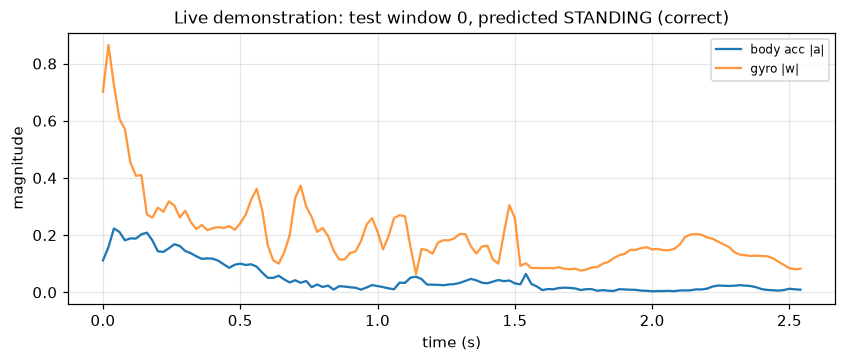

In [77]:
# author: Ahmad Abbas
split, index = "test", 0
# index = int(np.flatnonzero((subj_test == 12) & (y_test == ACTIVITIES.index("STANDING")))[0])

SPLITS = {"train": (X_train_raw, y_train, subj_train),
          "validation": (X_val_raw, y_val, subj_val),
          "test": (X_test_raw, y_test, subj_test)}
X_raw, y_true, subjects = SPLITS[split]

probs = classify(X_raw[index], demo_model)
predicted = int(probs.argmax())
verdict = "correct" if predicted == y_true[index] else "WRONG"
print(f"{split} window {index}: subject {subjects[index]}, true activity {ACTIVITIES[y_true[index]]}")
print(f"prediction: {ACTIVITIES[predicted]} ({probs[predicted]:.1%}) -> {verdict}\n")
for k in np.argsort(-probs):
    print(f"  {ACTIVITIES[k]:20} {probs[k]:6.1%}  {'#' * int(round(probs[k] * 40))}")

t = np.arange(WINDOW_LEN) / SAMPLING_HZ
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(t, magnitude(X_raw[index][None], 0)[0], label="body acc |a|")
ax.plot(t, magnitude(X_raw[index][None], 3)[0], alpha=0.8, label="gyro |w|")
ax.set_xlabel("time (s)")
ax.set_ylabel("magnitude")
ax.set_title(f"Live demonstration: {split} window {index}, predicted "
             f"{ACTIVITIES[predicted]} ({verdict})")
ax.legend(fontsize=8)
plt.show()